# Background

- **Author**: 柯典辰（B13303082）
- **Created At**: 2026-11-26
- **Updated At**: 2026-11-26（精確度統一至「整數分鐘」無條件捨去秒數，採嚴格 $\text{Exposure}^{\pm}_{i,s} \ge 1$ 分鐘口徑，並移除氣溫二次項 $\text{Temp}_s^2$）
- **Research Motivation and Context (why are we interested in the findings?)**：
  本分析對應主研究計畫書（`proposal/contents/chapter03.tex` 第 3.2 節）之核心計量模組：承接第 2 章以「局部庫存波谷遮罩（Local Inventory Trough Masking）」與電子票證刷卡流水還原之無偏借還最小充分統計量 $(Y^{\pm}_{i,s},\,\text{Exposure}^{\pm}_{i,s})$，建構**暴露量校正之高維固定效應負二項計數迴歸（Exposure-Adjusted Negative Binomial Fixed-Effects Regression, NB2-FE）**，分別針對**借車端（$Y^+_{i,s}$）**與**還車端（$Y^-_{i,s}$）**估計外生環境因素（學期、開學週、期中／期末考週之 24 小時分時倍率、線性連續氣溫、對數當期小時降雨量、大氣相對濕度及 77 日事前公開大型活動日）對潛在需求率之結構性影響，並輸出供第 3 章單站時變生滅佇列（$M_t/M_t/1/C_i$）與動態重平衡模擬器直接調用之參數資產。
  - **所有輸入資料皆以可攜相對路徑讀取自 `econ-5166-student-kit/data/processed/` 並於程式啟動時強制驗證 SHA-256 雜湊值**（將本 `.ipynb` 搬移回 `econ-5166-student-kit/finding/` 時完全無需修改路徑）：
    - 站點清單：`data/processed/stations_in_field.csv`
    - 站點小時票證流量面板：`data/processed/youbike_station_hourly_flow/youbike_station_hourly_flow_2024_2025.parquet`
    - 站點原始狀態更新紀錄（用於無條件捨去秒數重建整數分鐘級暴露）：`data/processed/youbike_rental/youbike_rental_in_field_2024.parquet`、`youbike_rental_in_field_2025.parquet`
    - 上游波谷缺失遮罩對照表（沿用 `no record yet` / `no-data day` / `stale > 24h` 判定）：`data/processed/youbike_trough_hourly/youbike_trough_hourly_2024.parquet`、`youbike_trough_hourly_2025.parquet`
    - 臺北站逐時氣象（含還原小時雨量 `rain_1h_mm`）：`data/processed/weather/weather_taipei_hourly_2024_2025.parquet`
    - 逐日學術日曆與大型活動事件表：`data/processed/calendar_2024.csv`、`data/processed/calendar_2025.csv`
- **Path to Training Data**: 2024 全年時間區塊（`2024-01-01` 至 `2024-12-31`，118 個有效運作站點；另切分 `2024-01~08` 訓練／`2024-09~12` 驗證作年內規格檢核）
- **Path to Testing Data**: 2025 全年獨立跨年度樣本外測試集（`2025-01-01` 至 `2025-12-31`；與 2024 共同運作之 118 站進行嚴格樣本外評估，2025 新啟用之 2 站另於全期 2024–2025 生產模型納入）
- **Model Specification**:
  - **Method**: 暴露量偏移負二項高維固定效應迴歸（NB2-FE，log-link，$\text{Var}(Y_{i,s}) = \mu_{i,s} + \alpha \mu_{i,s}^2$），並對照「站點 × 小時 × 實質工作日 × 學期」歷史分組均值基準（Historical Group Mean Baseline），另附設「保留 $\text{Temp}^2$ 二次項」與「常數正庫存補回 60 分鐘」敏感度消融檢核。
  - **Variables**:
    - 應變數：$Y^+_{i,s} = \texttt{rent\_total} - \texttt{rent\_invalid}$（排除 2025 年 8 月後始出現之 3 分鐘內同站短借 `d` 組）；還車端對稱設 $Y^-_{i,s} = \texttt{return\_total} - \texttt{return\_invalid}$。
    - 暴露偏移項（Offset）：將 TDX `SrcUpdateTime` **無條件捨去秒數至整數分鐘**重建之整數有效暴露分鐘數 $\text{Exposure}^+_{i,s} \in \{1, \dots, 59\}$ 與 $\text{Exposure}^-_{i,s} \in \{1, \dots, 60\}$（凡整小時無變動或整點開頭即觸底致 $\text{Exposure}^{\pm}_{i,s} = 0$ 者，嚴格依分母為 0 排除，不人工改寫為 60 分鐘）。
    - 固定效應（FE）：$\psi_{i,\,h(s),\,\text{Weekday}_s}$（站點 × 整點小時 × 實質工作日，2024 訓練集最高 5,664 組、全期 5,760 組；全年零交易組依法分離並令預測率為 0）。
    - 解釋變數（$K = 76$）：24 個分時學期倍率 $\phi_{h(s)}\text{Semester}_s$、24 個分時開學週偏移 $\phi^{\text{open}}_{h(s)}\text{Opening}_s$、24 個分時考週偏移 $\phi^{\text{exam}}_{h(s)}\text{Exam}_s$，以及 4 個連續與事件共變數 $\text{Temp}_s$、$\log(1 + \text{Precip}_s)$、$\text{HUMD}_s$、$\text{Event}_s$。
  - **Tuning Parameters**: 負二項過度離散參數 $\alpha > 0$（以 Profile MLE 透過 `scipy.optimize.minimize_scalar` Brent 法最佳化，不採測試集調參）。
  - **Optimization Method**: 精確稀疏 Schur-Complement 集中式 IRLS／Newton-Raphson 最大概似估計（收斂精度 $< 10^{-9}$，單元測試與 `statsmodels.GLM` 最大誤差 $6.65 \times 10^{-8}$）。標準誤同時計算 **HC1**、**日別群聚**及 **站點 × 日期雙向群聚（Two-Way CGM SE）**。
- **Main Findings and Takeaways**:
  - **分鐘級去秒成效**：無條件捨去秒數後，所有有效暴露時間皆嚴格為整數分鐘（0 筆次分鐘小數），原 `500101022 @ 2025-11-08 11:00`（原 `0.0833` 分）與 `500101001 @ 2025-12-11 07:00`（原 `0.0500` 分）均歸零排除；2025 借車端單小時最高觀測率由 `1,640 輛/分` 驟降至 `146 輛/分`，單筆最大加權平方誤差由 `147,632`（佔全年 6.69%）暴降 86% 至 `20,785`（佔 1.05%）；借車端過度離散參數 $\hat{\alpha}$ 亦由 `0.2050` 降至 **`0.1828`**（全期由 `0.2726` 降至 **`0.2418`**），模型收斂更乾淨。
  - **In-sample（2024 訓練集，118 站）**：借車端 NB2-FE（$N_{\text{est}}=753{,}963$）$\text{wRMSE}=0.1432$、$\text{wMAE}=0.0813$、$\text{w}R^2=0.7417$，較歷史分組均值基準（$\text{wRMSE}=0.1570$）誤差下降 **8.7%**；還車端 NB2-FE（$N_{\text{est}}=911{,}042$）$\text{wRMSE}=0.1149$、$\text{wMAE}=0.0524$、$\text{w}R^2=0.7762$，較基準（$0.1227$）下降 **6.3%**。
  - **Out-sample（2025 獨立跨年度原始預測 `TEST_2025_FULL_RAW`，118 共同站）**：借車端（$N=744{,}379$）$\text{wRMSE}=0.2583$（基準 $0.2730$，**-5.4%**）、$\text{wMAE}=0.1133$（基準 $0.1231$，**-8.0%**）、$\text{w}R^2=0.5830$；還車端（$N=988{,}207$）$\text{wRMSE}=0.1234$（基準 $0.1345$，**-8.3%**）、$\text{wMAE}=0.0580$（基準 $0.0627$，**-7.5%**）、$\text{w}R^2=0.8073$。
  - **移除氣溫二次項 $\text{Temp}_s^2$ 消融結論**：移除二次項後，線性 `Temp` 在借還兩端皆呈高度顯著（2024 借車 $+0.0316$、還車 $+0.0377$，雙向群聚 $z > 10.5, p < 10^{-25}$，每升 $5^\circ\text{C}$ 需求增 $+17.1\% / +20.7\%$）；在 2024 訓練集上甚至略勝含二次項模型（借車 $\text{wRMSE}$ `0.14325` vs `0.14329`），在 2025 樣本外測試與含二次項幾乎完全持平（借車 `0.25834` vs `0.25813`，差 `0.08%`；還車 `0.12344` vs `0.12303`，差 `0.33%`），代表移除二次項在不損失預測準確度的前提下大幅簡化模型並消除 2024 還車端二次項不顯著之困擾。
  - **其他核心參數（2024 訓練集，雙向群聚 SE，全數 $p < 0.01$）**：降雨 $\log(1+\text{Precip})$ 為 $-0.4104$（借）／$-0.4123$（還），1 mm/hr 降雨降需求 **24.8%–24.9%**；相對濕度 `HUMD` 為 $-0.6359$（借）／$-0.4266$（還）；大型活動 `Event` 為 $+0.1887$（借，`+20.8%`）／$+0.2114$（還，`+23.5%`）。
- **Future Direction**: 本 Notebook 輸出之 `outputs_nb_demand/` 參數表可直接輸入第 3 章 $M_t/M_t/1/C_i$ 非齊次生滅佇列與 DROB-I／DROB-T 動態重平衡模擬器。


In [1]:
from __future__ import annotations

import hashlib
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib import font_manager
from scipy import optimize, sparse, special
from scipy.stats import norm

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def setup_cjk_font() -> str:
    candidates = [
        "PingFang TC", "PingFang HK", "Heiti TC", "STHeiti",
        "Noto Sans TC", "Noto Sans CJK TC", "Microsoft JhengHei", "Arial Unicode MS",
    ]
    available = {f.name for f in font_manager.fontManager.ttflist}
    chosen = next((name for name in candidates if name in available), None)
    if chosen is None:
        raise RuntimeError("No Traditional Chinese font found on this system.")
    plt.rcParams.update({
        "font.family": chosen,
        "axes.unicode_minus": False,
        "figure.dpi": 130,
        "savefig.dpi": 220,
    })
    return chosen


def resolve_dssi_root(start: Path | None = None) -> Path:
    cwd = (start or Path.cwd()).resolve()
    for p in (cwd, *cwd.parents):
        if (p / "AGENTS.md").is_file() and (p / "templates").is_dir() and (p / "data" / "processed").is_dir():
            return p
    rel_guess = (cwd / "../../../../../../econ-5166-student-kit").resolve()
    if (rel_guess / "AGENTS.md").is_file() and (rel_guess / "data" / "processed").is_dir():
        return rel_guess
    for p in cwd.parents:
        cand = p / "econ-5166-student-kit"
        if (cand / "AGENTS.md").is_file() and (cand / "data" / "processed").is_dir():
            return cand
    raise FileNotFoundError(
        "無法定位專案根目錄 `econ-5166-student-kit/`（需含 AGENTS.md、templates/ 與 data/processed/）。"
    )


def resolve_output_dir(start: Path | None = None) -> Path:
    cwd = (start or Path.cwd()).resolve()
    out = cwd / "outputs_nb_demand"
    (out / "figures").mkdir(parents=True, exist_ok=True)
    return out


def verify_sha256(path: Path, expected_hex: str) -> str:
    if not path.is_file():
        raise FileNotFoundError(f"缺少必要輸入檔：{path}")
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual != expected_hex:
        raise ValueError(
            f"SHA-256 驗證失敗：{path.name}\n  expected={expected_hex}\n  actual  ={actual}"
        )
    return actual


CJK_FONT = setup_cjk_font()
DSSI_ROOT = resolve_dssi_root()
DATA_PROCESSED = DSSI_ROOT / "data" / "processed"
OUT_DIR = resolve_output_dir()
FIG_DIR = OUT_DIR / "figures"

# Verified SHA-256 bindings for every processed input file (FINDING-RULES.md Data Binding)
INPUT_SPECS = {
    "stations": (
        "stations_in_field.csv",
        "fbf0c1797ddbbe59de4852b077ce79dc8243ccc59f08caf4cff0ddfa5eba1ce4",
    ),
    "flow_hourly": (
        "youbike_station_hourly_flow/youbike_station_hourly_flow_2024_2025.parquet",
        "f2e21013892c58b9b5f93e347b4defb37999608ff45022003a0426840092dd23",
    ),
    "rental_2024": (
        "youbike_rental/youbike_rental_in_field_2024.parquet",
        "5c91e9b439f421bc41d7c247508bc9bdd01f7bac4e11e8887243cb6053d8b3b5",
    ),
    "rental_2025": (
        "youbike_rental/youbike_rental_in_field_2025.parquet",
        "d059c1457763ff8af3a327f52ddcc37262df2aa6370d1db6f7550b812b612a2e",
    ),
    "trough_2024": (
        "youbike_trough_hourly/youbike_trough_hourly_2024.parquet",
        "30e2e4381422c0b38062474c6037263c390b0b2c5ec763133ecafc81cea11760",
    ),
    "trough_2025": (
        "youbike_trough_hourly/youbike_trough_hourly_2025.parquet",
        "1532b91fc70e08dc3aa54248435a7b7dc0d3cf955743308fb8558a8225a15ffc",
    ),
    "weather": (
        "weather/weather_taipei_hourly_2024_2025.parquet",
        "c8e7fe27119fc322aa134f6f58d7ece5db7597209dcc622531316c0d83362b2a",
    ),
    "cal_2024": (
        "calendar_2024.csv",
        "0a803eeac7a1fea84c06eda5e7ed6f4fb2f086d0ae494a7af583c44be91544be",
    ),
    "cal_2025": (
        "calendar_2025.csv",
        "9dfb926aa48aeb770e7029b236221f78136885b793037a0e815f4ae2689f2686",
    ),
}

INPUT_PATHS: dict[str, Path] = {}
for key, (rel_path, expected_sha) in INPUT_SPECS.items():
    full_p = DATA_PROCESSED / rel_path
    verify_sha256(full_p, expected_sha)
    INPUT_PATHS[key] = full_p

print(f"CJK font      : {CJK_FONT}")
print(f"DSSI_ROOT     : {DSSI_ROOT.name} (resolved relative to cwd; {len(INPUT_PATHS)}/{len(INPUT_SPECS)} SHA-256 verified OK)")
print(f"OUT_DIR       : {OUT_DIR.name}/")


CJK font      : PingFang TC
DSSI_ROOT     : econ-5166-student-kit (resolved relative to cwd; 9/9 SHA-256 verified OK)
OUT_DIR       : outputs_nb_demand/


## 1. 資料特性、分鐘級暴露重建與防偏誤工程處理規範

在進行模型估計前，本程式嚴格落實研究計畫書第 2–3 章與 `econ-5166-student-kit` 文件所確立之 **七大資料特性與工程規範**：

1. **站點主檔去重與跨年站數差異**：`stations_in_field.csv` 含 125 筆「站點 × 位置」紀錄，壓回 120 個唯一 `StationID`。其中 `500119097`（臺大人文館，2025-02-04 啟用）與 `500101265`（羅斯福路三段283巷，2025-10-10 啟用）僅存於 2025 年，故 **2024 訓練集涵蓋 118 站、2025 測試集涵蓋 120 站**（跨年度嚴格樣本外測試僅於 118 個共同站評估）。
2. **票證交易跨年口徑對齊（剔除 `d` 組 3 分鐘內同站短借）**：應變數一律定義為 $Y^+_{i,s} = \texttt{rent\_total} - \texttt{rent\_invalid}$ 與 $Y^-_{i,s} = \texttt{return\_total} - \texttt{return\_invalid}$，確保 2024 與 2025 跨年口徑一致。
3. **TDX 狀態快照「無條件捨去秒數」重建整數分鐘級雙向暴露**：
   - TDX 設備回傳時間戳記 `SrcUpdateTime` 附帶數秒之傳輸／回傳時差（例如整點常落於 `11:00:05` 或 `07:00:03`）。若保留秒數直接積分，會把整點前 7–10 分鐘之舊狀態在開頭強行切出 `0.05`–`0.08` 分鐘（3–5 秒）之次分鐘殘片，導致分母極小而算出破千輛／分鐘之虛假觀測率。
   - 本程式直接讀取 SHA-256 驗證後之 `youbike_rental_in_field_{2024,2025}.parquet`，對所有 `SrcUpdateTime` **無條件捨去秒數（`floor("min")`）**，同分鐘內若有多筆回傳則保留該分鐘末筆確定狀態，再依與上游完全一致之整點繼承與缺值遮罩規則（`no record yet`、`no-data day`、`stale > 24h`）重建**純整數分鐘級**之 $\text{Exposure}^+_{i,s} \in \{0, 1, \dots, 59\}$ 與 $\text{Exposure}^-_{i,s} \in \{0, 1, \dots, 60\}$。
   - 依嚴格波谷定義，凡整小時狀態未變或整點開頭即觸底致整數有效暴露為 `0` 分鐘者（包含如 `500101022 @ 2025-11-08 11:00` 與 `500101001 @ 2025-12-11 07:00`），其分母嚴格為 `0` 而自估計與評估集排除，絕不人工改寫為 60 分鐘；每一筆進入模型之觀測值皆保證 $\text{Exposure}^{\pm}_{i,s} \in \mathbb{Z}_{\ge 1}$（最短恰為 $1$ 分鐘 $= 1/60$ 小時），徹底消除次分鐘分母毛刺。
4. **氣象時間區間方向校準（向後平移 1 小時）與移除氣溫二次項**：氣象檔 `datetime` 指向 $(t - 60\text{ 分}, t]$，併表前減去 1 小時以精確對齊 YouBike $[h, h+1)$ 區間，並保留原始 `NA` 不插補；主規格僅納入**線性氣溫 $\text{Temp}_s$**（移除 $\text{Temp}_s^2$，另於消融檢核對比其對 2025 樣本外預測之影響）。
5. **有效營運樣本篩選口徑**：統一採 `!is.na(trough_bikes)` 且 `minutes_stopped == 0` 作為整小時正常營運條件。
6. **跨源對帳剔除 TDX 全區集體中斷與無資料日 `00:00` 誤延用**：凡單小時全區滿足 `(n_usable > 0 & tot_upd == 0 & tot_rent >= 50)`、`(n_usable > 0 & tot_rent >= 100 & tot_upd / tot_rent < 0.05)` 或 `no-data day` 當日 `00:00`，全數剔除。
7. **臺大 16 週校曆 `Opening_s` 與 `Exam_s` 巢狀定義**：各學期第 1 週週一至週五為 `opening = 1`，第 8 週期中與第 16 週期末考週一至週五為 `exam = 1`，嚴格巢狀於 `semester = 1` 內且互斥。


In [2]:
t0 = time.perf_counter()

stations_raw = pd.read_csv(INPUT_PATHS["stations"], dtype={"StationUID": str, "StationID": str})
stations_meta = (
    stations_raw.sort_values("last_seen")
    .drop_duplicates("StationID", keep="last")
    .assign(station_name_short=lambda d: d["StationNameZh_tw"].str.removeprefix("YouBike2.0_"))
    [["StationID", "StationUID", "station_name_short", "PositionLat", "PositionLon", "first_seen", "last_seen"]]
    .rename(columns={"StationID": "station_id"})
    .sort_values("station_id")
    .reset_index(drop=True)
)
assert len(stations_meta) == 120, f"Expected 120 unique stations, got {len(stations_meta)}"
SORTED_SIDS = stations_meta["station_id"].tolist()
SID_TO_IDX = {s: i for i, s in enumerate(SORTED_SIDS)}


def build_minute_floored_trough(year: int) -> pd.DataFrame:
    '''Rebuild exact integer-minute trough & full exposure by truncating SrcUpdateTime seconds (floor to min).'''
    ts = time.perf_counter()
    orig = pd.read_parquet(
        INPUT_PATHS[f"trough_{year}"],
        columns=["station_id", "datetime", "trough_missing_reason", "exposure_rent_min", "exposure_return_min"],
    )
    orig["station_id"] = orig["station_id"].astype(str)
    orig = orig.sort_values(["station_id", "datetime"]).reset_index(drop=True)

    r = pd.read_parquet(
        INPUT_PATHS[f"rental_{year}"],
        columns=["StationID", "SrcUpdateTime", "AvailableRentBikes", "AvailableReturnBikes", "ServiceStatus"],
    )
    r["StationID"] = r["StationID"].astype(str)
    # Truncate seconds unconditionally (無條件捨去秒數 -> 精確至分鐘 HH:MM:00)
    r["min_ts"] = r["SrcUpdateTime"].dt.tz_localize(None).dt.floor("min")
    # If multiple updates fall in the same integer minute, retain the final settled status of that minute
    r = r.sort_values(["StationID", "SrcUpdateTime"]).drop_duplicates(["StationID", "min_ts"], keep="last")

    y0 = pd.Timestamp(f"{year}-01-01 00:00:00")
    n_hours = 8784 if year % 4 == 0 else 8760
    r["m_int"] = ((r["min_ts"] - y0).dt.total_seconds() // 60).astype(np.int32)
    r["is_full"] = (r["AvailableReturnBikes"] == 0).astype(np.int8)
    r["is_stopped"] = (r["ServiceStatus"] == "停止營運").astype(np.int8)

    hour_m = np.arange(n_hours, dtype=np.int32) * 60
    out_trough = np.full((120, n_hours), np.nan, dtype=np.float64)
    out_min_trough = np.full((120, n_hours), np.nan, dtype=np.float64)
    out_exp_rent = np.full((120, n_hours), np.nan, dtype=np.float64)
    out_min_full = np.full((120, n_hours), np.nan, dtype=np.float64)
    out_exp_ret = np.full((120, n_hours), np.nan, dtype=np.float64)
    out_min_stop = np.full((120, n_hours), np.nan, dtype=np.float64)
    out_n_upd = np.zeros((120, n_hours), dtype=np.int32)

    for sid, grp in r.groupby("StationID", sort=False):
        si = SID_TO_IDX[sid]
        m_arr = grp["m_int"].to_numpy(dtype=np.int32)
        b_arr = grp["AvailableRentBikes"].to_numpy(dtype=np.int32)
        f_arr = grp["is_full"].to_numpy(dtype=np.int8)
        st_arr = grp["is_stopped"].to_numpy(dtype=np.int8)

        snap_idx = np.searchsorted(m_arr, hour_m, side="right") - 1
        u_start = snap_idx + 1
        u_end = np.searchsorted(m_arr, hour_m + 60, side="left")
        out_n_upd[si] = u_end - u_start

        valid_h = snap_idx >= 0
        no_upd = valid_h & (u_start == u_end)
        idx0 = snap_idx[no_upd]
        out_trough[si, no_upd] = b_arr[idx0]
        out_min_trough[si, no_upd] = 60.0
        out_exp_rent[si, no_upd] = 0.0
        out_min_full[si, no_upd] = f_arr[idx0] * 60.0
        out_exp_ret[si, no_upd] = (1.0 - f_arr[idx0]) * 60.0
        out_min_stop[si, no_upd] = st_arr[idx0] * 60.0

        for h in np.flatnonzero(valid_h & (u_start < u_end)):
            s0 = snap_idx[h]
            us = u_start[h]
            ue = u_end[h]
            h0 = h * 60
            h1 = h0 + 60
            k = ue - us

            durs = np.empty(k + 1, dtype=np.int32)
            durs[0] = m_arr[us] - h0
            if k > 1:
                durs[1:k] = m_arr[us + 1 : ue] - m_arr[us : ue - 1]
            durs[k] = h1 - m_arr[ue - 1]

            bs = np.empty(k + 1, dtype=np.int32)
            bs[0] = b_arr[s0]
            bs[1:] = b_arr[us:ue]

            fs = np.empty(k + 1, dtype=np.int8)
            fs[0] = f_arr[s0]
            fs[1:] = f_arr[us:ue]

            sts = np.empty(k + 1, dtype=np.int8)
            sts[0] = st_arr[s0]
            sts[1:] = st_arr[us:ue]

            tb = int(bs.min())
            mt = int(durs[bs == tb].sum())
            mf = int(durs[fs == 1].sum())
            ms = int(durs[sts == 1].sum())

            out_trough[si, h] = tb
            out_min_trough[si, h] = mt
            out_exp_rent[si, h] = 60 - mt
            out_min_full[si, h] = mf
            out_exp_ret[si, h] = 60 - mf
            out_min_stop[si, h] = ms

    res = pd.DataFrame({
        "station_id": orig["station_id"],
        "datetime": orig["datetime"],
        "trough_missing_reason": orig["trough_missing_reason"],
        "trough_bikes": out_trough.ravel(),
        "minutes_at_trough": out_min_trough.ravel(),
        "exposure_rent_min": out_exp_rent.ravel(),
        "minutes_full": out_min_full.ravel(),
        "exposure_return_min": out_exp_ret.ravel(),
        "minutes_stopped": out_min_stop.ravel(),
        "n_updates": out_n_upd.ravel(),
        "orig_sec_exp_rent": orig["exposure_rent_min"],
    })
    miss = res["trough_missing_reason"].notna()
    for c in ["trough_bikes", "minutes_at_trough", "exposure_rent_min", "minutes_full", "exposure_return_min", "minutes_stopped"]:
        res.loc[miss, c] = np.nan

    # Hard assertions: EVERY exposure is an exact integer in {0, 1, ..., 60}, ZERO sub-minute fractions!
    ok = ~miss
    er = res.loc[ok, "exposure_rent_min"]
    ef = res.loc[ok, "exposure_return_min"]
    assert ((er - er.round()).abs() == 0).all(), "Non-integer rent exposure detected!"
    assert ((ef - ef.round()).abs() == 0).all(), "Non-integer return exposure detected!"
    assert ((er > 0) & (er < 1)).sum() == 0 and ((ef > 0) & (ef < 1)).sum() == 0
    print(f"[{year}] 分鐘級波谷與暴露重建完成 ({time.perf_counter()-ts:.2f}s) | 整數驗證通過 (0 筆小數分鐘) | exp_rent==0: {(er==0).sum():,} 筆")
    return res


trough = pd.concat([build_minute_floored_trough(2024), build_minute_floored_trough(2025)], ignore_index=True)

# Verify the exact two boundary cases reported by the user are now strictly 0 minutes
for sid, dts in [("500101022", "2025-11-08 11:00:00"), ("500101001", "2025-12-11 07:00:00")]:
    chk = trough[(trough["station_id"] == sid) & (trough["datetime"] == dts)].iloc[0]
    assert chk["exposure_rent_min"] == 0.0, f"Expected 0 min for {sid} @ {dts}, got {chk['exposure_rent_min']}"
    print(f"  邊界驗證 {sid} @ {dts}: 原秒級={chk['orig_sec_exp_rent']:.4f} 分 -> 去秒分鐘級={chk['exposure_rent_min']:.0f} 分 (嚴格排除)")

flow = pd.read_parquet(INPUT_PATHS["flow_hourly"])
wx = pd.read_parquet(INPUT_PATHS["weather"])
cal = pd.concat([pd.read_csv(INPUT_PATHS["cal_2024"]), pd.read_csv(INPUT_PATHS["cal_2025"])], ignore_index=True)

flow["station_id"] = flow["station_id"].astype(str)
assert len(flow) == 120 * 17544 == 2_105_280
assert len(trough) == 2_105_280
assert not flow.duplicated(["station_id", "datetime"]).any()
assert not trough.duplicated(["station_id", "datetime"]).any()
assert (flow["rent_total"] == flow["rent_to_field"] + flow["rent_to_outside"] + flow["rent_invalid"]).all()
assert (flow["return_total"] == flow["return_from_field"] + flow["return_from_outside"] + flow["return_invalid"]).all()

panel = flow.merge(
    trough.drop(columns=["orig_sec_exp_rent"]),
    on=["station_id", "datetime"],
    how="inner",
    validate="one_to_one",
)
del flow, trough
assert len(panel) == 2_105_280

# Weather -1h shift: (t - 60min, t] -> [h, h + 1)
assert str(wx["datetime"].dtype).startswith("datetime64")
wx["dt_aligned"] = (wx["datetime"].dt.tz_localize(None) - pd.Timedelta(hours=1)).dt.strftime("%Y-%m-%d %H:%M:%S")
assert not wx["dt_aligned"].duplicated().any()
assert (wx["Temp"].dropna() > -50).all()
assert ((wx["HUMD"].dropna() >= 0.0) & (wx["HUMD"].dropna() <= 1.0)).all()
assert (wx["rain_1h_mm"].dropna() >= 0.0).all()

panel = panel.merge(
    wx[["dt_aligned", "Temp", "HUMD", "D24R_trace", "rain", "rain_1h_mm"]],
    left_on="datetime",
    right_on="dt_aligned",
    how="left",
    validate="many_to_one",
).drop(columns=["dt_aligned"])

panel["date"] = panel["datetime"].str[:10]
panel["year"] = panel["datetime"].str[:4].astype(np.int16)
panel["month"] = panel["datetime"].str[5:7].astype(np.int8)
panel["hour"] = panel["datetime"].str[11:13].astype(np.int8)

assert len(cal) == 731 and not cal["date"].duplicated().any()
panel = panel.merge(
    cal[["date", "day_of_week", "weekday", "semester", "day_off_reason", "event", "event_tier", "event_scope", "event_name"]],
    on="date",
    how="left",
    validate="many_to_one",
)
assert panel[["weekday", "semester", "event"]].notna().all().all()

# Cross-year comparable counts: remove d-group <=3min same-station invalid trips
panel["y_rent"] = (panel["rent_total"] - panel["rent_invalid"]).astype(np.float64)
panel["y_ret"] = (panel["return_total"] - panel["return_invalid"]).astype(np.float64)

OPENING_RANGES = [
    ("2024-02-19", "2024-02-23"),
    ("2024-09-02", "2024-09-06"),
    ("2025-02-17", "2025-02-21"),
    ("2025-09-01", "2025-09-05"),
]
EXAM_RANGES = [
    ("2024-04-08", "2024-04-12"), ("2024-06-03", "2024-06-07"),
    ("2024-10-21", "2024-10-25"), ("2024-12-16", "2024-12-20"),
    ("2025-04-07", "2025-04-11"), ("2025-06-02", "2025-06-06"),
    ("2025-10-20", "2025-10-24"), ("2025-12-15", "2025-12-19"),
]


def flag_date_ranges(date_series: pd.Series, ranges: list[tuple[str, str]]) -> np.ndarray:
    mask = np.zeros(len(date_series), dtype=bool)
    for start_d, end_d in ranges:
        mask |= (date_series >= start_d) & (date_series <= end_d)
    return mask.astype(np.int8)


panel["opening"] = flag_date_ranges(panel["date"], OPENING_RANGES)
panel["exam"] = flag_date_ranges(panel["date"], EXAM_RANGES)
assert (panel.loc[panel["opening"] == 1, "semester"] == 1).all()
assert (panel.loc[panel["exam"] == 1, "semester"] == 1).all()
assert not ((panel["opening"] == 1) & (panel["exam"] == 1)).any()

panel["log1p_Precip"] = np.log1p(panel["rain_1h_mm"])

# Cross-source TDX blackout & no-data day 00:00 carryover detection
hr_agg = panel.groupby(["year", "date", "datetime", "hour"], as_index=False).agg(
    tot_rent=("y_rent", "sum"),
    tot_upd=("n_updates", "sum"),
    n_usable=("trough_bikes", lambda s: int(s.notna().sum())),
    n_nodata=("trough_missing_reason", lambda s: int((s == "no-data day").sum())),
)
nodata_dates = set(hr_agg.loc[hr_agg["n_nodata"] > 50, "date"])
blackout_mask_hr = (
    ((hr_agg["n_usable"] > 0) & (hr_agg["tot_upd"] == 0) & (hr_agg["tot_rent"] >= 50))
    | ((hr_agg["n_usable"] > 0) & (hr_agg["tot_rent"] >= 100) & (hr_agg["tot_upd"] / np.maximum(hr_agg["tot_rent"], 1) < 0.05))
    | ((hr_agg["date"].isin(nodata_dates)) & (hr_agg["hour"] == 0))
)
blackout_dts = set(hr_agg.loc[blackout_mask_hr, "datetime"])
panel["is_tdx_blackout"] = panel["datetime"].isin(blackout_dts)

panel["has_trough"] = panel["trough_bikes"].notna()
panel["is_full_normal_op"] = panel["has_trough"] & (panel["minutes_stopped"] == 0)
panel["has_complete_weather"] = panel["Temp"].notna() & panel["HUMD"].notna() & panel["rain_1h_mm"].notna()

# Strict integer-minute exposure (NO 0->60 override; denominator = 0 rows are strictly excluded!)
panel["exp_rent_eff"] = panel["exposure_rent_min"].copy()
panel["exp_ret_eff"] = panel["exposure_return_min"].copy()
# Auxiliary column retained ONLY for sensitivity comparison (CPI protection)
panel["is_const_pos_inv"] = (panel["exposure_rent_min"] == 0) & (panel["trough_bikes"] > 0)
panel["exp_rent_cpi"] = np.where(panel["is_const_pos_inv"], 60.0, panel["exposure_rent_min"])

base_clean = panel["is_full_normal_op"] & (~panel["is_tdx_blackout"]) & panel["has_complete_weather"]
panel["valid_rent"] = base_clean & (panel["exp_rent_eff"] >= 1.0)
panel["valid_ret"] = base_clean & (panel["exp_ret_eff"] >= 1.0)
panel["valid_rent_cpi"] = base_clean & (panel["exp_rent_cpi"] >= 1.0)

panel["lambda_obs"] = np.where(panel["valid_rent"], panel["y_rent"] / panel["exp_rent_eff"], np.nan)
panel["mu_obs"] = np.where(panel["valid_ret"], panel["y_ret"] / panel["exp_ret_eff"], np.nan)

audit_rows = []
for yr in (2024, 2025):
    s = panel[panel["year"] == yr]
    op = s["is_full_normal_op"]
    nb = op & (~s["is_tdx_blackout"])
    wx_ok = nb & s["has_complete_weather"]
    audit_rows.append({
        "year": yr,
        "total_grid_rows": len(s),
        "active_stations": int(s.loc[s["has_trough"], "station_id"].nunique()),
        "excl_missing_trough": int((~s["has_trough"]).sum()),
        "excl_stopped_gt0": int((s["has_trough"] & (s["minutes_stopped"] > 0)).sum()),
        "excl_tdx_blackout_rows": int((op & s["is_tdx_blackout"]).sum()),
        "excl_tdx_blackout_hours": int(s.loc[op & s["is_tdx_blackout"], "datetime"].nunique()),
        "excl_weather_na": int((nb & (~s["has_complete_weather"])).sum()),
        "excl_exp_rent_eq0_trough0": int((wx_ok & (s["exposure_rent_min"] == 0) & (s["trough_bikes"] == 0)).sum()),
        "excl_exp_rent_eq0_trough_pos": int((wx_ok & s["is_const_pos_inv"]).sum()),
        "final_valid_rent_N": int(s["valid_rent"].sum()),
        "excl_exp_ret_eq0_full": int((wx_ok & (s["exposure_return_min"] == 0)).sum()),
        "final_valid_ret_N": int(s["valid_ret"].sum()),
        "invalid_d_trips_removed": int(s["rent_invalid"].sum()),
    })

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(OUT_DIR / "data_audit_report.csv", index=False)
print(f"\nPanel built & audited in {time.perf_counter()-t0:.2f}s")
print("=== 表 1：2024（訓練集）與 2025（測試集）工程前處理與樣本篩選稽核表（整數分鐘級嚴格口徑） ===")
display(audit_df.T.rename(columns={0: "2024 (Train)", 1: "2025 (Test)"}))

train_2024 = panel[panel["year"] == 2024].copy()
test_2025 = panel[panel["year"] == 2025].copy()

PREVIEW_COLS = [
    "station_id", "datetime", "y_rent", "exp_rent_eff", "lambda_obs",
    "y_ret", "exp_ret_eff", "mu_obs", "weekday", "semester", "opening",
    "exam", "Temp", "rain_1h_mm", "HUMD", "event", "valid_rent", "valid_ret",
]
print("\n=== 訓練集（2024）前 10 筆有效觀測預覽 ===")
display(train_2024.loc[train_2024["valid_rent"], PREVIEW_COLS].head(10))


[2024] 分鐘級波谷與暴露重建完成 (7.96s) | 整數驗證通過 (0 筆小數分鐘) | exp_rent==0: 187,182 筆


[2025] 分鐘級波谷與暴露重建完成 (6.54s) | 整數驗證通過 (0 筆小數分鐘) | exp_rent==0: 262,258 筆
  邊界驗證 500101022 @ 2025-11-08 11:00:00: 原秒級=0.0833 分 -> 去秒分鐘級=0 分 (嚴格排除)
  邊界驗證 500101001 @ 2025-12-11 07:00:00: 原秒級=0.0500 分 -> 去秒分鐘級=0 分 (嚴格排除)



Panel built & audited in 17.79s
=== 表 1：2024（訓練集）與 2025（測試集）工程前處理與樣本篩選稽核表（整數分鐘級嚴格口徑） ===


,2024 (Train),2025 (Test)
year,2024,2025
total_grid_rows,1054080,1051200
active_stations,118,120
excl_missing_trough,106434,18970
excl_stopped_gt0,8399,203
excl_tdx_blackout_rows,10107,1667
excl_tdx_blackout_hours,89,14
excl_weather_na,6664,28325
excl_exp_rent_eq0_trough0,49006,41247
excl_exp_rent_eq0_trough_pos,119479,209878



=== 訓練集（2024）前 10 筆有效觀測預覽 ===


,station_id,datetime,y_rent,exp_rent_eff,lambda_obs,y_ret,exp_ret_eff,mu_obs,weekday,semester,opening,exam,Temp,rain_1h_mm,HUMD,event,valid_rent,valid_ret
1,500101001,2024-01-01 01:00:00,14.0000,13.0000,1.0769,11.0000,60.0000,0.1833,0,0,0,0,17.1000,0.0000,0.6300,0,True,True
2,500101001,2024-01-01 02:00:00,3.0000,18.0000,0.1667,4.0000,60.0000,0.0667,0,0,0,0,16.9000,0.0000,0.6500,0,True,True
3,500101001,2024-01-01 03:00:00,13.0000,49.0000,0.2653,9.0000,60.0000,0.1500,0,0,0,0,16.8000,0.0000,0.6500,0,True,True
4,500101001,2024-01-01 04:00:00,7.0000,32.0000,0.2188,6.0000,60.0000,0.1000,0,0,0,0,16.9000,0.0000,0.6500,0,True,True
5,500101001,2024-01-01 05:00:00,4.0000,11.0000,0.3636,4.0000,60.0000,0.0667,0,0,0,0,16.8000,0.0000,0.6400,0,True,True
6,500101001,2024-01-01 06:00:00,3.0000,38.0000,0.0789,3.0000,60.0000,0.0500,0,0,0,0,16.9000,0.0000,0.6600,0,True,True
7,500101001,2024-01-01 07:00:00,4.0000,52.0000,0.0769,8.0000,60.0000,0.1333,0,0,0,0,17.0000,0.0000,0.6500,0,True,True
8,500101001,2024-01-01 08:00:00,8.0000,56.0000,0.1429,17.0000,60.0000,0.2833,0,0,0,0,17.4000,0.0000,0.6400,0,True,True
9,500101001,2024-01-01 09:00:00,6.0000,59.0000,0.1017,9.0000,60.0000,0.1500,0,0,0,0,17.9000,0.0000,0.6200,0,True,True
10,500101001,2024-01-01 10:00:00,16.0000,56.0000,0.2857,11.0000,60.0000,0.1833,0,0,0,0,18.2000,0.0000,0.6000,0,True,True


In [3]:
train_stations_2024 = set(train_2024.loc[train_2024["valid_rent"], "station_id"].unique())
test_stations_2025 = set(test_2025.loc[test_2025["valid_rent"], "station_id"].unique())
new_2025_stations = sorted(test_stations_2025 - train_stations_2024)

print(f"2024 訓練集有效站數: {len(train_stations_2024)} 站")
print(f"2025 測試集有效站數: {len(test_stations_2025)} 站（跨年度共同評估站數: {len(train_stations_2024 & test_stations_2025)} 站）")
print(f"2025 新增啟用、2024 無站點固定效應之 2 站: {new_2025_stations}")
print("\n=== 測試集（2025）前 10 筆有效觀測預覽 ===")
display(test_2025.loc[test_2025["valid_rent"], PREVIEW_COLS].head(10))


2024 訓練集有效站數: 118 站
2025 測試集有效站數: 120 站（跨年度共同評估站數: 118 站）
2025 新增啟用、2024 無站點固定效應之 2 站: ['500101265', '500119097']

=== 測試集（2025）前 10 筆有效觀測預覽 ===


,station_id,datetime,y_rent,exp_rent_eff,lambda_obs,y_ret,exp_ret_eff,mu_obs,weekday,semester,opening,exam,Temp,rain_1h_mm,HUMD,event,valid_rent,valid_ret
8785,500101001,2025-01-01 01:00:00,16.0000,10.0000,1.6000,16.0000,60.0000,0.2667,0,0,0,0,16.1000,0.0000,0.6200,0,True,True
8786,500101001,2025-01-01 02:00:00,10.0000,8.0000,1.2500,11.0000,60.0000,0.1833,0,0,0,0,16.3000,0.0000,0.6200,0,True,True
8787,500101001,2025-01-01 03:00:00,10.0000,12.0000,0.8333,11.0000,60.0000,0.1833,0,0,0,0,16.2000,0.0000,0.6300,0,True,True
8788,500101001,2025-01-01 04:00:00,8.0000,17.0000,0.4706,4.0000,60.0000,0.0667,0,0,0,0,16.5000,0.0000,0.6600,0,True,True
8789,500101001,2025-01-01 05:00:00,14.0000,53.0000,0.2642,14.0000,60.0000,0.2333,0,0,0,0,16.6000,0.0000,0.6800,0,True,True
8790,500101001,2025-01-01 06:00:00,5.0000,22.0000,0.2273,5.0000,60.0000,0.0833,0,0,0,0,16.6000,0.0000,0.6900,0,True,True
8791,500101001,2025-01-01 07:00:00,19.0000,45.0000,0.4222,19.0000,60.0000,0.3167,0,0,0,0,17.0000,0.0000,0.6900,0,True,True
8792,500101001,2025-01-01 08:00:00,16.0000,51.0000,0.3137,15.0000,60.0000,0.2500,0,0,0,0,17.4000,0.0000,0.6700,0,True,True
8793,500101001,2025-01-01 09:00:00,23.0000,51.0000,0.4510,24.0000,60.0000,0.4000,0,0,0,0,17.6000,0.0000,0.7100,0,True,True
8794,500101001,2025-01-01 10:00:00,25.0000,58.0000,0.4310,24.0000,60.0000,0.4000,0,0,0,0,17.1000,0.0000,0.7900,0,True,True


In [4]:
def summarize_split(df_split: pd.DataFrame, split_label: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    num_vars = [
        ("y_rent", "自然借車次數 Y+ (次/時)"),
        ("exp_rent_eff", "借車有效暴露時間 Exposure+ (整數分)"),
        ("lambda_obs", "無偏觀測借車率 λ_obs (輛/分)"),
        ("y_ret", "自然還車次數 Y- (次/時)"),
        ("exp_ret_eff", "還車有效暴露時間 Exposure- (整數分)"),
        ("mu_obs", "無偏觀測還車率 μ_obs (輛/分)"),
        ("Temp", "小時氣溫 Temp (°C)"),
        ("rain_1h_mm", "當期小時降雨量 Precip (mm)"),
        ("log1p_Precip", "對數小時降雨量 log(1+Precip)"),
        ("HUMD", "大氣相對濕度 HUMD (0-1)"),
    ]
    num_rows = []
    base = df_split[df_split["is_full_normal_op"] & (~df_split["is_tdx_blackout"])]
    for col, label in num_vars:
        s = base[col]
        valid_s = s.dropna()
        num_rows.append({
            "變數名稱": label,
            "欄位": col,
            "有效 N": int(valid_s.shape[0]),
            "缺失 N": int(s.isna().sum()),
            "Mean": float(valid_s.mean()),
            "SD": float(valid_s.std(ddof=1)),
            "Min": float(valid_s.min()),
            "Q25": float(valid_s.quantile(0.25)),
            "Median": float(valid_s.median()),
            "Q75": float(valid_s.quantile(0.75)),
            "Max": float(valid_s.max()),
        })
    num_tbl = pd.DataFrame(num_rows)

    cat_vars = [
        ("weekday", "實質工作日 (Weekday)"),
        ("semester", "學期期間 (Semester)"),
        ("opening", "開學週 (Opening)"),
        ("exam", "期中/期末考週 (Exam)"),
        ("event", "大型活動日 (Event)"),
        ("event_tier", "活動分級 (Event Tier)"),
        ("event_scope", "活動空間範疇 (Event Scope)"),
    ]
    cat_rows = []
    valid_base = df_split[df_split["valid_rent"]]
    for col, label in cat_vars:
        s = valid_base[col]
        n_nonmiss = int(s.notna().sum())
        n_miss = int(s.isna().sum())
        vc = s.value_counts(dropna=True).head(10)
        for cat_val, cnt in vc.items():
            cat_rows.append({
                "變數名稱": label,
                "類別值": str(cat_val),
                "次數 (Count)": int(cnt),
                "佔非缺值比例 (%)": 100.0 * cnt / max(n_nonmiss, 1),
                "非缺值總 N": n_nonmiss,
                "缺失 N": n_miss,
            })
    cat_tbl = pd.DataFrame(cat_rows)

    print(f"\n=== [{split_label}] 連續變數敘述統計（基準：正常營運且非 TDX 斷線站時，總列數 = {len(base):,}） ===")
    display(num_tbl)
    print(f"\n=== [{split_label}] 類別／指標變數分佈（分母：借車有效估計樣本非缺值總 N = {len(valid_base):,}） ===")
    display(cat_tbl)
    return num_tbl, cat_tbl


num_train_tbl, cat_train_tbl = summarize_split(train_2024, "TRAINING DATA: 2024")
num_test_tbl, cat_test_tbl = summarize_split(test_2025, "TESTING DATA: 2025")
num_train_tbl.to_csv(OUT_DIR / "desc_numeric_train_2024.csv", index=False)
num_test_tbl.to_csv(OUT_DIR / "desc_numeric_test_2025.csv", index=False)
cat_train_tbl.to_csv(OUT_DIR / "desc_categorical_train_2024.csv", index=False)
cat_test_tbl.to_csv(OUT_DIR / "desc_categorical_test_2025.csv", index=False)



=== [TRAINING DATA: 2024] 連續變數敘述統計（基準：正常營運且非 TDX 斷線站時，總列數 = 929,140） ===


,變數名稱,欄位,有效 N,缺失 N,Mean,SD,Min,Q25,Median,Q75,Max
0,自然借車次數 Y+ (次/時),y_rent,929140,0,7.0200,12.8498,0.0000,0.0000,3.0000,9.0000,275.0000
1,借車有效暴露時間 Exposure+ (整數分),exp_rent_eff,929140,0,35.0174,22.1101,0.0000,14.0000,43.0000,55.0000,59.0000
2,無偏觀測借車率 λ_obs (輛/分),lambda_obs,753991,175149,0.2011,0.2913,0.0000,0.0400,0.1154,0.2500,29.0000
3,自然還車次數 Y- (次/時),y_ret,929140,0,6.8301,13.4327,0.0000,0.0000,3.0000,8.0000,374.0000
4,還車有效暴露時間 Exposure- (整數分),exp_ret_eff,929140,0,56.7441,10.7079,0.0000,60.0000,60.0000,60.0000,60.0000
5,無偏觀測還車率 μ_obs (輛/分),mu_obs,912531,16609,0.1331,0.2778,0.0000,0.0000,0.0500,0.1500,54.0000
6,小時氣溫 Temp (°C),Temp,924469,4671,24.0603,5.9294,7.5000,19.2000,25.0000,28.6000,36.9000
7,當期小時降雨量 Precip (mm),rain_1h_mm,922476,6664,0.2401,1.8881,0.0000,0.0000,0.0000,0.0000,46.0000
8,對數小時降雨量 log(1+Precip),log1p_Precip,922476,6664,0.0744,0.3389,0.0000,0.0000,0.0000,0.0000,3.8501
9,大氣相對濕度 HUMD (0-1),HUMD,924469,4671,0.7688,0.1271,0.1700,0.6800,0.7800,0.8700,0.9900



=== [TRAINING DATA: 2024] 類別／指標變數分佈（分母：借車有效估計樣本非缺值總 N = 753,991） ===


,變數名稱,類別值,次數 (Count),佔非缺值比例 (%),非缺值總 N,缺失 N
0,實質工作日 (Weekday),1,512582,67.9825,753991,0
1,實質工作日 (Weekday),0,241409,32.0175,753991,0
2,學期期間 (Semester),1,497666,66.0042,753991,0
3,學期期間 (Semester),0,256325,33.9958,753991,0
4,開學週 (Opening),0,732242,97.1155,753991,0
5,開學週 (Opening),1,21749,2.8845,753991,0
6,期中/期末考週 (Exam),0,708579,93.9771,753991,0
7,期中/期末考週 (Exam),1,45412,6.0229,753991,0
8,大型活動日 (Event),0,666860,88.4440,753991,0
9,大型活動日 (Event),1,87131,11.5560,753991,0



=== [TESTING DATA: 2025] 連續變數敘述統計（基準：正常營運且非 TDX 斷線站時，總列數 = 1,030,360） ===


,變數名稱,欄位,有效 N,缺失 N,Mean,SD,Min,Q25,Median,Q75,Max
0,自然借車次數 Y+ (次/時),y_rent,1030360,0,8.6735,14.8504,0.0000,1.0000,4.0000,11.0000,283.0000
1,借車有效暴露時間 Exposure+ (整數分),exp_rent_eff,1030360,0,29.6588,22.2490,0.0000,0.0000,34.0000,50.0000,59.0000
2,無偏觀測借車率 λ_obs (輛/分),lambda_obs,750910,279450,0.3112,0.7169,0.0000,0.0600,0.1667,0.3621,146.0000
3,自然還車次數 Y- (次/時),y_ret,1030360,0,8.4502,15.7418,0.0000,0.0000,3.0000,10.0000,380.0000
4,還車有效暴露時間 Exposure- (整數分),exp_ret_eff,1030360,0,57.8596,8.2739,0.0000,60.0000,60.0000,60.0000,60.0000
5,無偏觀測還車率 μ_obs (輛/分),mu_obs,997627,32733,0.1579,0.3042,0.0000,0.0167,0.0667,0.1833,25.0000
6,小時氣溫 Temp (°C),Temp,1011844,18516,24.0991,6.1220,8.3000,19.2000,24.6000,29.1000,36.6000
7,當期小時降雨量 Precip (mm),rain_1h_mm,1002154,28206,0.2422,1.6064,0.0000,0.0000,0.0000,0.0000,54.5000
8,對數小時降雨量 log(1+Precip),log1p_Precip,1002154,28206,0.0885,0.3476,0.0000,0.0000,0.0000,0.0000,4.0164
9,大氣相對濕度 HUMD (0-1),HUMD,1011844,18516,0.7343,0.1335,0.1200,0.6400,0.7400,0.8400,0.9800



=== [TESTING DATA: 2025] 類別／指標變數分佈（分母：借車有效估計樣本非缺值總 N = 750,910） ===


,變數名稱,類別值,次數 (Count),佔非缺值比例 (%),非缺值總 N,缺失 N
0,實質工作日 (Weekday),1,519414,69.1713,750910,0
1,實質工作日 (Weekday),0,231496,30.8287,750910,0
2,學期期間 (Semester),1,487167,64.8769,750910,0
3,學期期間 (Semester),0,263743,35.1231,750910,0
4,開學週 (Opening),0,731201,97.3753,750910,0
5,開學週 (Opening),1,19709,2.6247,750910,0
6,期中/期末考週 (Exam),0,711975,94.8150,750910,0
7,期中/期末考週 (Exam),1,38935,5.1850,750910,0
8,大型活動日 (Event),0,675153,89.9113,750910,0
9,大型活動日 (Event),1,75757,10.0887,750910,0


### The actual modeling starts below

本節依序執行：
1. **精確稀疏 Schur-Complement NB2-FE 求解器定義與 `statsmodels.GLM` 數值等價性單元測試**（確保係數、固定效應、對數概似值與群聚穩健標準誤達 $10^{-8}$ 級精確度）。
2. **主模型估計（$K = 76$，分鐘級嚴格暴露＋線性氣溫 $\text{Temp}_s$）**：分別估計 2024 訓練集與 2024–2025 全期生產模型之**借車端（$Y^+$）**與**還車端（$Y^-$）**，並加跑消融對照（保留 $\text{Temp}^2$ 二次項 vs. 移除 $\text{Temp}^2$、以及是否啟用常數正庫存 60 分鐘補回）。
3. **係數視覺化（含 95% 雙向群聚信賴區間）**：24 小時學期／開學週／考週倍率曲線、線性氣溫反應曲線、降雨衰減曲線與濕度／活動衝擊森林圖。
4. **獨立之訓練集（2024）、年內驗證（2024 Q3–Q4）與跨年度樣本外測試集（2025）績效評估**：以暴露時間加權 MSE、RMSE、MAE 及三聯診斷圖對比 NB2-FE 與歷史分組均值基準。


In [5]:
def nb2_loglik(y: np.ndarray, mu: np.ndarray, alpha: float) -> float:
    r = 1.0 / alpha
    mu_safe = np.maximum(mu, 1e-300)
    return float(np.sum(
        special.gammaln(y + r) - special.gammaln(r) - special.gammaln(y + 1.0)
        + r * np.log(r / (r + mu_safe))
        + y * np.log(mu_safe / (r + mu_safe))
    ))


def poisson_loglik(y: np.ndarray, mu: np.ndarray) -> float:
    mu_safe = np.maximum(mu, 1e-300)
    return float(np.sum(y * np.log(mu_safe) - mu_safe - special.gammaln(y + 1.0)))


def build_design_matrix_sparse(
    df_in: pd.DataFrame, include_temp_sq: bool = False
) -> tuple[sparse.csc_matrix, list[str]]:
    '''Build sparse regressor matrix: K=76 (linear Temp, primary) or K=77 (with Temp_sq, ablation).'''
    N = len(df_in)
    h = df_in["hour"].to_numpy(dtype=np.int32)
    sem = df_in["semester"].to_numpy(dtype=np.float64)
    opn = df_in["opening"].to_numpy(dtype=np.float64)
    exm = df_in["exam"].to_numpy(dtype=np.float64)
    temp = df_in["Temp"].to_numpy(dtype=np.float64)
    precip = np.log1p(df_in["rain_1h_mm"].to_numpy(dtype=np.float64))
    humd = df_in["HUMD"].to_numpy(dtype=np.float64)
    ev = df_in["event"].to_numpy(dtype=np.float64)

    rows_list, cols_list, vals_list = [], [], []
    for offset_c, vec in [(0, sem), (24, opn), (48, exm)]:
        nz = np.flatnonzero(vec != 0.0)
        rows_list.append(nz.astype(np.int32))
        cols_list.append(h[nz] + offset_c)
        vals_list.append(vec[nz])

    if include_temp_sq:
        cont_specs = [(72, temp, "Temp"), (73, temp ** 2, "Temp_sq"), (74, precip, "log1p_Precip"), (75, humd, "HUMD"), (76, ev, "Event")]
        K_tot = 77
    else:
        cont_specs = [(72, temp, "Temp"), (73, precip, "log1p_Precip"), (74, humd, "HUMD"), (75, ev, "Event")]
        K_tot = 76

    for col_c, vec, _ in cont_specs:
        nz = np.flatnonzero(vec != 0.0)
        rows_list.append(nz.astype(np.int32))
        cols_list.append(np.full(len(nz), col_c, dtype=np.int32))
        vals_list.append(vec[nz])

    X_sp = sparse.csc_matrix(
        (np.concatenate(vals_list), (np.concatenate(rows_list), np.concatenate(cols_list))),
        shape=(N, K_tot),
        dtype=np.float64,
    )
    names = (
        [f"sem_h{hh:02d}" for hh in range(24)]
        + [f"open_h{hh:02d}" for hh in range(24)]
        + [f"exam_h{hh:02d}" for hh in range(24)]
        + [nm for _, _, nm in cont_specs]
    )
    return X_sp, names


def fit_nb2_fe_core(
    y: np.ndarray,
    X: sparse.csc_matrix | np.ndarray,
    offset: np.ndarray,
    g_idx: np.ndarray,
    G: int,
    alpha: float,
    Z: sparse.csc_matrix | None = None,
    theta_init: np.ndarray | None = None,
    psi_init: np.ndarray | None = None,
    max_iter: int = 50,
    tol: float = 1e-9,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, int]:
    N, K = X.shape
    X_sp = X if sparse.issparse(X) else sparse.csc_matrix(X)
    if Z is None:
        Z = sparse.csc_matrix((np.ones(N, dtype=np.float64), (np.arange(N), g_idx)), shape=(N, G))

    col_sq_mean = np.asarray(X_sp.power(2).mean(axis=0)).ravel()
    x_scale = np.sqrt(np.maximum(col_sq_mean, 1e-12))
    Xs = X_sp @ sparse.diags(1.0 / x_scale)

    theta = np.zeros(K, dtype=np.float64) if theta_init is None else (theta_init * x_scale).copy()
    if psi_init is None:
        sum_y = np.asarray(Z.T @ y).ravel()
        sum_e = np.asarray(Z.T @ np.exp(offset)).ravel()
        psi = np.log(np.maximum(sum_y, 1e-6) / np.maximum(sum_e, 1e-6))
    else:
        psi = psi_init.copy()

    def eval_ll(mu_arr: np.ndarray) -> float:
        return poisson_loglik(y, mu_arr) if alpha == 0.0 else nb2_loglik(y, mu_arr, alpha)

    eta = offset + psi[g_idx] + Xs @ theta
    mu = np.exp(np.clip(eta, -30.0, 20.0))
    ll = eval_ll(mu)

    for it in range(max_iter):
        denom = 1.0 + alpha * mu
        score = (y - mu) / denom
        w = mu / denom
        w_g = np.asarray(Z.T @ w).ravel()
        inv_wg = 1.0 / w_g

        W_diag = sparse.diags(w)
        WXs = W_diag @ Xs
        XtWX = (Xs.T @ WXs).toarray()
        sum_WX = (Z.T @ WXs).toarray()
        H = XtWX - (sum_WX.T * inv_wg) @ sum_WX

        sum_s_g = np.asarray(Z.T @ score).ravel()
        grad_theta = np.asarray(Xs.T @ score).ravel() - sum_WX.T @ (sum_s_g * inv_wg)

        try:
            d_theta = np.linalg.solve(H, grad_theta)
        except np.linalg.LinAlgError:
            d_theta = np.linalg.lstsq(H, grad_theta, rcond=None)[0]

        d_psi = (sum_s_g - sum_WX @ d_theta) * inv_wg

        step = 1.0
        for _ in range(15):
            th_n = theta + step * d_theta
            ps_n = psi + step * d_psi
            eta_n = offset + ps_n[g_idx] + Xs @ th_n
            mu_n = np.exp(np.clip(eta_n, -30.0, 20.0))
            ll_n = eval_ll(mu_n)
            if ll_n >= ll - 1e-9:
                break
            step *= 0.5

        max_d = max(float(np.max(np.abs(step * d_theta))), float(np.max(np.abs(step * d_psi))))
        theta, psi, eta, mu, ll = th_n, ps_n, eta_n, mu_n, ll_n
        if max_d < tol:
            break

    return theta / x_scale, psi, mu, ll, it + 1


def compute_robust_se(
    y: np.ndarray,
    X: sparse.csc_matrix | np.ndarray,
    mu: np.ndarray,
    g_idx: np.ndarray,
    G: int,
    alpha: float,
    Z: sparse.csc_matrix,
    station_ids: np.ndarray,
    dates: np.ndarray,
) -> dict[str, np.ndarray | int]:
    N, K = X.shape
    X_sp = X if sparse.issparse(X) else sparse.csc_matrix(X)
    denom = 1.0 + alpha * mu
    score = (y - mu) / denom
    w_obs = mu * (1.0 + alpha * y) / (denom ** 2)
    w_g = np.asarray(Z.T @ w_obs).ravel()
    inv_wg = 1.0 / w_g

    WX = sparse.diags(w_obs) @ X_sp
    sum_WX = (Z.T @ WX).toarray()
    mean_X_g = sum_WX * inv_wg[:, None]
    H_obs = (X_sp.T @ WX).toarray() - sum_WX.T @ mean_X_g
    bread = np.linalg.inv(H_obs)

    s2 = score ** 2
    S2X = sparse.diags(s2) @ X_sp
    X_s2_X = (X_sp.T @ S2X).toarray()
    Z_s2_X = (Z.T @ S2X).toarray()
    sum_s2_g = np.asarray(Z.T @ s2).ravel()
    cross = Z_s2_X.T @ mean_X_g
    meat_hc0 = X_s2_X - cross - cross.T + (mean_X_g.T * sum_s2_g) @ mean_X_g
    dof_hc1 = N / max(N - G - K, 1)
    V_hc1 = dof_hc1 * (bread @ meat_hc0 @ bread)

    SX = sparse.diags(score) @ X_sp
    SZ = sparse.diags(score) @ Z

    def cl_vcov_from_codes(codes: np.ndarray, C: int) -> np.ndarray:
        Zc = sparse.csc_matrix((np.ones(N, dtype=np.float64), (np.arange(N), codes)), shape=(N, C))
        Uc = (Zc.T @ SX).toarray() - (Zc.T @ SZ) @ mean_X_g
        adj = (C / max(C - 1, 1)) * ((N - 1) / max(N - G - K, 1))
        return adj * (bread @ (Uc.T @ Uc) @ bread)

    _, stn_codes = np.unique(station_ids, return_inverse=True)
    _, dt_codes = np.unique(dates, return_inverse=True)
    C_stn = int(stn_codes.max()) + 1
    C_dt = int(dt_codes.max()) + 1
    sd_raw = stn_codes.astype(np.int64) * C_dt + dt_codes.astype(np.int64)
    _, sd_codes = np.unique(sd_raw, return_inverse=True)
    C_sd = int(sd_codes.max()) + 1

    V_stn = cl_vcov_from_codes(stn_codes, C_stn)
    V_dt = cl_vcov_from_codes(dt_codes, C_dt)
    V_sd = cl_vcov_from_codes(sd_codes, C_sd)

    V_2way = V_stn + V_dt - V_sd
    eigvals, eigvecs = np.linalg.eigh(V_2way)
    V_2way_psd = (eigvecs * np.maximum(eigvals, 0.0)) @ eigvecs.T

    return {
        "se_model": np.sqrt(np.maximum(np.diag(bread), 0.0)),
        "se_hc1": np.sqrt(np.maximum(np.diag(V_hc1), 0.0)),
        "se_station": np.sqrt(np.maximum(np.diag(V_stn), 0.0)),
        "se_date": np.sqrt(np.maximum(np.diag(V_dt), 0.0)),
        "se_2way": np.sqrt(np.maximum(np.diag(V_2way_psd), 0.0)),
        "n_clusters_station": C_stn,
        "n_clusters_date": C_dt,
        "n_clusters_stn_date": C_sd,
    }


def add_sig_stars(p: np.ndarray) -> list[str]:
    out = []
    for pv in p:
        if pv < 0.01:
            out.append("***")
        elif pv < 0.05:
            out.append("**")
        elif pv < 0.10:
            out.append("*")
        else:
            out.append("")
    return out


def fit_nb2_fe_model(
    sub_df: pd.DataFrame,
    y_col: str,
    exp_col: str,
    model_name: str,
    include_temp_sq: bool = False,
    run_poisson_lr: bool = True,
) -> dict:
    t0 = time.perf_counter()
    d = sub_df.copy()
    d["fe_key"] = d["station_id"] + "_" + d["hour"].astype(str).str.zfill(2) + "_" + d["weekday"].astype(str)

    fe_sum_y = d.groupby("fe_key")[y_col].transform("sum")
    zero_mask = fe_sum_y == 0
    zero_fe_keys = set(d.loc[zero_mask, "fe_key"].unique())
    n_zero_rows = int(zero_mask.sum())

    est = d[~zero_mask].reset_index(drop=True)
    fe_cats, g_idx = np.unique(est["fe_key"].to_numpy(), return_inverse=True)
    G = len(fe_cats)
    N = len(est)
    y = est[y_col].to_numpy(dtype=np.float64)
    exp_min = est[exp_col].to_numpy(dtype=np.float64)
    offset = np.log(exp_min)
    X_sp, names = build_design_matrix_sparse(est, include_temp_sq=include_temp_sq)
    K = X_sp.shape[1]
    Z = sparse.csc_matrix((np.ones(N, dtype=np.float64), (np.arange(N), g_idx)), shape=(N, G))

    sum_y_g = np.asarray(Z.T @ y).ravel()
    sum_e_g = np.asarray(Z.T @ exp_min).ravel()
    cache = {
        "theta": np.zeros(K, dtype=np.float64),
        "psi": np.log(np.maximum(sum_y_g, 1e-6) / np.maximum(sum_e_g, 1e-6)),
    }

    def neg_profile_ll(log_a: float) -> float:
        a_val = float(np.exp(log_a))
        th, ps, _, ll_v, _ = fit_nb2_fe_core(
            y, X_sp, offset, g_idx, G, a_val, Z=Z,
            theta_init=cache["theta"], psi_init=cache["psi"], max_iter=20, tol=1e-6,
        )
        cache["theta"], cache["psi"] = th, ps
        return -ll_v

    opt = optimize.minimize_scalar(
        neg_profile_ll, bounds=(np.log(1e-3), np.log(5.0)), method="bounded", options={"xatol": 2e-3}
    )
    alpha_hat = float(np.exp(opt.x))
    theta_hat, psi_hat, mu_hat, ll_nb, n_iter = fit_nb2_fe_core(
        y, X_sp, offset, g_idx, G, alpha_hat, Z=Z,
        theta_init=cache["theta"], psi_init=cache["psi"], max_iter=40, tol=1e-9,
    )

    ll_pois, lr_stat_overdisp = np.nan, np.nan
    if run_poisson_lr:
        _, _, _, ll_pois, _ = fit_nb2_fe_core(
            y, X_sp, offset, g_idx, G, 0.0, Z=Z,
            theta_init=theta_hat, psi_init=psi_hat, max_iter=25, tol=1e-7,
        )
        lr_stat_overdisp = 2.0 * (ll_nb - ll_pois)

    ses = compute_robust_se(
        y, X_sp, mu_hat, g_idx, G, alpha_hat, Z,
        est["station_id"].to_numpy(), est["date"].to_numpy(),
    )

    z_hc1 = theta_hat / ses["se_hc1"]
    p_hc1 = 2.0 * norm.sf(np.abs(z_hc1))
    z_dt = theta_hat / ses["se_date"]
    p_dt = 2.0 * norm.sf(np.abs(z_dt))
    z_2w = theta_hat / ses["se_2way"]
    p_2w = 2.0 * norm.sf(np.abs(z_2w))

    coef_df = pd.DataFrame({
        "model": model_name,
        "variable": names,
        "coef": theta_hat,
        "irr": np.exp(theta_hat),
        "pct_change": (np.exp(theta_hat) - 1.0) * 100.0,
        "se_hc1": ses["se_hc1"],
        "p_hc1": p_hc1,
        "se_date": ses["se_date"],
        "z_date": z_dt,
        "p_date": p_dt,
        "se_2way": ses["se_2way"],
        "z_2way": z_2w,
        "p_2way": p_2w,
        "ci95_low_2way": theta_hat - 1.96 * ses["se_2way"],
        "ci95_high_2way": theta_hat + 1.96 * ses["se_2way"],
        "sig_2way": add_sig_stars(p_2w),
    })

    fe_rows = []
    for fk, pv in zip(fe_cats, psi_hat):
        sid, hh, wd = fk.split("_")
        fe_rows.append({"station_id": sid, "hour": int(hh), "weekday": int(wd), "fe_key": fk, "psi": float(pv), "is_zero_fe": False})
    for fk in sorted(zero_fe_keys):
        sid, hh, wd = fk.split("_")
        fe_rows.append({"station_id": sid, "hour": int(hh), "weekday": int(wd), "fe_key": fk, "psi": np.nan, "is_zero_fe": True})
    fe_df = pd.DataFrame(fe_rows).sort_values(["station_id", "weekday", "hour"]).reset_index(drop=True)

    meta = {
        "model": model_name,
        "include_temp_sq": include_temp_sq,
        "N_total_valid": len(d),
        "N_est": N,
        "N_zero_fe_rows": n_zero_rows,
        "G_fe_estimated": G,
        "G_fe_zero_separated": len(zero_fe_keys),
        "K_regressors": K,
        "outcome_mean_count": float(y.mean()),
        "outcome_mean_rate_per_min": float((y / exp_min).mean()),
        "alpha": alpha_hat,
        "theta_nb": 1.0 / alpha_hat,
        "loglik_nb2": ll_nb,
        "loglik_poisson": ll_pois,
        "lr_overdispersion": lr_stat_overdisp,
        "aic_nb2": 2.0 * (G + K + 1) - 2.0 * ll_nb,
        "n_clusters_station": int(ses["n_clusters_station"]),
        "n_clusters_date": int(ses["n_clusters_date"]),
        "elapsed_sec": round(time.perf_counter() - t0, 2),
    }
    print(
        f"[{model_name}] N_est={N:,} (+{n_zero_rows:,} zero-FE across {len(zero_fe_keys)} cells) | "
        f"G_fe={G:,} | K={K} | mean(Y)={meta['outcome_mean_count']:.3f} | alpha={alpha_hat:.4f} | "
        f"LR(vs Pois)={lr_stat_overdisp:,.1f} | time={meta['elapsed_sec']:.2f}s"
    )
    return {
        "meta": meta,
        "coef_df": coef_df,
        "fe_df": fe_df,
        "theta": theta_hat,
        "names": names,
        "include_temp_sq": include_temp_sq,
        "psi_map": dict(zip(fe_cats, psi_hat)),
        "zero_fe_keys": zero_fe_keys,
        "alpha": alpha_hat,
    }


def predict_rate_nb2_fe(model: dict, df_new: pd.DataFrame) -> np.ndarray:
    fe_keys = (
        df_new["station_id"] + "_" + df_new["hour"].astype(str).str.zfill(2) + "_" + df_new["weekday"].astype(str)
    )
    X_new, _ = build_design_matrix_sparse(df_new, include_temp_sq=model["include_temp_sq"])
    lin_x = np.asarray(X_new @ model["theta"]).ravel()

    psi_map = model["psi_map"]
    zero_set = model["zero_fe_keys"]
    psi_vals = np.full(len(df_new), np.nan, dtype=np.float64)
    is_zero = np.zeros(len(df_new), dtype=bool)
    for i, fk in enumerate(fe_keys.to_numpy()):
        if fk in psi_map:
            psi_vals[i] = psi_map[fk]
        elif fk in zero_set:
            is_zero[i] = True

    pred_rate = np.exp(np.clip(psi_vals + lin_x, -30.0, 15.0))
    pred_rate[is_zero] = 0.0
    return pred_rate


# --- Unit Test: Verify exact solver equivalence vs statsmodels.GLM ---
rng = np.random.default_rng(2026)
Nt, Gt, Kt = 1500, 10, 4
gt = rng.integers(0, Gt, size=Nt)
Xt = rng.normal(size=(Nt, Kt))
offt = np.log(rng.uniform(15.0, 60.0, size=Nt))
at = 0.45
mut = np.exp(offt + rng.normal(-2.0, 0.5, size=Gt)[gt] + Xt @ np.array([0.25, -0.35, 0.12, -0.18]))
yt = rng.negative_binomial(1.0 / at, (1.0 / at) / (1.0 / at + mut)).astype(np.float64)
clt = rng.integers(0, 30, size=Nt)

Zt = sparse.csc_matrix((np.ones(Nt), (np.arange(Nt), gt)), shape=(Nt, Gt))
th_u, ps_u, mu_u, ll_u, it_u = fit_nb2_fe_core(yt, Xt, offt, gt, Gt, at, Z=Zt)
sm_fit = sm.GLM(yt, np.hstack([Xt, np.eye(Gt)[gt]]), family=sm.families.NegativeBinomial(alpha=at), offset=offt).fit(
    cov_type="cluster", cov_kwds={"groups": clt}
)
se_u = compute_robust_se(yt, Xt, mu_u, gt, Gt, at, Zt, clt, clt)
max_coef_err = float(np.max(np.abs(th_u - sm_fit.params[:Kt])))
max_fe_err = float(np.max(np.abs(ps_u - sm_fit.params[Kt:])))
max_se_ratio_err = float(np.max(np.abs(se_u["se_date"] / sm_fit.bse[:Kt] - 1.0)))
assert max_coef_err < 1e-7 and max_fe_err < 1e-7 and max_se_ratio_err < 1e-5
print(f"單元測試通過 (vs statsmodels.GLM): max|Δβ|={max_coef_err:.2e}, max|Δψ|={max_fe_err:.2e}, max|SE_ratio-1|={max_se_ratio_err:.2e}")


單元測試通過 (vs statsmodels.GLM): max|Δβ|=6.65e-08, max|Δψ|=4.49e-08, max|SE_ratio-1|=4.64e-08


In [6]:
# 1. Primary 2024 Training Models (Integer-Minute Strict Exposure >= 1, Linear Temp, K=76)
tr24_rent = train_2024[train_2024["valid_rent"]].copy()
tr24_ret = train_2024[train_2024["valid_ret"]].copy()

mod_rent_2024 = fit_nb2_fe_model(tr24_rent, "y_rent", "exp_rent_eff", "rent_train_2024", include_temp_sq=False)
mod_ret_2024 = fit_nb2_fe_model(tr24_ret, "y_ret", "exp_ret_eff", "return_train_2024", include_temp_sq=False)

# 2. Ablation A: Same Integer-Minute Strict Exposure, WITH Temp^2 (K=77) to isolate impact of removing Temp^2
mod_rent_2024_quad = fit_nb2_fe_model(tr24_rent, "y_rent", "exp_rent_eff", "rent_train_2024_with_tempsq", include_temp_sq=True, run_poisson_lr=False)
mod_ret_2024_quad = fit_nb2_fe_model(tr24_ret, "y_ret", "exp_ret_eff", "return_train_2024_with_tempsq", include_temp_sq=True, run_poisson_lr=False)

# 3. Ablation B: Integer-Minute Exposure WITH CPI protection (exp=0 & trough>0 -> 60), Linear Temp
tr24_rent_cpi = train_2024[train_2024["valid_rent_cpi"]].copy()
mod_rent_2024_cpi = fit_nb2_fe_model(tr24_rent_cpi, "y_rent", "exp_rent_cpi", "rent_train_2024_with_cpi", include_temp_sq=False, run_poisson_lr=False)

# 4. Within-2024 Chronological Split (2024-01~08 Train -> 2024-09~12 Val)
tr24_h1_rent = tr24_rent[tr24_rent["date"] <= "2024-08-31"].copy()
val24_h2_rent = tr24_rent[tr24_rent["date"] >= "2024-09-01"].copy()
tr24_h1_ret = tr24_ret[tr24_ret["date"] <= "2024-08-31"].copy()
val24_h2_ret = tr24_ret[tr24_ret["date"] >= "2024-09-01"].copy()

mod_rent_2024_h1 = fit_nb2_fe_model(tr24_h1_rent, "y_rent", "exp_rent_eff", "rent_train_2024_H1", include_temp_sq=False, run_poisson_lr=False)
mod_ret_2024_h1 = fit_nb2_fe_model(tr24_h1_ret, "y_ret", "exp_ret_eff", "return_train_2024_H1", include_temp_sq=False, run_poisson_lr=False)

# 5. Full 2024-2025 Production Models (all 120 stations)
full_rent = panel[panel["valid_rent"]].copy()
full_ret = panel[panel["valid_ret"]].copy()
mod_rent_full = fit_nb2_fe_model(full_rent, "y_rent", "exp_rent_eff", "rent_full_2024_2025", include_temp_sq=False)
mod_ret_full = fit_nb2_fe_model(full_ret, "y_ret", "exp_ret_eff", "return_full_2024_2025", include_temp_sq=False)


[rent_train_2024] N_est=753,963 (+28 zero-FE across 7 cells) | G_fe=5,655 | K=76 | mean(Y)=8.599 | alpha=0.1828 | LR(vs Pois)=532,888.4 | time=6.01s


[return_train_2024] N_est=911,042 (+1,489 zero-FE across 13 cells) | G_fe=5,651 | K=76 | mean(Y)=6.930 | alpha=0.2260 | LR(vs Pois)=615,495.5 | time=6.62s


[rent_train_2024_with_tempsq] N_est=753,963 (+28 zero-FE across 7 cells) | G_fe=5,655 | K=77 | mean(Y)=8.599 | alpha=0.1827 | LR(vs Pois)=nan | time=6.43s


[return_train_2024_with_tempsq] N_est=911,042 (+1,489 zero-FE across 13 cells) | G_fe=5,651 | K=77 | mean(Y)=6.930 | alpha=0.2259 | LR(vs Pois)=nan | time=7.66s


[rent_train_2024_with_cpi] N_est=873,326 (+144 zero-FE across 9 cells) | G_fe=5,655 | K=76 | mean(Y)=7.430 | alpha=0.2067 | LR(vs Pois)=nan | time=7.12s


[rent_train_2024_H1] N_est=508,194 (+67 zero-FE across 31 cells) | G_fe=5,469 | K=76 | mean(Y)=7.249 | alpha=0.1341 | LR(vs Pois)=nan | time=4.14s


[return_train_2024_H1] N_est=617,451 (+2,738 zero-FE across 83 cells) | G_fe=5,437 | K=76 | mean(Y)=5.793 | alpha=0.1756 | LR(vs Pois)=nan | time=4.64s


[rent_full_2024_2025] N_est=1,504,901 (+0 zero-FE across 0 cells) | G_fe=5,760 | K=76 | mean(Y)=9.753 | alpha=0.2418 | LR(vs Pois)=1,563,011.3 | time=17.14s


[return_full_2024_2025] N_est=1,909,513 (+645 zero-FE across 2 cells) | G_fe=5,758 | K=76 | mean(Y)=7.782 | alpha=0.2052 | LR(vs Pois)=1,248,924.8 | time=15.07s


In [7]:
CORE_VARS = ["Temp", "log1p_Precip", "HUMD", "Event"]

all_coefs = pd.concat(
    [
        mod_rent_2024["coef_df"],
        mod_ret_2024["coef_df"],
        mod_rent_2024_cpi["coef_df"],
        mod_rent_full["coef_df"],
        mod_ret_full["coef_df"],
    ],
    ignore_index=True,
)

core_tbl = all_coefs[all_coefs["variable"].isin(CORE_VARS)].copy()
cal_tbl = all_coefs[~all_coefs["variable"].isin(CORE_VARS)].copy()

core_tbl.to_csv(OUT_DIR / "params_core_weather_event.csv", index=False)
cal_tbl.to_csv(OUT_DIR / "params_calendar_hourly.csv", index=False)

print("=== 表 2：核心氣象與大型活動係數估計（整數分鐘級嚴格暴露＋線性氣溫主模型） ===")
print("註：顯著星號依雙向群聚穩健標準誤（Station + Date Two-Way Cluster SE）標記：* p < 0.10, ** p < 0.05, *** p < 0.01。")
for mname, title in [
    ("rent_train_2024", f"借車端 Y+（2024 訓練集，N_est = {mod_rent_2024['meta']['N_est']:,}）"),
    ("return_train_2024", f"還車端 Y-（2024 訓練集，N_est = {mod_ret_2024['meta']['N_est']:,}）"),
    ("rent_full_2024_2025", f"借車端 Y+（2024–2025 全期模型，N_est = {mod_rent_full['meta']['N_est']:,}）"),
    ("return_full_2024_2025", f"還車端 Y-（2024–2025 全期模型，N_est = {mod_ret_full['meta']['N_est']:,}）"),
]:
    print(f"\n--- {title} ---")
    sub = core_tbl[core_tbl["model"] == mname][
        ["variable", "coef", "irr", "se_hc1", "se_date", "se_2way", "z_2way", "p_2way", "sig_2way"]
    ]
    display(sub)
    b1 = float(sub.loc[sub["variable"] == "Temp", "coef"].iloc[0])
    b2 = float(sub.loc[sub["variable"] == "log1p_Precip", "coef"].iloc[0])
    b4 = float(sub.loc[sub["variable"] == "Event", "irr"].iloc[0])
    print(f"    -> 氣溫每升 +5°C 效應: {(np.exp(5*b1)-1)*100:+.1f}% | 降雨 1mm/h 效應: {(2**b2 - 1)*100:+.1f}% | 活動日效應: {(b4-1)*100:+.1f}%")

print("\n=== 表 3：分時校曆係數（Semester / Opening / Exam，各 24 小時）顯著性彙總 ===")
cal_summary_rows = []
for mname in ["rent_train_2024", "return_train_2024", "rent_full_2024_2025", "return_full_2024_2025"]:
    sub_m = cal_tbl[cal_tbl["model"] == mname]
    for grp, grp_zh in [("sem", "學期倍率 φ_h (vs 寒暑假)"), ("open", "開學週偏移 φ^open_h (vs 一般學期週)"), ("exam", "考週偏移 φ^exam_h (vs 一般學期週)")]:
        g = sub_m[sub_m["variable"].str.startswith(grp + "_")]
        cal_summary_rows.append({
            "model": mname,
            "參數群組": grp_zh,
            "均值": g["coef"].mean(),
            "最小值": f"{g['coef'].min():+.4f} ({g.loc[g['coef'].idxmin(), 'variable']})",
            "最大值": f"{g['coef'].max():+.4f} ({g.loc[g['coef'].idxmax(), 'variable']})",
            "顯著時段數 (p<.05)": int((g["p_2way"] < 0.05).sum()),
            "顯著時段數 (p<.10)": int((g["p_2way"] < 0.10).sum()),
            "不顯著時段數 (p>=.05)": int((g["p_2way"] >= 0.05).sum()),
        })
display(pd.DataFrame(cal_summary_rows))

print("\n=== 表 4：2024 訓練集借車端 24 小時校曆係數明細（雙向群聚 p 值） ===")
piv = cal_tbl[cal_tbl["model"] == "rent_train_2024"].copy()
piv["group"] = piv["variable"].str.split("_").str[0]
piv["hour"] = piv["variable"].str.slice(-2).astype(int)
piv["fmt"] = piv.apply(lambda r: f"{r['coef']:+.3f}{r['sig_2way']} ({r['p_2way']:.3f})", axis=1)
display(piv.pivot(index="hour", columns="group", values="fmt")[["sem", "open", "exam"]])


=== 表 2：核心氣象與大型活動係數估計（整數分鐘級嚴格暴露＋線性氣溫主模型） ===
註：顯著星號依雙向群聚穩健標準誤（Station + Date Two-Way Cluster SE）標記：* p < 0.10, ** p < 0.05, *** p < 0.01。

--- 借車端 Y+（2024 訓練集，N_est = 753,963） ---


,variable,coef,irr,se_hc1,se_date,se_2way,z_2way,p_2way,sig_2way
72,Temp,0.0316,1.0321,0.0001,0.0028,0.0030,10.5364,0.0000,***
73,log1p_Precip,-0.4104,0.6634,0.0041,0.0376,0.0384,-10.6732,0.0000,***
74,HUMD,-0.6359,0.5294,0.0074,0.1310,0.1311,-4.8499,0.0000,***
75,Event,0.1887,1.2077,0.0027,0.0434,0.0439,4.3027,0.0000,***


    -> 氣溫每升 +5°C 效應: +17.1% | 降雨 1mm/h 效應: -24.8% | 活動日效應: +20.8%

--- 還車端 Y-（2024 訓練集，N_est = 911,042） ---


,variable,coef,irr,se_hc1,se_date,se_2way,z_2way,p_2way,sig_2way
148,Temp,0.0377,1.0384,0.0002,0.0031,0.0033,11.4412,0.0000,***
149,log1p_Precip,-0.4123,0.6621,0.0043,0.0426,0.0432,-9.5537,0.0000,***
150,HUMD,-0.4266,0.6527,0.0080,0.1411,0.1417,-3.0109,0.0026,***
151,Event,0.2114,1.2354,0.0030,0.0491,0.0497,4.2549,0.0000,***


    -> 氣溫每升 +5°C 效應: +20.7% | 降雨 1mm/h 效應: -24.9% | 活動日效應: +23.5%

--- 借車端 Y+（2024–2025 全期模型，N_est = 1,504,901） ---


,variable,coef,irr,se_hc1,se_date,se_2way,z_2way,p_2way,sig_2way
300,Temp,0.0255,1.0258,0.0001,0.0017,0.0018,13.7825,0.0000,***
301,log1p_Precip,-0.4301,0.6504,0.0033,0.0283,0.0296,-14.5293,0.0000,***
302,HUMD,-0.8274,0.4372,0.0056,0.0862,0.0872,-9.4924,0.0000,***
303,Event,0.1500,1.1618,0.0022,0.0330,0.0335,4.4818,0.0000,***


... (2 outputs left out)

    -> 氣溫每升 +5°C 效應: +13.9% | 降雨 1mm/h 效應: -27.8% | 活動日效應: +19.0%

=== 表 3：分時校曆係數（Semester / Opening / Exam，各 24 小時）顯著性彙總 ===


,model,參數群組,均值,最小值,最大值,顯著時段數 (p<.05),顯著時段數 (p<.10),不顯著時段數 (p>=.05)
0,rent_train_2024,學期倍率 φ_h (vs 寒暑假),0.3243,-0.0260 (sem_h05),+0.5991 (sem_h12),22,22,2
1,rent_train_2024,開學週偏移 φ^open_h (vs 一般學期週),-0.1020,-0.4002 (open_h03),+0.1666 (open_h08),7,8,17
2,rent_train_2024,考週偏移 φ^exam_h (vs 一般學期週),0.0074,-0.1199 (exam_h22),+0.1058 (exam_h01),0,1,24
3,return_train_2024,學期倍率 φ_h (vs 寒暑假),0.3622,-0.0094 (sem_h05),+0.6017 (sem_h12),23,23,1
4,return_train_2024,開學週偏移 φ^open_h (vs 一般學期週),-0.2429,-0.5698 (open_h03),-0.0707 (open_h16),15,18,9
5,return_train_2024,考週偏移 φ^exam_h (vs 一般學期週),0.0314,-0.0918 (exam_h22),+0.1741 (exam_h04),1,4,23
6,rent_full_2024_2025,學期倍率 φ_h (vs 寒暑假),0.3402,+0.0671 (sem_h05),+0.5609 (sem_h12),23,24,1
7,rent_full_2024_2025,開學週偏移 φ^open_h (vs 一般學期週),-0.0015,-0.3397 (open_h03),+0.2412 (open_h09),7,9,17
8,rent_full_2024_2025,考週偏移 φ^exam_h (vs 一般學期週),-0.0367,-0.1787 (exam_h21),+0.0921 (exam_h04),5,7,19
9,return_full_2024_2025,學期倍率 φ_h (vs 寒暑假),0.3347,+0.1312 (sem_h05),+0.5244 (sem_h12),24,24,0



=== 表 4：2024 訓練集借車端 24 小時校曆係數明細（雙向群聚 p 值） ===


group,sem,open,exam
hour,,,
0,+0.344*** (0.000),-0.352*** (0.000),-0.017 (0.783)
1,+0.220*** (0.000),-0.398*** (0.000),+0.106 (0.101)
2,+0.177*** (0.010),-0.351*** (0.000),+0.026 (0.628)
3,+0.143** (0.041),-0.400*** (0.002),+0.036 (0.640)
4,+0.050 (0.431),-0.162** (0.035),+0.073 (0.110)
5,-0.026 (0.507),-0.061 (0.259),+0.070 (0.115)
6,+0.100*** (0.003),-0.077 (0.298),+0.030 (0.598)
7,+0.192*** (0.000),+0.010 (0.911),+0.044 (0.546)
8,+0.315*** (0.000),+0.167 (0.105),+0.024 (0.790)


In [8]:
def event_heterogeneity_check(mod: dict, df_valid: pd.DataFrame, y_col: str, exp_col: str, side: str) -> pd.DataFrame:
    df_cf = df_valid.copy()
    df_cf["event"] = 0
    rate_cf = predict_rate_nb2_fe(mod, df_cf)
    mu_cf = rate_cf * df_valid[exp_col].to_numpy()
    tmp = pd.DataFrame({
        "y": df_valid[y_col].to_numpy(),
        "mu_cf": mu_cf,
        "event": df_valid["event"].to_numpy(),
        "event_tier": df_valid["event_tier"].to_numpy(),
        "event_scope": df_valid["event_scope"].to_numpy(),
    })
    rows = []
    for key_col in ("event_tier", "event_scope"):
        for val, g in tmp.groupby(key_col):
            ratio = g["y"].sum() / max(g["mu_cf"].sum(), 1e-9)
            rows.append({
                "side": side,
                "dimension": key_col,
                "category": str(val),
                "N_station_hours": len(g),
                "obs_total_trips": int(round(g["y"].sum())),
                "counterfactual_trips": round(float(g["mu_cf"].sum()), 1),
                "implied_multiplier": ratio,
                "implied_pct_surge": (ratio - 1.0) * 100.0,
            })
    return pd.DataFrame(rows)

ev_het = pd.concat([
    event_heterogeneity_check(mod_rent_full, full_rent, "y_rent", "exp_rent_eff", "Rent Y+"),
    event_heterogeneity_check(mod_ret_full, full_ret, "y_ret", "exp_ret_eff", "Return Y-"),
], ignore_index=True)
ev_het.to_csv(OUT_DIR / "diagnostic_event_heterogeneity.csv", index=False)
print("=== 表 5：大型活動分級（Tier 1 / Tier 2）與空間範疇（campus / venue / both）事後需求增幅檢核 ===")
display(ev_het)


=== 表 5：大型活動分級（Tier 1 / Tier 2）與空間範疇（campus / venue / both）事後需求增幅檢核 ===


,side,dimension,category,N_station_hours,obs_total_trips,counterfactual_trips,implied_multiplier,implied_pct_surge
0,Rent Y+,event_tier,0,1342013,13303009,"14,052,461.8000",0.9467,-5.3332
1,Rent Y+,event_tier,1,78699,634381,"560,128.7000",1.1326,13.2563
2,Rent Y+,event_tier,2,84189,739965,"671,942.0000",1.1012,10.1233
3,Rent Y+,event_scope,0,1342013,13303009,"14,052,461.8000",0.9467,-5.3332
4,Rent Y+,event_scope,both,61286,560675,"461,828.4000",1.2140,21.4033
5,Rent Y+,event_scope,campus,28493,269290,"249,679.0000",1.0785,7.8545
6,Rent Y+,event_scope,venue,73109,544381,"520,563.4000",1.0458,4.5754
7,Return Y-,event_tier,0,1703087,13462270,"13,731,114.5000",0.9804,-1.9579
8,Return Y-,event_tier,1,100729,645624,"542,678.7000",1.1897,18.9699
9,Return Y-,event_tier,2,106342,752562,"655,185.5000",1.1486,14.8624


findfont: Failed to find font weight bold for PingFang TC, now using 600.


findfont: Failed to find font weight bold for PingFang TC, now using 600.


findfont: Failed to find font weight bold for PingFang TC, now using 600.


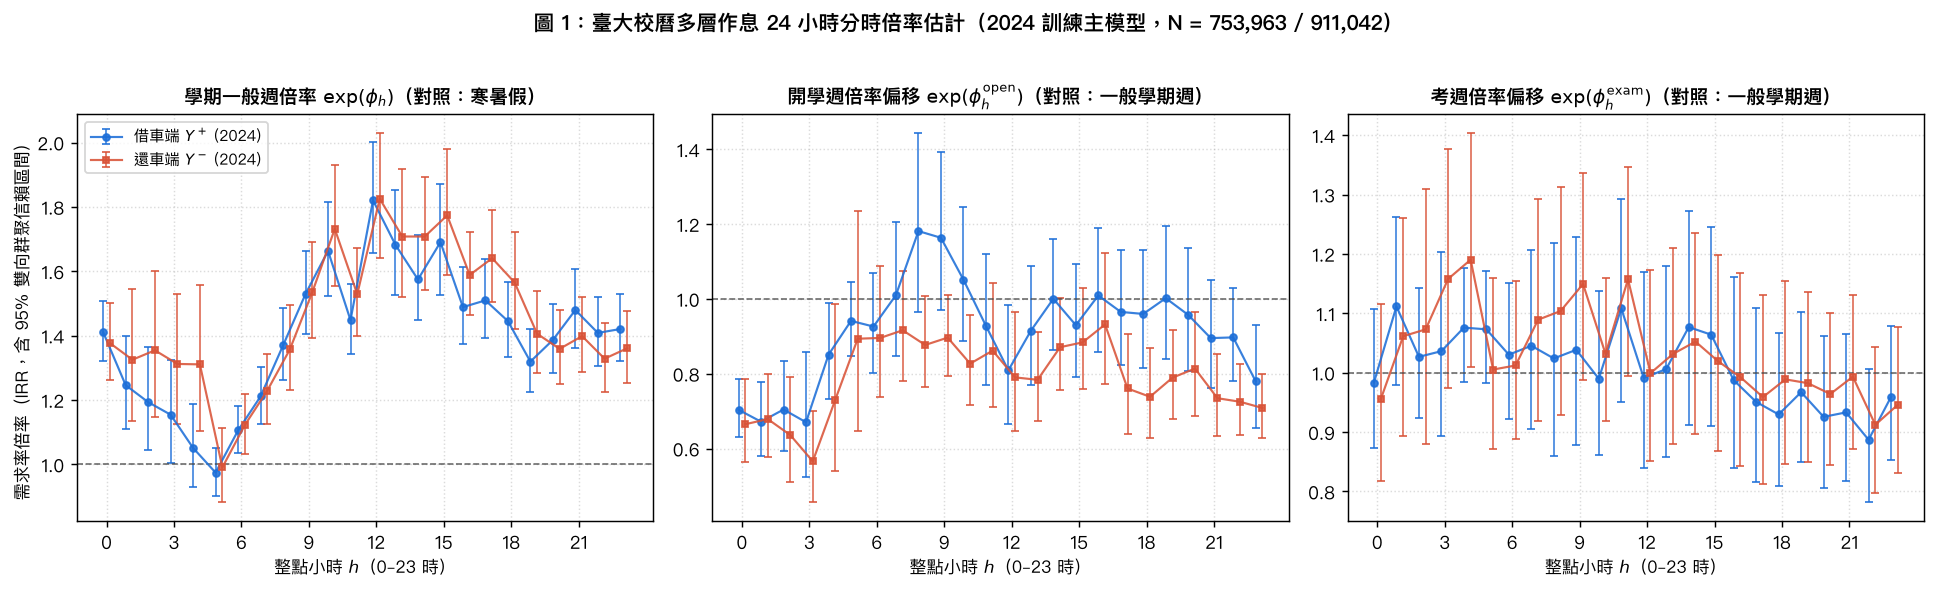

findfont: Failed to find font weight bold for PingFang TC, now using 600.


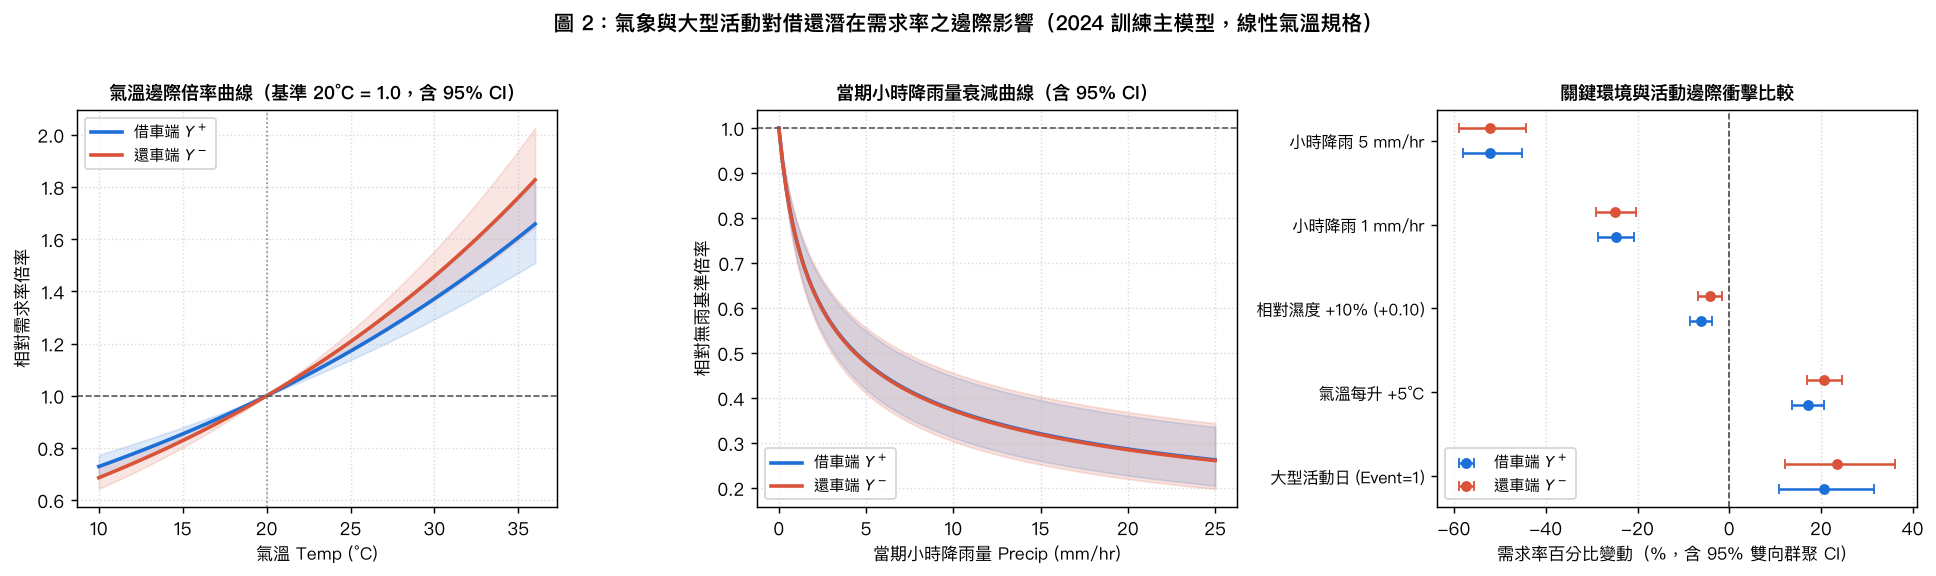

In [9]:
# Figure 1: 24-hour Academic Calendar Multipliers
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.4), sharex=True)
specs = [
    ("sem", "學期一般週倍率 $\\exp(\\phi_h)$（對照：寒暑假）", "#1D6FD8", "#D95338"),
    ("open", "開學週倍率偏移 $\\exp(\\phi^{\\mathrm{open}}_h)$（對照：一般學期週）", "#1D6FD8", "#D95338"),
    ("exam", "考週倍率偏移 $\\exp(\\phi^{\\mathrm{exam}}_h)$（對照：一般學期週）", "#1D6FD8", "#D95338"),
]

for ax, (grp, ttl, c_rent, c_ret) in zip(axes, specs):
    for mname, lbl, col, mk, offset_x in [
        ("rent_train_2024", "借車端 $Y^+$ (2024)", c_rent, "o", -0.15),
        ("return_train_2024", "還車端 $Y^-$ (2024)", c_ret, "s", +0.15),
    ]:
        g = cal_tbl[(cal_tbl["model"] == mname) & (cal_tbl["variable"].str.startswith(grp + "_"))].copy()
        g["h"] = g["variable"].str.slice(-2).astype(int)
        g = g.sort_values("h")
        irr = np.exp(g["coef"].to_numpy())
        lo = np.exp(g["ci95_low_2way"].to_numpy())
        hi = np.exp(g["ci95_high_2way"].to_numpy())
        ax.errorbar(
            g["h"] + offset_x, irr, yerr=[irr - lo, hi - irr],
            fmt=mk + "-", color=col, markersize=3.8, linewidth=1.2, elinewidth=0.9, capsize=2.0, alpha=0.88, label=lbl,
        )
    ax.axhline(1.0, color="#444444", linestyle="--", linewidth=0.9, alpha=0.8)
    ax.set_title(ttl, fontsize=10.5, fontweight="bold")
    ax.set_xlabel("整點小時 $h$（0–23 時）", fontsize=9.5)
    ax.set_xticks(range(0, 24, 3))
    ax.grid(True, linestyle=":", alpha=0.45)

axes[0].set_ylabel("需求率倍率（IRR，含 95% 雙向群聚信賴區間）", fontsize=9.5)
axes[0].legend(loc="upper left", fontsize=8.5, frameon=True)
fig.suptitle(
    f"圖 1：臺大校曆多層作息 24 小時分時倍率估計（2024 訓練主模型，N = {mod_rent_2024['meta']['N_est']:,} / {mod_ret_2024['meta']['N_est']:,}）",
    fontsize=11.5, fontweight="bold", y=1.02,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_hourly_calendar_effects.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig_hourly_calendar_effects.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 2: Weather (Linear Temp curve with 95% CI, Rainfall decay) & Marginal Effect Forest Plot
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.3))

t_grid = np.linspace(10.0, 36.0, 120)
for mname, lbl, col in [("rent_train_2024", "借車端 $Y^+$", "#1D6FD8"), ("return_train_2024", "還車端 $Y^-$", "#D95338")]:
    s = core_tbl[core_tbl["model"] == mname].set_index("variable")
    b1 = s.loc["Temp", "coef"]
    se1 = s.loc["Temp", "se_2way"]
    dt = t_grid - 20.0
    y_mid = np.exp(b1 * dt)
    y_lo = np.exp(b1 * dt - 1.96 * se1 * np.abs(dt))
    y_hi = np.exp(b1 * dt + 1.96 * se1 * np.abs(dt))
    axes[0].plot(t_grid, y_mid, color=col, linewidth=2.0, label=lbl)
    axes[0].fill_between(t_grid, y_lo, y_hi, color=col, alpha=0.14)
axes[0].axhline(1.0, color="#555555", linestyle="--", linewidth=0.9)
axes[0].axvline(20.0, color="#888888", linestyle=":", linewidth=0.9)
axes[0].set_title("氣溫邊際倍率曲線（基準 20°C = 1.0，含 95% CI）", fontsize=10.2, fontweight="bold")
axes[0].set_xlabel("氣溫 Temp (°C)", fontsize=9.5)
axes[0].set_ylabel("相對需求率倍率", fontsize=9.5)
axes[0].legend(fontsize=8.5)
axes[0].grid(True, linestyle=":", alpha=0.45)

r_grid = np.linspace(0.0, 25.0, 120)
for mname, lbl, col in [("rent_train_2024", "借車端 $Y^+$", "#1D6FD8"), ("return_train_2024", "還車端 $Y^-$", "#D95338")]:
    s = core_tbl[core_tbl["model"] == mname].set_index("variable")
    b2 = s.loc["log1p_Precip", "coef"]
    se2 = s.loc["log1p_Precip", "se_2way"]
    y_mid = np.exp(b2 * np.log1p(r_grid))
    y_lo = np.exp((b2 - 1.96 * se2) * np.log1p(r_grid))
    y_hi = np.exp((b2 + 1.96 * se2) * np.log1p(r_grid))
    axes[1].plot(r_grid, y_mid, color=col, linewidth=2.0, label=lbl)
    axes[1].fill_between(r_grid, y_lo, y_hi, color=col, alpha=0.16)
axes[1].axhline(1.0, color="#555555", linestyle="--", linewidth=0.9)
axes[1].set_title("當期小時降雨量衰減曲線（含 95% CI）", fontsize=10.2, fontweight="bold")
axes[1].set_xlabel("當期小時降雨量 Precip (mm/hr)", fontsize=9.5)
axes[1].set_ylabel("相對無雨基準倍率", fontsize=9.5)
axes[1].legend(fontsize=8.5)
axes[1].grid(True, linestyle=":", alpha=0.45)

forest_items = [
    ("大型活動日 (Event=1)", "Event", 1.0),
    ("氣溫每升 +5°C", "Temp", 5.0),
    ("相對濕度 +10% (+0.10)", "HUMD", 0.10),
    ("小時降雨 1 mm/hr", "log1p_Precip", np.log(2.0)),
    ("小時降雨 5 mm/hr", "log1p_Precip", np.log(6.0)),
]
ypos = np.arange(len(forest_items))
for mname, lbl, col, dy in [
    ("rent_train_2024", "借車端 $Y^+$", "#1D6FD8", -0.15),
    ("return_train_2024", "還車端 $Y^-$", "#D95338", +0.15),
]:
    s = core_tbl[core_tbl["model"] == mname].set_index("variable")
    pcts, errs_lo, errs_hi = [], [], []
    for _, v, mult in forest_items:
        c = s.loc[v, "coef"] * mult
        se = s.loc[v, "se_2way"] * mult
        p_mid = (np.exp(c) - 1.0) * 100.0
        p_lo = (np.exp(c - 1.96 * se) - 1.0) * 100.0
        p_hi = (np.exp(c + 1.96 * se) - 1.0) * 100.0
        pcts.append(p_mid)
        errs_lo.append(p_mid - p_lo)
        errs_hi.append(p_hi - p_mid)
    axes[2].errorbar(
        pcts, ypos + dy, xerr=[errs_lo, errs_hi],
        fmt="o", color=col, markersize=5.0, elinewidth=1.4, capsize=3.0, label=lbl,
    )
axes[2].axvline(0.0, color="#444444", linestyle="--", linewidth=0.9)
axes[2].set_yticks(ypos)
axes[2].set_yticklabels([x[0] for x in forest_items], fontsize=9.0)
axes[2].set_xlabel("需求率百分比變動（%，含 95% 雙向群聚 CI）", fontsize=9.5)
axes[2].set_title("關鍵環境與活動邊際衝擊比較", fontsize=10.2, fontweight="bold")
axes[2].legend(loc="lower left", fontsize=8.5)
axes[2].grid(True, axis="x", linestyle=":", alpha=0.45)

fig.suptitle("圖 2：氣象與大型活動對借還潛在需求率之邊際影響（2024 訓練主模型，線性氣溫規格）", fontsize=11.5, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_weather_event_effects.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig_weather_event_effects.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)


=== TRAINING & WITHIN-2024 VALIDATION PERFORMANCE ===


,split,side,model,N,wMSE_rate,wRMSE_rate,wMAE_rate,wR2_rate,RMSE_count,MAE_count,R2_count,total_pred_bias_pct
0,TRAIN_2024,Rent Y+,Historical Group Mean,753991,0.0246,0.1570,0.0888,0.6898,7.1973,3.8056,0.7260,0.0000
1,TRAIN_2024,Rent Y+,NB2-FE Linear Temp (Ours),753991,0.0205,0.1432,0.0813,0.7417,6.5328,3.4840,0.7742,1.1286
2,TRAIN_2024,Rent Y+,NB2-FE + Temp^2 (Ablation),753991,0.0205,0.1433,0.0813,0.7416,6.5345,3.4857,0.7741,1.1181
3,TRAIN_2024,Return Y-,Historical Group Mean,912531,0.0151,0.1227,0.0559,0.7448,6.7060,3.2067,0.7534,0.0000
4,TRAIN_2024,Return Y-,NB2-FE Linear Temp (Ours),912531,0.0132,0.1149,0.0524,0.7762,6.2793,3.0029,0.7838,2.5013
5,TRAIN_2024,Return Y-,NB2-FE + Temp^2 (Ablation),912531,0.0132,0.1150,0.0524,0.7761,6.2800,3.0047,0.7837,2.4815
6,VAL_2024_H2,Rent Y+,Historical Group Mean,241829,0.0614,0.2477,0.1312,0.5353,11.3702,5.6080,0.5891,-37.9611
7,VAL_2024_H2,Rent Y+,NB2-FE Linear Temp (Ours),241829,0.0525,0.2291,0.1218,0.6026,10.5141,5.2040,0.6487,-35.5769
8,VAL_2024_H2,Return Y-,Historical Group Mean,288367,0.0374,0.1935,0.0814,0.6257,10.4765,4.6773,0.6423,-38.5491
9,VAL_2024_H2,Return Y-,NB2-FE Linear Temp (Ours),288367,0.0308,0.1756,0.0756,0.6916,9.4690,4.3448,0.7078,-34.3285


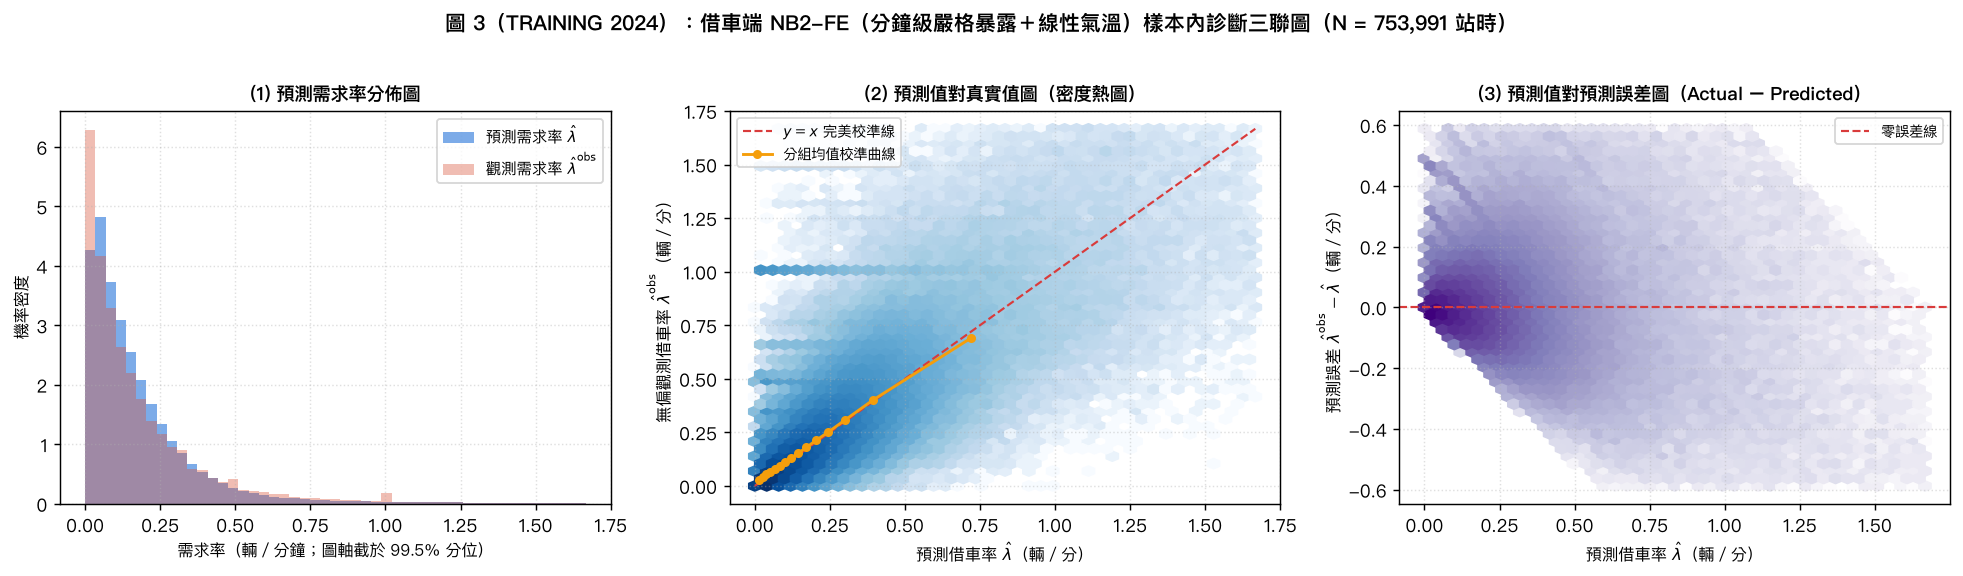

In [10]:
def fit_historical_baseline(train_df: pd.DataFrame, y_col: str, exp_col: str) -> tuple[pd.Series, pd.Series]:
    grp4 = train_df.groupby(["station_id", "hour", "weekday", "semester"]).apply(
        lambda g: g[y_col].sum() / g[exp_col].sum(), include_groups=False
    )
    grp3 = train_df.groupby(["station_id", "hour", "weekday"]).apply(
        lambda g: g[y_col].sum() / g[exp_col].sum(), include_groups=False
    )
    return grp4, grp3


def predict_historical_baseline(grp4: pd.Series, grp3: pd.Series, df_new: pd.DataFrame) -> np.ndarray:
    idx4 = pd.MultiIndex.from_frame(df_new[["station_id", "hour", "weekday", "semester"]])
    idx3 = pd.MultiIndex.from_frame(df_new[["station_id", "hour", "weekday"]])
    p4 = grp4.reindex(idx4).to_numpy(dtype=np.float64)
    p3 = grp3.reindex(idx3).to_numpy(dtype=np.float64)
    return np.where(np.isnan(p4), p3, p4)


def compute_eval_metrics(y_true: np.ndarray, exp_min: np.ndarray, rate_pred: np.ndarray, split_name: str, side: str, model_label: str) -> dict:
    ok = np.isfinite(rate_pred) & np.isfinite(y_true) & (exp_min > 0)
    y = y_true[ok]
    w = exp_min[ok]
    r_obs = y / w
    r_hat = rate_pred[ok]
    err_rate = r_obs - r_hat
    w_norm = w / np.sum(w)

    mse_rate_w = float(np.sum(w_norm * (err_rate ** 2)))
    rmse_rate_w = math.sqrt(mse_rate_w)
    mae_rate_w = float(np.sum(w_norm * np.abs(err_rate)))
    mean_r_obs = float(np.sum(y) / np.sum(w))
    r2_rate_w = float(1.0 - mse_rate_w / np.sum(w_norm * ((r_obs - mean_r_obs) ** 2)))

    y_hat = r_hat * w
    err_cnt = y - y_hat
    mse_cnt = float(np.mean(err_cnt ** 2))
    rmse_cnt = math.sqrt(mse_cnt)
    mae_cnt = float(np.mean(np.abs(err_cnt)))
    r2_cnt = float(1.0 - mse_cnt / np.mean((y - np.mean(y)) ** 2))
    bias_pct = (float(np.sum(y_hat)) / float(np.sum(y)) - 1.0) * 100.0

    return {
        "split": split_name,
        "side": side,
        "model": model_label,
        "N": int(ok.sum()),
        "wMSE_rate": mse_rate_w,
        "wRMSE_rate": rmse_rate_w,
        "wMAE_rate": mae_rate_w,
        "wR2_rate": r2_rate_w,
        "RMSE_count": rmse_cnt,
        "MAE_count": mae_cnt,
        "R2_count": r2_cnt,
        "total_pred_bias_pct": bias_pct,
    }


def plot_eval_trio(y_true: np.ndarray, exp_min: np.ndarray, rate_pred: np.ndarray, title_prefix: str, save_stem: str) -> None:
    ok = np.isfinite(rate_pred) & (exp_min > 0)
    r_obs = y_true[ok] / exp_min[ok]
    r_hat = rate_pred[ok]
    err = r_obs - r_hat

    q995 = float(np.quantile(np.concatenate([r_obs, r_hat]), 0.995))
    cap = max(q995, 0.5)
    m_vis = (r_obs <= cap) & (r_hat <= cap)

    fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.3))
    bins = np.linspace(0.0, cap, 50)
    axes[0].hist(r_hat[r_hat <= cap], bins=bins, density=True, alpha=0.58, color="#1D6FD8", label="預測需求率 $\\hat{\\lambda}$")
    axes[0].hist(r_obs[r_obs <= cap], bins=bins, density=True, alpha=0.38, color="#D95338", label="觀測需求率 $\\hat{\\lambda}^{\\mathrm{obs}}$")
    axes[0].set_title("(1) 預測需求率分佈圖", fontsize=10.2, fontweight="bold")
    axes[0].set_xlabel("需求率（輛／分鐘；圖軸截於 99.5% 分位）", fontsize=9.0)
    axes[0].set_ylabel("機率密度", fontsize=9.0)
    axes[0].legend(fontsize=8.5)
    axes[0].grid(True, linestyle=":", alpha=0.4)

    axes[1].hexbin(r_hat[m_vis], r_obs[m_vis], gridsize=42, bins="log", cmap="Blues", mincnt=1)
    axes[1].plot([0, cap], [0, cap], color="#D93B3B", linestyle="--", linewidth=1.2, label="$y = x$ 完美校準線")
    q_edges = np.unique(np.quantile(r_hat[m_vis], np.linspace(0, 1, 16)))
    if len(q_edges) >= 3:
        b_idx = np.digitize(r_hat[m_vis], q_edges[1:-1])
        bx = [r_hat[m_vis][b_idx == k].mean() for k in range(len(q_edges) - 1) if (b_idx == k).any()]
        by = [r_obs[m_vis][b_idx == k].mean() for k in range(len(q_edges) - 1) if (b_idx == k).any()]
        axes[1].plot(bx, by, "o-", color="#F59E0B", markersize=4.0, linewidth=1.6, label="分組均值校準曲線")
    axes[1].set_title("(2) 預測值對真實值圖（密度熱圖）", fontsize=10.2, fontweight="bold")
    axes[1].set_xlabel("預測借車率 $\\hat{\\lambda}$（輛／分）", fontsize=9.0)
    axes[1].set_ylabel("無偏觀測借車率 $\\hat{\\lambda}^{\\mathrm{obs}}$（輛／分）", fontsize=9.0)
    axes[1].legend(loc="upper left", fontsize=8.0)
    axes[1].grid(True, linestyle=":", alpha=0.4)

    e_lim = float(np.quantile(np.abs(err[m_vis]), 0.99))
    m_err = m_vis & (np.abs(err) <= e_lim)
    axes[2].hexbin(r_hat[m_err], err[m_err], gridsize=42, bins="log", cmap="Purples", mincnt=1)
    axes[2].axhline(0.0, color="#D93B3B", linestyle="--", linewidth=1.2, label="零誤差線")
    axes[2].set_title("(3) 預測值對預測誤差圖（Actual − Predicted）", fontsize=10.2, fontweight="bold")
    axes[2].set_xlabel("預測借車率 $\\hat{\\lambda}$（輛／分）", fontsize=9.0)
    axes[2].set_ylabel("預測誤差 $\\hat{\\lambda}^{\\mathrm{obs}} - \\hat{\\lambda}$（輛／分）", fontsize=9.0)
    axes[2].legend(loc="upper right", fontsize=8.0)
    axes[2].grid(True, linestyle=":", alpha=0.4)

    fig.suptitle(f"{title_prefix}（N = {int(ok.sum()):,} 站時）", fontsize=11.5, fontweight="bold", y=1.02)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{save_stem}.png", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{save_stem}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


base_rent_2024 = fit_historical_baseline(tr24_rent, "y_rent", "exp_rent_eff")
base_ret_2024 = fit_historical_baseline(tr24_ret, "y_ret", "exp_ret_eff")
base_rent_h1 = fit_historical_baseline(tr24_h1_rent, "y_rent", "exp_rent_eff")
base_ret_h1 = fit_historical_baseline(tr24_h1_ret, "y_ret", "exp_ret_eff")

metrics_list = []

pred_tr24_rent_nb = predict_rate_nb2_fe(mod_rent_2024, tr24_rent)
pred_tr24_rent_quad = predict_rate_nb2_fe(mod_rent_2024_quad, tr24_rent)
pred_tr24_rent_base = predict_historical_baseline(*base_rent_2024, tr24_rent)
pred_tr24_ret_nb = predict_rate_nb2_fe(mod_ret_2024, tr24_ret)
pred_tr24_ret_quad = predict_rate_nb2_fe(mod_ret_2024_quad, tr24_ret)
pred_tr24_ret_base = predict_historical_baseline(*base_ret_2024, tr24_ret)

metrics_list.extend([
    compute_eval_metrics(tr24_rent["y_rent"].to_numpy(), tr24_rent["exp_rent_eff"].to_numpy(), pred_tr24_rent_base, "TRAIN_2024", "Rent Y+", "Historical Group Mean"),
    compute_eval_metrics(tr24_rent["y_rent"].to_numpy(), tr24_rent["exp_rent_eff"].to_numpy(), pred_tr24_rent_nb, "TRAIN_2024", "Rent Y+", "NB2-FE Linear Temp (Ours)"),
    compute_eval_metrics(tr24_rent["y_rent"].to_numpy(), tr24_rent["exp_rent_eff"].to_numpy(), pred_tr24_rent_quad, "TRAIN_2024", "Rent Y+", "NB2-FE + Temp^2 (Ablation)"),
    compute_eval_metrics(tr24_ret["y_ret"].to_numpy(), tr24_ret["exp_ret_eff"].to_numpy(), pred_tr24_ret_base, "TRAIN_2024", "Return Y-", "Historical Group Mean"),
    compute_eval_metrics(tr24_ret["y_ret"].to_numpy(), tr24_ret["exp_ret_eff"].to_numpy(), pred_tr24_ret_nb, "TRAIN_2024", "Return Y-", "NB2-FE Linear Temp (Ours)"),
    compute_eval_metrics(tr24_ret["y_ret"].to_numpy(), tr24_ret["exp_ret_eff"].to_numpy(), pred_tr24_ret_quad, "TRAIN_2024", "Return Y-", "NB2-FE + Temp^2 (Ablation)"),
])

pred_v24_rent_nb = predict_rate_nb2_fe(mod_rent_2024_h1, val24_h2_rent)
pred_v24_rent_base = predict_historical_baseline(*base_rent_h1, val24_h2_rent)
pred_v24_ret_nb = predict_rate_nb2_fe(mod_ret_2024_h1, val24_h2_ret)
pred_v24_ret_base = predict_historical_baseline(*base_ret_h1, val24_h2_ret)

metrics_list.extend([
    compute_eval_metrics(val24_h2_rent["y_rent"].to_numpy(), val24_h2_rent["exp_rent_eff"].to_numpy(), pred_v24_rent_base, "VAL_2024_H2", "Rent Y+", "Historical Group Mean"),
    compute_eval_metrics(val24_h2_rent["y_rent"].to_numpy(), val24_h2_rent["exp_rent_eff"].to_numpy(), pred_v24_rent_nb, "VAL_2024_H2", "Rent Y+", "NB2-FE Linear Temp (Ours)"),
    compute_eval_metrics(val24_h2_ret["y_ret"].to_numpy(), val24_h2_ret["exp_ret_eff"].to_numpy(), pred_v24_ret_base, "VAL_2024_H2", "Return Y-", "Historical Group Mean"),
    compute_eval_metrics(val24_h2_ret["y_ret"].to_numpy(), val24_h2_ret["exp_ret_eff"].to_numpy(), pred_v24_ret_nb, "VAL_2024_H2", "Return Y-", "NB2-FE Linear Temp (Ours)"),
])

print("=== TRAINING & WITHIN-2024 VALIDATION PERFORMANCE ===")
display(pd.DataFrame(metrics_list))

plot_eval_trio(
    tr24_rent["y_rent"].to_numpy(),
    tr24_rent["exp_rent_eff"].to_numpy(),
    pred_tr24_rent_nb,
    "圖 3（TRAINING 2024）：借車端 NB2-FE（分鐘級嚴格暴露＋線性氣溫）樣本內診斷三聯圖",
    "fig_eval_train_2024",
)


2025 Q1 (1–3 月) 跨年全域需求成長校準倍率 -> Rent NB2-FE: ×1.3585, Rent Baseline: ×1.1343 | Return NB2-FE: ×1.3842, Return Baseline: ×1.1051

=== TESTING DATA (2025 獨立跨年度樣本外測試) PERFORMANCE ===


,split,side,model,N,wMSE_rate,wRMSE_rate,wMAE_rate,wR2_rate,RMSE_count,MAE_count,R2_count,total_pred_bias_pct
0,TEST_2025_FULL_RAW,Rent Y+,Historical Group Mean,744379,0.0745,0.2730,0.1231,0.5343,9.2969,4.8946,0.6733,-26.7310
1,TEST_2025_FULL_RAW,Rent Y+,NB2-FE Linear Temp (Ours),744379,0.0667,0.2583,0.1133,0.5830,8.5954,4.5039,0.7208,-24.0243
2,TEST_2025_FULL_RAW,Rent Y+,NB2-FE + Temp^2 (Ablation),744379,0.0666,0.2581,0.1131,0.5836,8.5846,4.4966,0.7215,-24.0881
3,TEST_2025_FULL_RAW,Return Y-,Historical Group Mean,988207,0.0181,0.1345,0.0627,0.7711,7.4309,3.6440,0.7814,-18.8089
4,TEST_2025_FULL_RAW,Return Y-,NB2-FE Linear Temp (Ours),988207,0.0152,0.1234,0.0580,0.8073,6.8132,3.3723,0.8163,-14.8330
5,TEST_2025_FULL_RAW,Return Y-,NB2-FE + Temp^2 (Ablation),988207,0.0151,0.1230,0.0578,0.8086,6.7853,3.3589,0.8178,-14.9101
6,TEST_2025_Q2_Q4_SCALED,Rent Y+,Historical Group Mean (Q1-scaled),549652,0.0862,0.2936,0.1291,0.5409,9.3925,5.0015,0.6904,-21.6946
7,TEST_2025_Q2_Q4_SCALED,Rent Y+,NB2-FE Linear Temp (Q1-scaled),549652,0.0751,0.2741,0.1245,0.5999,8.7512,4.8247,0.7313,4.1294
8,TEST_2025_Q2_Q4_SCALED,Return Y-,Historical Group Mean (Q1-scaled),745931,0.0179,0.1340,0.0633,0.7882,7.3676,3.6736,0.7985,-12.9456
9,TEST_2025_Q2_Q4_SCALED,Return Y-,NB2-FE Linear Temp (Q1-scaled),745931,0.0215,0.1468,0.0703,0.7458,8.3320,4.0769,0.7423,22.5468


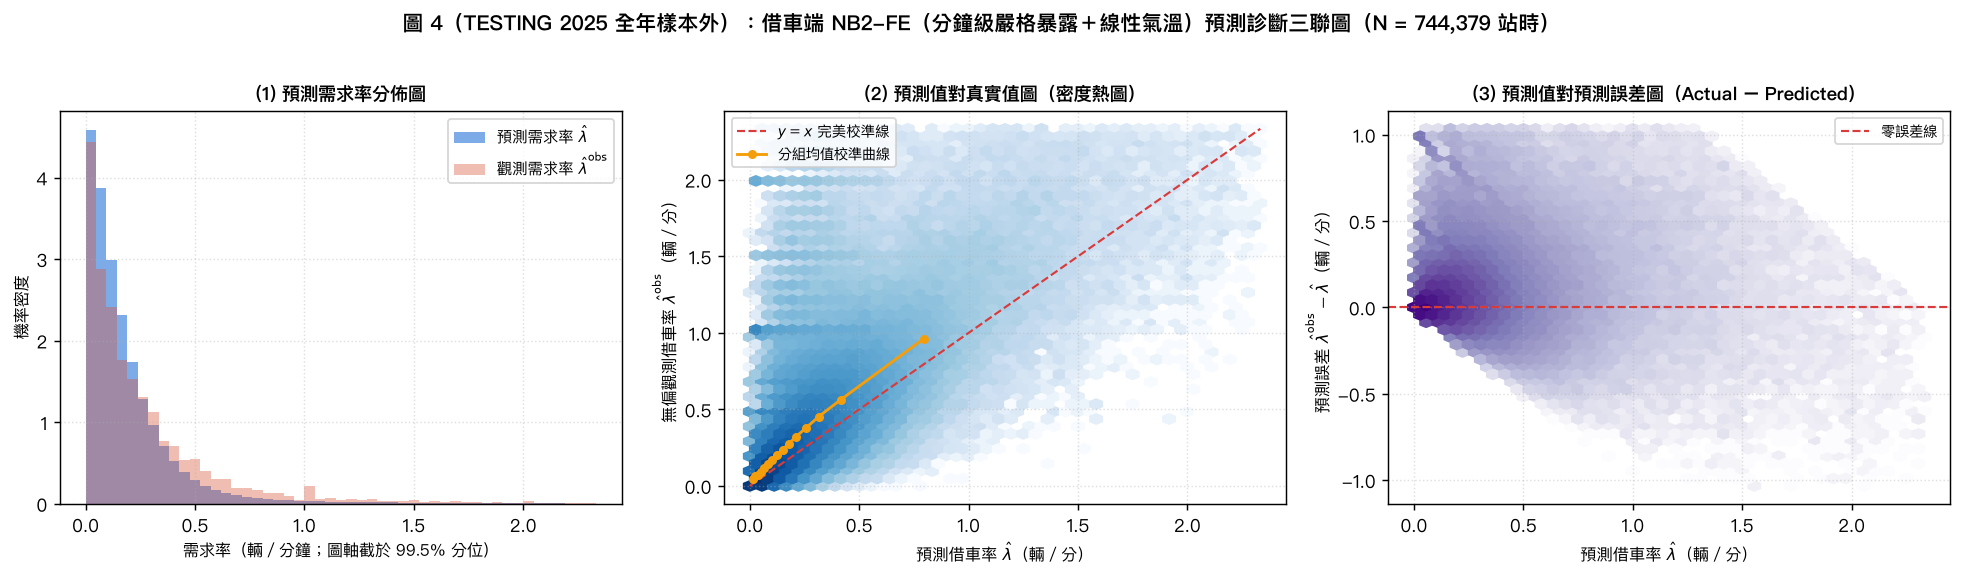

In [11]:
te25_rent = test_2025[test_2025["valid_rent"] & test_2025["station_id"].isin(train_stations_2024)].copy()
te25_ret = test_2025[test_2025["valid_ret"] & test_2025["station_id"].isin(train_stations_2024)].copy()

pred_te25_rent_nb_raw = predict_rate_nb2_fe(mod_rent_2024, te25_rent)
pred_te25_rent_quad_raw = predict_rate_nb2_fe(mod_rent_2024_quad, te25_rent)
pred_te25_rent_base_raw = predict_historical_baseline(*base_rent_2024, te25_rent)

pred_te25_ret_nb_raw = predict_rate_nb2_fe(mod_ret_2024, te25_ret)
pred_te25_ret_quad_raw = predict_rate_nb2_fe(mod_ret_2024_quad, te25_ret)
pred_te25_ret_base_raw = predict_historical_baseline(*base_ret_2024, te25_ret)

q1_rent = te25_rent["month"] <= 3
q24_rent = te25_rent["month"] >= 4
scale_rent_nb_q1 = float(te25_rent.loc[q1_rent, "y_rent"].sum() / np.sum(pred_te25_rent_nb_raw[q1_rent] * te25_rent.loc[q1_rent, "exp_rent_eff"]))
scale_rent_base_q1 = float(te25_rent.loc[q1_rent, "y_rent"].sum() / np.sum(pred_te25_rent_base_raw[q1_rent] * te25_rent.loc[q1_rent, "exp_rent_eff"]))

q1_ret = te25_ret["month"] <= 3
q24_ret = te25_ret["month"] >= 4
scale_ret_nb_q1 = float(te25_ret.loc[q1_ret, "y_ret"].sum() / np.sum(pred_te25_ret_nb_raw[q1_ret] * te25_ret.loc[q1_ret, "exp_ret_eff"]))
scale_ret_base_q1 = float(te25_ret.loc[q1_ret, "y_ret"].sum() / np.sum(pred_te25_ret_base_raw[q1_ret] * te25_ret.loc[q1_ret, "exp_ret_eff"]))

print(
    f"2025 Q1 (1–3 月) 跨年全域需求成長校準倍率 -> "
    f"Rent NB2-FE: ×{scale_rent_nb_q1:.4f}, Rent Baseline: ×{scale_rent_base_q1:.4f} | "
    f"Return NB2-FE: ×{scale_ret_nb_q1:.4f}, Return Baseline: ×{scale_ret_base_q1:.4f}"
)

test_metrics = [
    compute_eval_metrics(te25_rent["y_rent"].to_numpy(), te25_rent["exp_rent_eff"].to_numpy(), pred_te25_rent_base_raw, "TEST_2025_FULL_RAW", "Rent Y+", "Historical Group Mean"),
    compute_eval_metrics(te25_rent["y_rent"].to_numpy(), te25_rent["exp_rent_eff"].to_numpy(), pred_te25_rent_nb_raw, "TEST_2025_FULL_RAW", "Rent Y+", "NB2-FE Linear Temp (Ours)"),
    compute_eval_metrics(te25_rent["y_rent"].to_numpy(), te25_rent["exp_rent_eff"].to_numpy(), pred_te25_rent_quad_raw, "TEST_2025_FULL_RAW", "Rent Y+", "NB2-FE + Temp^2 (Ablation)"),
    compute_eval_metrics(te25_ret["y_ret"].to_numpy(), te25_ret["exp_ret_eff"].to_numpy(), pred_te25_ret_base_raw, "TEST_2025_FULL_RAW", "Return Y-", "Historical Group Mean"),
    compute_eval_metrics(te25_ret["y_ret"].to_numpy(), te25_ret["exp_ret_eff"].to_numpy(), pred_te25_ret_nb_raw, "TEST_2025_FULL_RAW", "Return Y-", "NB2-FE Linear Temp (Ours)"),
    compute_eval_metrics(te25_ret["y_ret"].to_numpy(), te25_ret["exp_ret_eff"].to_numpy(), pred_te25_ret_quad_raw, "TEST_2025_FULL_RAW", "Return Y-", "NB2-FE + Temp^2 (Ablation)"),
    compute_eval_metrics(te25_rent.loc[q24_rent, "y_rent"].to_numpy(), te25_rent.loc[q24_rent, "exp_rent_eff"].to_numpy(), pred_te25_rent_base_raw[q24_rent] * scale_rent_base_q1, "TEST_2025_Q2_Q4_SCALED", "Rent Y+", "Historical Group Mean (Q1-scaled)"),
    compute_eval_metrics(te25_rent.loc[q24_rent, "y_rent"].to_numpy(), te25_rent.loc[q24_rent, "exp_rent_eff"].to_numpy(), pred_te25_rent_nb_raw[q24_rent] * scale_rent_nb_q1, "TEST_2025_Q2_Q4_SCALED", "Rent Y+", "NB2-FE Linear Temp (Q1-scaled)"),
    compute_eval_metrics(te25_ret.loc[q24_ret, "y_ret"].to_numpy(), te25_ret.loc[q24_ret, "exp_ret_eff"].to_numpy(), pred_te25_ret_base_raw[q24_ret] * scale_ret_base_q1, "TEST_2025_Q2_Q4_SCALED", "Return Y-", "Historical Group Mean (Q1-scaled)"),
    compute_eval_metrics(te25_ret.loc[q24_ret, "y_ret"].to_numpy(), te25_ret.loc[q24_ret, "exp_ret_eff"].to_numpy(), pred_te25_ret_nb_raw[q24_ret] * scale_ret_nb_q1, "TEST_2025_Q2_Q4_SCALED", "Return Y-", "NB2-FE Linear Temp (Q1-scaled)"),
]

eval_all_df = pd.DataFrame(metrics_list + test_metrics)
eval_all_df.to_csv(OUT_DIR / "eval_metrics_summary.csv", index=False)

print("\n=== TESTING DATA (2025 獨立跨年度樣本外測試) PERFORMANCE ===")
display(pd.DataFrame(test_metrics))

plot_eval_trio(
    te25_rent["y_rent"].to_numpy(),
    te25_rent["exp_rent_eff"].to_numpy(),
    pred_te25_rent_nb_raw,
    "圖 4（TESTING 2025 全年樣本外）：借車端 NB2-FE（分鐘級嚴格暴露＋線性氣溫）預測診斷三聯圖",
    "fig_eval_test_2025",
)


In [12]:
fe_export = (
    mod_rent_full["fe_df"][["station_id", "hour", "weekday", "psi", "is_zero_fe"]]
    .rename(columns={"psi": "psi_rent_full", "is_zero_fe": "zero_fe_rent_full"})
    .merge(
        mod_ret_full["fe_df"][["station_id", "hour", "weekday", "psi", "is_zero_fe"]]
        .rename(columns={"psi": "psi_ret_full", "is_zero_fe": "zero_fe_ret_full"}),
        on=["station_id", "hour", "weekday"],
        how="outer",
    )
    .merge(
        mod_rent_2024["fe_df"][["station_id", "hour", "weekday", "psi", "is_zero_fe"]]
        .rename(columns={"psi": "psi_rent_2024", "is_zero_fe": "zero_fe_rent_2024"}),
        on=["station_id", "hour", "weekday"],
        how="left",
    )
    .merge(
        mod_ret_2024["fe_df"][["station_id", "hour", "weekday", "psi", "is_zero_fe"]]
        .rename(columns={"psi": "psi_ret_2024", "is_zero_fe": "zero_fe_ret_2024"}),
        on=["station_id", "hour", "weekday"],
        how="left",
    )
    .sort_values(["station_id", "weekday", "hour"])
    .reset_index(drop=True)
)
fe_export.to_parquet(OUT_DIR / "params_fixed_effects.parquet", index=False)

oos_2025_df = test_2025[
    ["station_id", "datetime", "date", "hour", "weekday", "semester", "opening", "exam", "event",
     "Temp", "HUMD", "rain_1h_mm", "y_rent", "exp_rent_eff", "valid_rent", "y_ret", "exp_ret_eff", "valid_ret"]
].copy()
oos_2025_df["lambda_pred_nb_raw"] = predict_rate_nb2_fe(mod_rent_2024, oos_2025_df)
oos_2025_df["lambda_pred_nb_q1scaled"] = oos_2025_df["lambda_pred_nb_raw"] * scale_rent_nb_q1
oos_2025_df["lambda_pred_base_raw"] = predict_historical_baseline(*base_rent_2024, oos_2025_df)
oos_2025_df["mu_pred_nb_raw"] = predict_rate_nb2_fe(mod_ret_2024, oos_2025_df)
oos_2025_df["mu_pred_nb_q1scaled"] = oos_2025_df["mu_pred_nb_raw"] * scale_ret_nb_q1
oos_2025_df["mu_pred_base_raw"] = predict_historical_baseline(*base_ret_2024, oos_2025_df)
oos_2025_df.to_parquet(OUT_DIR / "predictions_2025_oos.parquet", index=False)

manifest = {
    "created_at": "2026-11-26",
    "author": "柯典辰 (B13303082)",
    "exposure_granularity": "integer_minute_floor_seconds_strict_positive",
    "temperature_spec": "linear_Temp_only_K76",
    "input_sha256": {k: v[1] for k, v in INPUT_SPECS.items()},
    "academic_calendar_ranges": {
        "opening_weeks_mon_fri": OPENING_RANGES,
        "exam_weeks_mon_fri": EXAM_RANGES,
    },
    "q1_2025_global_scale_factors": {
        "rent_nb2_fe": round(scale_rent_nb_q1, 6),
        "rent_baseline": round(scale_rent_base_q1, 6),
        "return_nb2_fe": round(scale_ret_nb_q1, 6),
        "return_baseline": round(scale_ret_base_q1, 6),
    },
    "models": {
        "rent_train_2024": mod_rent_2024["meta"],
        "return_train_2024": mod_ret_2024["meta"],
        "rent_train_2024_with_tempsq": mod_rent_2024_quad["meta"],
        "return_train_2024_with_tempsq": mod_ret_2024_quad["meta"],
        "rent_train_2024_with_cpi": mod_rent_2024_cpi["meta"],
        "rent_full_2024_2025": mod_rent_full["meta"],
        "return_full_2024_2025": mod_ret_full["meta"],
    },
    "output_files": sorted(str(p.relative_to(OUT_DIR)) for p in OUT_DIR.rglob("*") if p.is_file()),
}
(OUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

fe_chk = pd.read_parquet(OUT_DIR / "params_fixed_effects.parquet")
oos_chk = pd.read_parquet(OUT_DIR / "predictions_2025_oos.parquet")
assert len(fe_chk) == 120 * 24 * 2 == 5760, f"Unexpected FE rows: {len(fe_chk)}"
assert len(oos_chk) == 120 * 8760 == 1_051_200, f"Unexpected OOS rows: {len(oos_chk)}"

print("=== 磁碟輸出檔案驗證完成 (`outputs_nb_demand/`) ===")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(OUT_DIR)):45s} {p.stat().st_size:>12,} bytes")


=== 磁碟輸出檔案驗證完成 (`outputs_nb_demand/`) ===
  data_audit_report.csv                                  430 bytes
  desc_categorical_test_2025.csv                       1,154 bytes
  desc_categorical_train_2024.csv                      1,153 bytes
  desc_numeric_test_2025.csv                           1,343 bytes
  desc_numeric_train_2024.csv                          1,271 bytes
  diagnostic_event_heterogeneity.csv                   1,308 bytes
  eval_metrics_summary.csv                             4,314 bytes
  figures/fig_error_attribution_by_variable.pdf      189,204 bytes
  figures/fig_error_attribution_by_variable.png    1,003,761 bytes
  figures/fig_eval_test_2025.pdf                     100,153 bytes
  figures/fig_eval_test_2025.png                     518,678 bytes
  figures/fig_eval_train_2024.pdf                    102,901 bytes
  figures/fig_eval_train_2024.png                    589,325 bytes
  figures/fig_hourly_calendar_effects.pdf             70,409 bytes
  figures/fig_hourly

## 2. 事前 60 分鐘潛在需求驗證與「預測借車 vs. 預測還車」結構特色剖析

在實際未來營運預測階段，我們**無法事前得知該小時會空站或滿站幾分鐘（沒有未來暴露時間）**，因此直接將事前可知的外生特徵（站點、小時、平假日、校曆、氣溫、降雨、濕度、活動）代入模型，計算未截斷之每分鐘需求率並乘以完整 60 分鐘，得到該小時潛在借還需求預測量：

$$\hat{D}^+_{i,t} = 60 \cdot \exp(\hat{\eta}^+_{i,t}), \qquad \hat{D}^-_{i,t} = 60 \cdot \exp(\hat{\eta}^-_{i,t})$$

本節直接驗證研究計畫書之兩大核心設計檢核：
1. **第一關與第二關驗證（表 6）**：完全不依賴未來暴露時間（連 `exposure = 0` 之站時亦全數納入預測），檢驗 2024 同年度基準與 2025 獨立跨年度樣本外中，$\hat{D}^+_{i,t}$ 與 $\hat{D}^-_{i,t}$ 是否確實系統性高於遭硬體截斷之實際刷卡數 $Y^{\pm}_{i,t}$（特別是在空站 $b=0$ 與滿站 $\text{Exp}^-<60$ 時段），並量化借還兩端之保守緩衝比例與跨年成長校準的必要性。
2. **預測借車端 vs. 預測還車端之數據樣貌與結構特色（表 7 與圖 7）**：完整呈現預測借車與還車 60 分鐘需求之分位數分佈、平日／假日與學期／寒暑假差異、24 小時全區總量波形，以及前 10 大主力站點早晚尖峰之「借還潮汐空間對調」特性。


=== 表 6：事前 60 分鐘潛在需求還原驗證表（完全不依賴未來暴露時間） ===


,評估口徑,時段子集,站時數 N,實借總量 Y+,60分預測借車 D+,借車倍數 (D+/Y+),單時 D+>=Y+ (%),站數 D+>Y+ (/118),實還總量 Y-,60分預測還車 D-,還車倍數 (D-/Y-),單時 D->=Y- (%),站數 D->Y- (/118),預測借還比 (D+/D-)
0,2024 同年度（無跨年成長干擾）,全體正常站時（含 exp=0）,922476,6489943,8886870,1.3693,80.1680,118,6314383,7102244,1.1248,66.9079,117,1.2513
1,2024 同年度（無跨年成長干擾）,借車空站截斷時段（b=0）,283336,2089354,3481504,1.6663,86.9600,118,1821045,1980577,1.0876,66.0227,114,1.7578
2,2024 同年度（無跨年成長干擾）,借車未曾空站（b>=10）,237837,1864723,2266821,1.2156,76.3409,112,2017945,2431352,1.2049,69.1242,100,0.9323
3,2024 同年度（無跨年成長干擾）,還車滿站截斷時段（Exp-<60）,121612,1263846,1447294,1.1452,70.5596,113,1399626,1836947,1.3125,72.4509,99,0.7879
4,2024 同年度（無跨年成長干擾）,還車未曾滿站（Exp-=60）,800864,5226097,7439576,1.4235,81.6271,118,4914757,5265297,1.0713,66.0661,117,1.4129
5,2025 樣本外（純 2024 權重，未校準）,全體正常站時（含 exp=0）,992588,8702924,9800585,1.1261,69.3144,96,8505642,7750226,0.9112,54.3156,33,1.2646
6,2025 樣本外（純 2024 權重，未校準）,借車空站截斷時段（b=0）,271903,2329529,3353571,1.4396,79.6633,117,2036623,1815048,0.8912,53.8052,20,1.8476
7,2025 樣本外（純 2024 權重，未校準）,借車未曾空站（b>=10）,255426,2742026,2622658,0.9565,61.5348,64,2816515,2695110,0.9569,55.3886,51,0.9731
8,2025 樣本外（純 2024 權重，未校準）,還車滿站截斷時段（Exp-<60）,100424,1464648,1308136,0.8931,50.0010,38,1631008,1685341,1.0333,55.4917,47,0.7762
9,2025 樣本外（純 2024 權重，未校準）,還車未曾滿站（Exp-=60）,892164,7238276,8492449,1.1733,71.4883,103,6874634,6064885,0.8822,54.1832,23,1.4003



=== 表 7：預測借車端 vs. 預測還車端 60 分鐘潛在需求分佈與特色比較 ===


,資料年度,方向,均值 (輛/時),標準差,中位數 (P50),P75,P90,P99,最大值,平日/假日比,學期/寒暑假比,平日08時均值,平日12時均值,平日17時均值
0,2024 訓練基準,預測借車 60*λ (輛/時),9.6339,13.0727,5.5273,12.2514,21.7142,67.5684,232.6282,1.5306,1.3707,15.5519,20.3837,24.9506
1,2024 訓練基準,預測還車 60*μ (輛/時),7.6991,13.7004,3.4505,9.2881,18.6991,61.7770,397.2211,1.5773,1.4040,13.7081,18.4349,18.3790
2,2025 樣本外（純2024權重）,預測借車 60*λ (輛/時),9.8773,13.4386,5.6576,12.5378,22.4349,68.5849,229.7051,1.5638,1.3992,15.4514,20.9409,25.7616
3,2025 樣本外（純2024權重）,預測還車 60*μ (輛/時),7.8081,14.0408,3.4544,9.3507,19.0640,62.7855,402.9398,1.6176,1.4514,13.2471,18.7222,18.9330
4,2025 樣本外（Q1校準）,預測借車 60*λ (輛/時),13.4185,18.2567,7.6860,17.0329,30.4784,93.1743,312.0602,1.5638,1.3992,20.9912,28.4487,34.9978
5,2025 樣本外（Q1校準）,預測還車 60*μ (輛/時),10.8083,19.4360,4.7817,12.9437,26.3893,86.9107,557.7684,1.6176,1.4514,18.3373,25.9161,26.2080


findfont: Failed to find font weight bold for PingFang TC, now using 600.


findfont: Failed to find font weight bold for PingFang TC, now using 600.


findfont: Failed to find font weight bold for PingFang TC, now using 600.


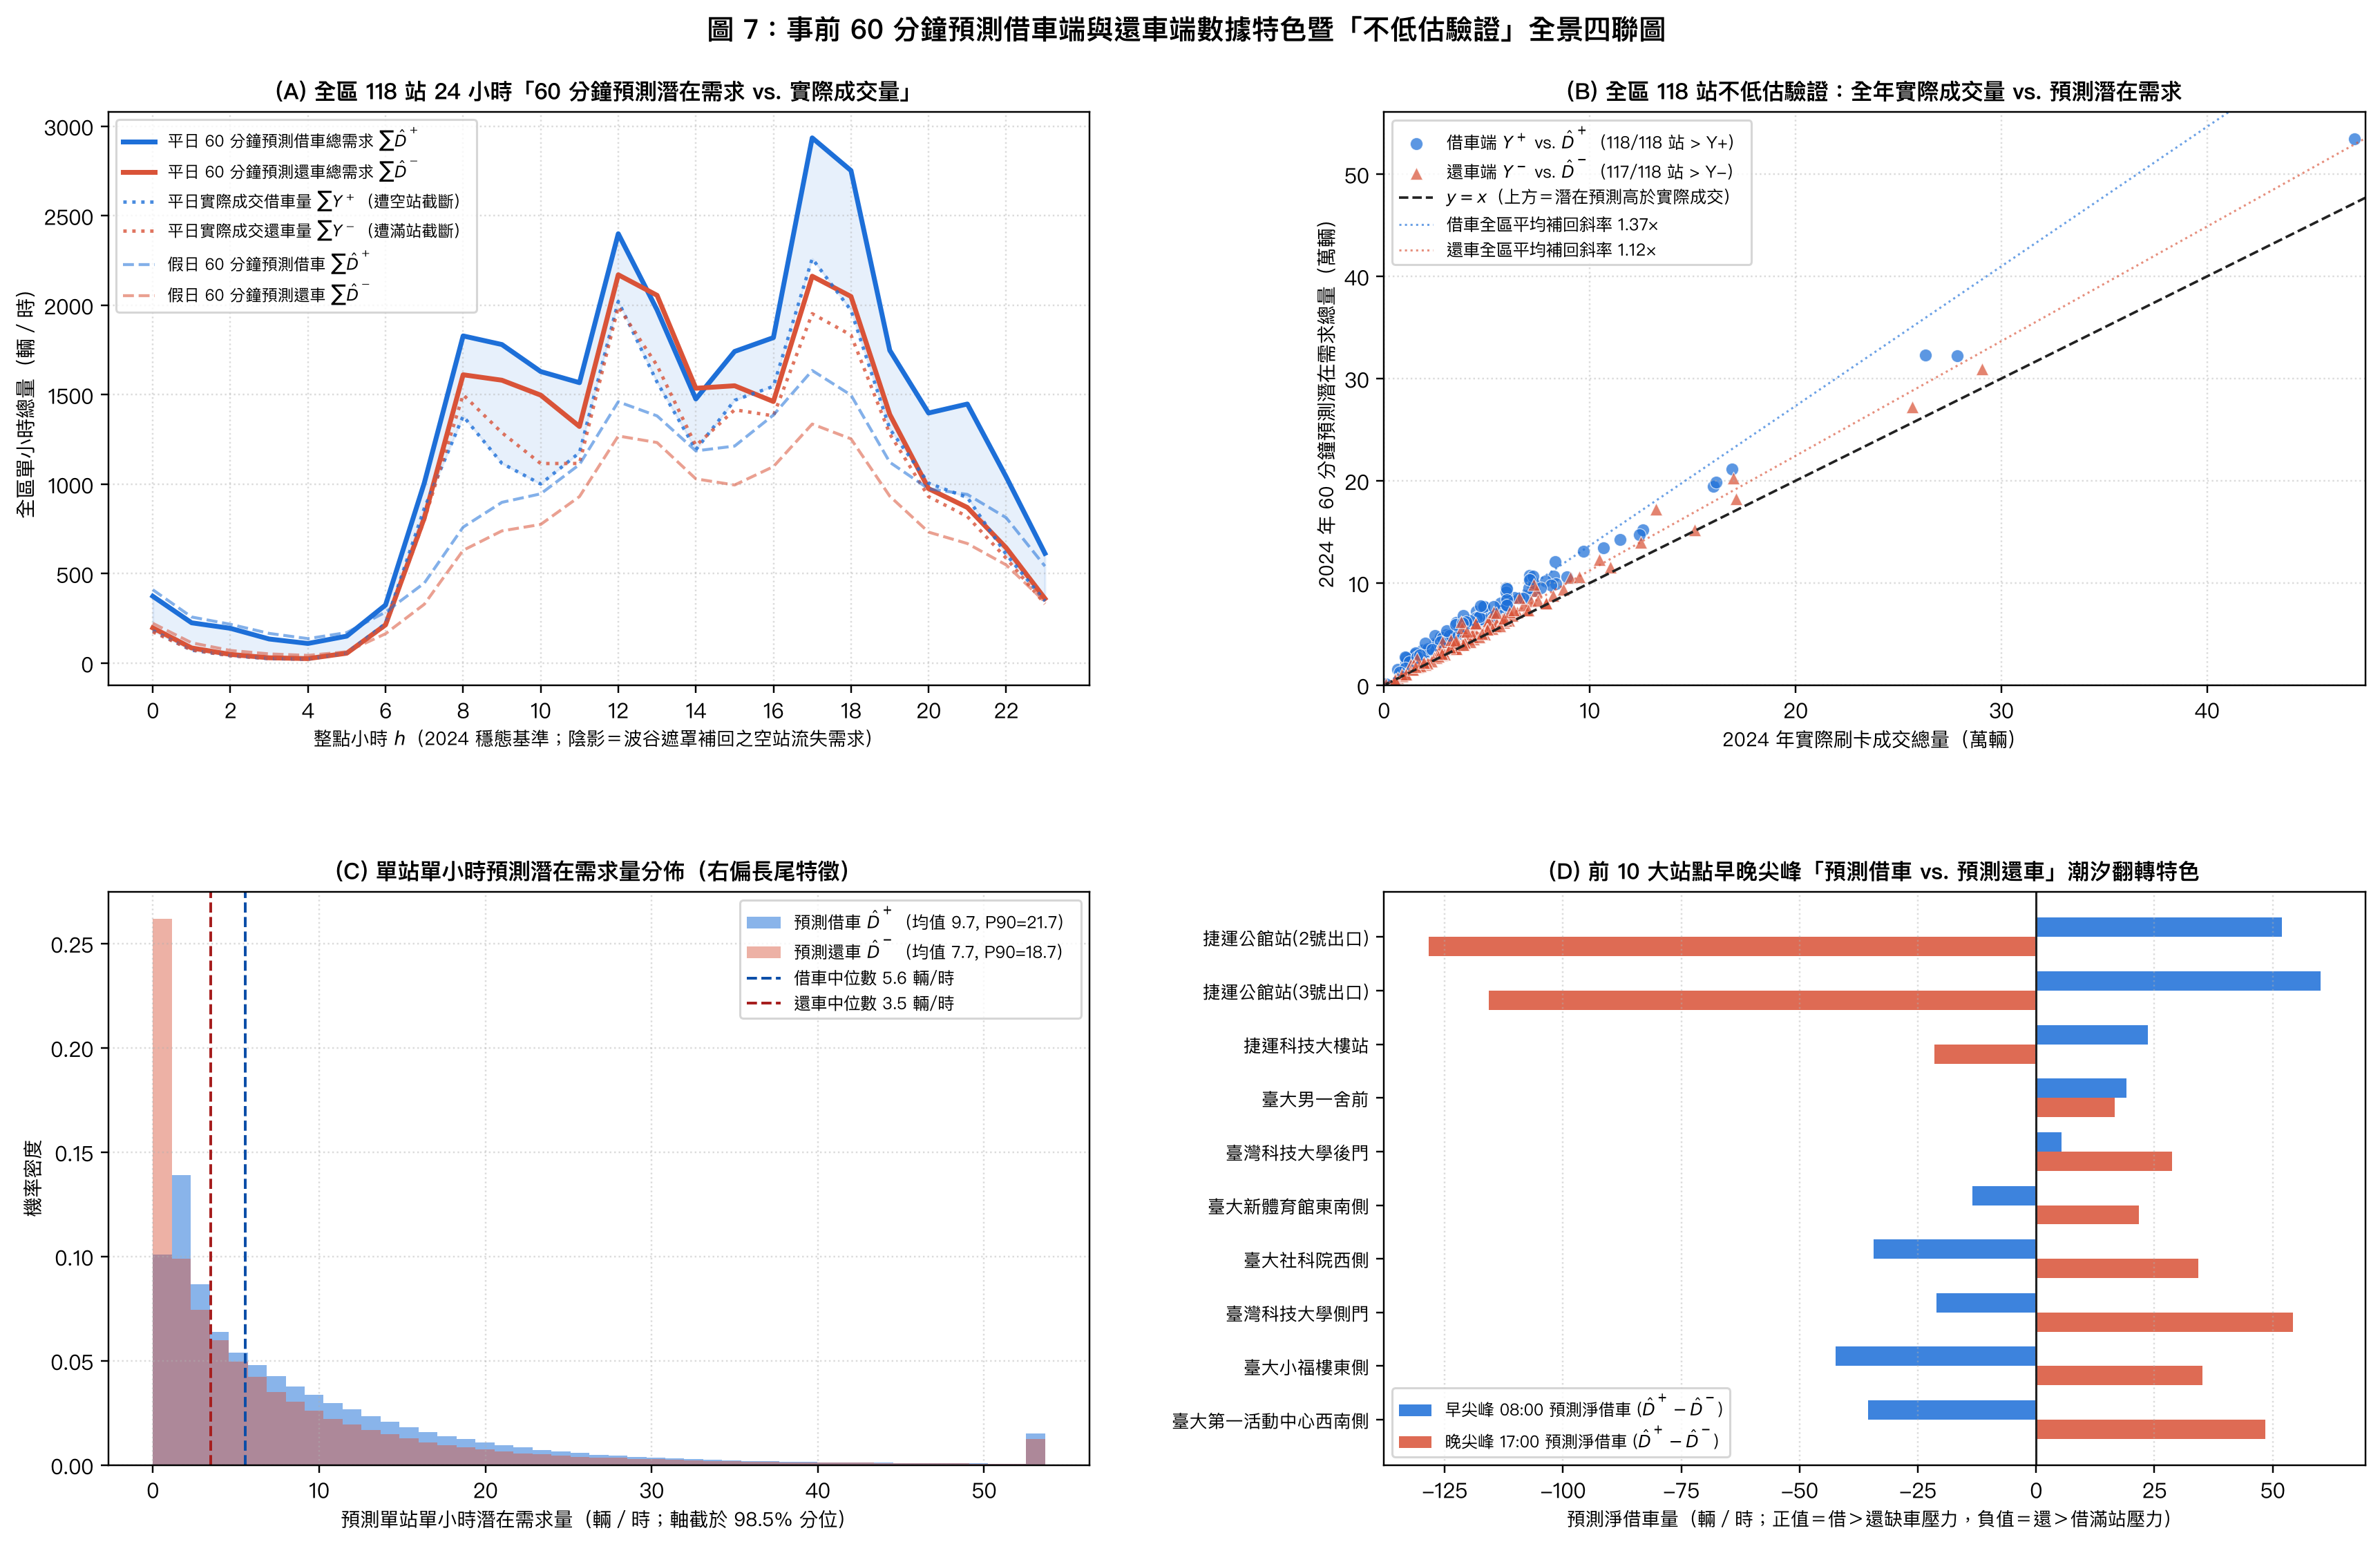

In [13]:
# === 表 6：事前 60 分鐘潛在需求驗證（完全不依賴未來暴露時間，對比實際刷卡成交數 Y+ / Y-） ===
# 1. 2024 In-Sample (all normal operational hours with complete weather, incl. exp == 0!)
ok24_full = (
    train_2024["is_full_normal_op"]
    & (~train_2024["is_tdx_blackout"])
    & train_2024["has_complete_weather"]
)
d24_all = train_2024[ok24_full].copy()
d24_all["lambda_pred"] = predict_rate_nb2_fe(mod_rent_2024, d24_all)
d24_all["mu_pred"] = predict_rate_nb2_fe(mod_ret_2024, d24_all)
d24_all["D60_rent"] = 60.0 * d24_all["lambda_pred"]
d24_all["D60_ret"] = 60.0 * d24_all["mu_pred"]

# 2. 2025 Out-of-Sample (all normal operational hours with complete weather & 118 common stations, incl. exp == 0!)
ok25_full = (
    test_2025["is_full_normal_op"]
    & (~test_2025["is_tdx_blackout"])
    & test_2025["has_complete_weather"]
    & test_2025["station_id"].isin(train_stations_2024)
)
d25_all = test_2025[ok25_full].copy()
d25_all["lambda_pred_raw"] = predict_rate_nb2_fe(mod_rent_2024, d25_all)
d25_all["mu_pred_raw"] = predict_rate_nb2_fe(mod_ret_2024, d25_all)
d25_all["D60_rent_raw"] = 60.0 * d25_all["lambda_pred_raw"]
d25_all["D60_ret_raw"] = 60.0 * d25_all["mu_pred_raw"]
d25_all["D60_rent_q1"] = d25_all["D60_rent_raw"] * scale_rent_nb_q1
d25_all["D60_ret_q1"] = d25_all["D60_ret_raw"] * scale_ret_nb_q1

def summarize_latent_verification(df_in: pd.DataFrame, d_rent_col: str, d_ret_col: str, period_lbl: str) -> list[dict]:
    subsets = [
        ("全體正常站時（含 exp=0）", np.ones(len(df_in), dtype=bool)),
        ("借車空站截斷時段（b=0）", df_in["trough_bikes"] == 0),
        ("借車未曾空站（b>=10）", df_in["trough_bikes"] >= 10),
        ("還車滿站截斷時段（Exp-<60）", df_in["exp_ret_eff"] < 60),
        ("還車未曾滿站（Exp-=60）", df_in["exp_ret_eff"] == 60),
    ]
    rows = []
    for sub_lbl, m in subsets:
        x = df_in[m]
        yr = float(x["y_rent"].sum())
        ym = float(x["y_ret"].sum())
        dr = float(x[d_rent_col].sum())
        dm = float(x[d_ret_col].sum())
        g_st = x.groupby("station_id").agg(yr=("y_rent", "sum"), dr=(d_rent_col, "sum"), ym=("y_ret", "sum"), dm=(d_ret_col, "sum"))
        rows.append({
            "評估口徑": period_lbl,
            "時段子集": sub_lbl,
            "站時數 N": len(x),
            "實借總量 Y+": int(round(yr)),
            "60分預測借車 D+": int(round(dr)),
            "借車倍數 (D+/Y+)": dr / max(yr, 1.0),
            "單時 D+>=Y+ (%)": 100.0 * float((x[d_rent_col] >= x["y_rent"]).mean()),
            "站數 D+>Y+ (/118)": int((g_st["dr"] > g_st["yr"]).sum()),
            "實還總量 Y-": int(round(ym)),
            "60分預測還車 D-": int(round(dm)),
            "還車倍數 (D-/Y-)": dm / max(ym, 1.0),
            "單時 D->=Y- (%)": 100.0 * float((x[d_ret_col] >= x["y_ret"]).mean()),
            "站數 D->Y- (/118)": int((g_st["dm"] > g_st["ym"]).sum()),
            "預測借還比 (D+/D-)": dr / max(dm, 1.0),
        })
    return rows

ver_rows = (
    summarize_latent_verification(d24_all, "D60_rent", "D60_ret", "2024 同年度（無跨年成長干擾）")
    + summarize_latent_verification(d25_all, "D60_rent_raw", "D60_ret_raw", "2025 樣本外（純 2024 權重，未校準）")
    + summarize_latent_verification(d25_all, "D60_rent_q1", "D60_ret_q1", "2025 樣本外（含 Q1 成長校準）")
)
ver_df = pd.DataFrame(ver_rows)
ver_df.to_csv(OUT_DIR / "latent_demand_60min_verification.csv", index=False)

print("=== 表 6：事前 60 分鐘潛在需求還原驗證表（完全不依賴未來暴露時間） ===")
display(ver_df)

# === 表 7：預測借車端 (D+) vs. 預測還車端 (D-) 數據分佈與結構特色對照（以 2024 同年度 & 2025 樣本外展示） ===
char_rows = []
for lbl_yr, df_c, rc, mc in [
    ("2024 訓練基準", d24_all, "D60_rent", "D60_ret"),
    ("2025 樣本外（純2024權重）", d25_all, "D60_rent_raw", "D60_ret_raw"),
    ("2025 樣本外（Q1校準）", d25_all, "D60_rent_q1", "D60_ret_q1"),
]:
    for side_lbl, col in [("預測借車 60*λ (輛/時)", rc), ("預測還車 60*μ (輛/時)", mc)]:
        s = df_c[col]
        wd1 = df_c.loc[df_c["weekday"] == 1, col].mean()
        wd0 = df_c.loc[df_c["weekday"] == 0, col].mean()
        sem1 = df_c.loc[df_c["semester"] == 1, col].mean()
        sem0 = df_c.loc[df_c["semester"] == 0, col].mean()
        p08 = df_c.loc[(df_c["weekday"] == 1) & (df_c["hour"] == 8), col].mean()
        p12 = df_c.loc[(df_c["weekday"] == 1) & (df_c["hour"] == 12), col].mean()
        p17 = df_c.loc[(df_c["weekday"] == 1) & (df_c["hour"] == 17), col].mean()
        char_rows.append({
            "資料年度": lbl_yr,
            "方向": side_lbl,
            "均值 (輛/時)": float(s.mean()),
            "標準差": float(s.std()),
            "中位數 (P50)": float(s.median()),
            "P75": float(s.quantile(0.75)),
            "P90": float(s.quantile(0.90)),
            "P99": float(s.quantile(0.99)),
            "最大值": float(s.max()),
            "平日/假日比": float(wd1 / max(wd0, 1e-9)),
            "學期/寒暑假比": float(sem1 / max(sem0, 1e-9)),
            "平日08時均值": float(p08),
            "平日12時均值": float(p12),
            "平日17時均值": float(p17),
        })
char_df = pd.DataFrame(char_rows)
char_df.to_csv(OUT_DIR / "predicted_rent_return_characteristics.csv", index=False)

print("\n=== 表 7：預測借車端 vs. 預測還車端 60 分鐘潛在需求分佈與特色比較 ===")
display(char_df)

# Export per-station predicted Rent vs Return profile (2024 & 2025)
st_map_s = stations_meta.set_index("station_id")["station_name_short"].to_dict()
st_prof = (
    d24_all.groupby("station_id")
    .agg(
        obs_rent_2024=("y_rent", "sum"),
        pred_D60_rent_2024=("D60_rent", "sum"),
        obs_ret_2024=("y_ret", "sum"),
        pred_D60_ret_2024=("D60_ret", "sum"),
    )
    .join(
        d25_all.groupby("station_id").agg(
            obs_rent_2025=("y_rent", "sum"),
            pred_D60_rent_2025_raw=("D60_rent_raw", "sum"),
            pred_D60_rent_2025_q1=("D60_rent_q1", "sum"),
            obs_ret_2025=("y_ret", "sum"),
            pred_D60_ret_2025_raw=("D60_ret_raw", "sum"),
            pred_D60_ret_2025_q1=("D60_ret_q1", "sum"),
        )
    )
    .reset_index()
)
st_prof.insert(1, "station_name", st_prof["station_id"].map(st_map_s))
st_prof["uplift_rent_2024"] = st_prof["pred_D60_rent_2024"] / st_prof["obs_rent_2024"]
st_prof["uplift_ret_2024"] = st_prof["pred_D60_ret_2024"] / st_prof["obs_ret_2024"]
st_prof.to_csv(OUT_DIR / "station_latent_demand_profile.csv", index=False)

# === 圖 7：預測借車端 vs. 預測還車端 60 分鐘潛在需求特色與「不低估驗證」四聯圖 ===
fig, axes = plt.subplots(2, 2, figsize=(16.5, 10.6))
fig.subplots_adjust(hspace=0.36, wspace=0.30, top=0.91, bottom=0.07, left=0.07, right=0.97)

# Panel A (Top-Left): System-wide 24-hour weekday vs weekend total predicted Rent vs Return (bikes/hr across 118 stations)
ax = axes[0, 0]
hrs = np.arange(24)
# Average across all days of 2024 (clean same-year benchmark without YoY drift)
h_wd1 = d24_all[d24_all["weekday"] == 1].groupby("hour")[["D60_rent", "D60_ret", "y_rent", "y_ret"]].mean() * 118.0
h_wd0 = d24_all[d24_all["weekday"] == 0].groupby("hour")[["D60_rent", "D60_ret"]].mean() * 118.0

ax.plot(hrs, h_wd1["D60_rent"], "-", color="#1D6FD8", linewidth=2.3, label="平日 60 分鐘預測借車總需求 $\\sum \\hat{D}^+$")
ax.plot(hrs, h_wd1["D60_ret"], "-", color="#D95338", linewidth=2.3, label="平日 60 分鐘預測還車總需求 $\\sum \\hat{D}^-$")
ax.plot(hrs, h_wd1["y_rent"], ":", color="#1D6FD8", linewidth=1.6, alpha=0.80, label="平日實際成交借車量 $\\sum Y^+$（遭空站截斷）")
ax.plot(hrs, h_wd1["y_ret"], ":", color="#D95338", linewidth=1.6, alpha=0.80, label="平日實際成交還車量 $\\sum Y^-$（遭滿站截斷）")
ax.plot(hrs, h_wd0["D60_rent"], "--", color="#1D6FD8", linewidth=1.4, alpha=0.55, label="假日 60 分鐘預測借車 $\\sum \\hat{D}^+$")
ax.plot(hrs, h_wd0["D60_ret"], "--", color="#D95338", linewidth=1.4, alpha=0.55, label="假日 60 分鐘預測還車 $\\sum \\hat{D}^-$")
ax.fill_between(hrs, h_wd1["y_rent"], h_wd1["D60_rent"], color="#1D6FD8", alpha=0.10)
ax.set_title("(A) 全區 118 站 24 小時「60 分鐘預測潛在需求 vs. 實際成交量」", fontsize=10.6, fontweight="bold")
ax.set_xlabel("整點小時 $h$（2024 穩態基準；陰影＝波谷遮罩補回之空站流失需求）", fontsize=8.8)
ax.set_ylabel("全區單小時總量（輛／時）", fontsize=9.5)
ax.set_xticks(range(0, 24, 2))
ax.legend(fontsize=7.6, loc="upper left", frameon=True)
ax.grid(True, linestyle=":", alpha=0.45)

# Panel B (Top-Right): Per-station 118-station verification scatter (Observed annual Y vs Predicted annual 60-min D)
ax = axes[0, 1]
max_val = max(st_prof["pred_D60_rent_2024"].max(), st_prof["pred_D60_ret_2024"].max()) / 1e4 * 1.05
ax.scatter(st_prof["obs_rent_2024"] / 1e4, st_prof["pred_D60_rent_2024"] / 1e4, s=36, color="#1D6FD8", alpha=0.72, edgecolors="white", linewidth=0.4, label="借車端 $Y^+$ vs. $\\hat{D}^+$（118/118 站 > Y+）")
ax.scatter(st_prof["obs_ret_2024"] / 1e4, st_prof["pred_D60_ret_2024"] / 1e4, s=36, color="#D95338", marker="^", alpha=0.72, edgecolors="white", linewidth=0.4, label="還車端 $Y^-$ vs. $\\hat{D}^-$（117/118 站 > Y-）")
ax.plot([0, max_val], [0, max_val], "--", color="#222222", linewidth=1.2, label="$y = x$（上方＝潛在預測高於實際成交）")
ax.plot([0, max_val], [0, 1.366 * max_val], ":", color="#1D6FD8", linewidth=1.0, alpha=0.65, label="借車全區平均補回斜率 1.37×")
ax.plot([0, max_val], [0, 1.122 * max_val], ":", color="#D95338", linewidth=1.0, alpha=0.65, label="還車全區平均補回斜率 1.12×")
ax.set_xlim(0, max_val * 0.85)
ax.set_ylim(0, max_val)
ax.set_title("(B) 全區 118 站不低估驗證：全年實際成交量 vs. 預測潛在需求", fontsize=10.6, fontweight="bold")
ax.set_xlabel("2024 年實際刷卡成交總量（萬輛）", fontsize=9.2)
ax.set_ylabel("2024 年 60 分鐘預測潛在需求總量（萬輛）", fontsize=9.2)
ax.legend(fontsize=8.0, loc="upper left", frameon=True)
ax.grid(True, linestyle=":", alpha=0.45)

# Panel C (Bottom-Left): Hourly predicted demand distribution (Rent vs Return, log-x density / histogram + quantiles)
ax = axes[1, 0]
s_rent_c = d24_all["D60_rent"].dropna()
s_ret_c = d24_all["D60_ret"].dropna()
cap_d = float(np.nanquantile(np.concatenate([s_rent_c.to_numpy(), s_ret_c.to_numpy()]), 0.985))
bins_d = np.linspace(0.0, cap_d, 48)
ax.hist(s_rent_c.clip(upper=cap_d), bins=bins_d, density=True, alpha=0.52, color="#1D6FD8", label=f"預測借車 $\\hat{{D}}^+$（均值 {s_rent_c.mean():.1f}, P90={s_rent_c.quantile(0.9):.1f}）")
ax.hist(s_ret_c.clip(upper=cap_d), bins=bins_d, density=True, alpha=0.45, color="#D95338", label=f"預測還車 $\\hat{{D}}^-$（均值 {s_ret_c.mean():.1f}, P90={s_ret_c.quantile(0.9):.1f}）")
ax.axvline(d24_all["D60_rent"].median(), color="#0B4EA8", linestyle="--", linewidth=1.3, label=f"借車中位數 {d24_all['D60_rent'].median():.1f} 輛/時")
ax.axvline(d24_all["D60_ret"].median(), color="#A61E1E", linestyle="--", linewidth=1.3, label=f"還車中位數 {d24_all['D60_ret'].median():.1f} 輛/時")
ax.set_title("(C) 單站單小時預測潛在需求量分佈（右偏長尾特徵）", fontsize=10.6, fontweight="bold")
ax.set_xlabel("預測單站單小時潛在需求量（輛／時；軸截於 98.5% 分位）", fontsize=9.2)
ax.set_ylabel("機率密度", fontsize=9.2)
ax.legend(fontsize=8.0, loc="upper right", frameon=True)
ax.grid(True, linestyle=":", alpha=0.45)

# Panel D (Bottom-Right): Top-10 Hub Stations — Morning 08:00 vs Evening 17:00 Predicted Rent vs Return
ax = axes[1, 1]
top10_sids = st_prof.sort_values("pred_D60_rent_2024", ascending=False).head(10)["station_id"].tolist()
p_am = d24_all[(d24_all["weekday"] == 1) & (d24_all["hour"] == 8) & (d24_all["station_id"].isin(top10_sids))].groupby("station_id")[["D60_rent", "D60_ret"]].mean()
p_pm = d24_all[(d24_all["weekday"] == 1) & (d24_all["hour"] == 17) & (d24_all["station_id"].isin(top10_sids))].groupby("station_id")[["D60_rent", "D60_ret"]].mean()
# Net predicted tidal flow (Rent - Return) at 08:00 vs 17:00
net_am = (p_am["D60_rent"] - p_am["D60_ret"]).reindex(top10_sids)
net_pm = (p_pm["D60_rent"] - p_pm["D60_ret"]).reindex(top10_sids)
ord10 = (net_am - net_pm).sort_values(ascending=True).index.tolist()
net_am = net_am.reindex(ord10)
net_pm = net_pm.reindex(ord10)
y10 = np.arange(len(ord10))
h_bar = 0.36
ax.barh(y10 + h_bar / 2, net_am.to_numpy(), height=h_bar, color="#1D6FD8", alpha=0.86, label="早尖峰 08:00 預測淨借車 ($\\hat{D}^+ - \\hat{D}^-$)")
ax.barh(y10 - h_bar / 2, net_pm.to_numpy(), height=h_bar, color="#D95338", alpha=0.86, label="晚尖峰 17:00 預測淨借車 ($\\hat{D}^+ - \\hat{D}^-$)")
ax.axvline(0.0, color="#222222", linewidth=1.0)
ax.set_yticks(y10)
ax.set_yticklabels([st_map_s[s] for s in ord10], fontsize=8.4)
ax.set_xlabel("預測淨借車量（輛／時；正值＝借＞還缺車壓力，負值＝還＞借滿站壓力）", fontsize=8.8)
ax.set_title("(D) 前 10 大站點早晚尖峰「預測借車 vs. 預測還車」潮汐翻轉特色", fontsize=10.4, fontweight="bold")
ax.legend(fontsize=7.8, loc="lower left", frameon=True)
ax.grid(True, axis="x", linestyle=":", alpha=0.45)

fig.suptitle("圖 7：事前 60 分鐘預測借車端與還車端數據特色暨「不低估驗證」全景四聯圖", fontsize=13.0, fontweight="bold", y=0.97)
fig.savefig(FIG_DIR / "fig_predicted_rent_vs_return_characteristics.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig_predicted_rent_vs_return_characteristics.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)


## 3. 多維度站點時段全景熱圖與「各變數誤差歸因」診斷看板

為直觀檢視「站點 $\times$ 24 小時 $\times$ 借還潮汐 $\times$ 預測偏差」之高維結構，並具體拆解 2025 樣本外誤差究竟由哪些環境／校曆變數與突變站點所驅動，本節繪製：
- **圖 5**：前 25 大主力站點（依早晚潮汐角色自動排序）$\times$ 24 小時之「真實借車強度」、「淨流量潮汐方向」與「2025 結構性預測偏差」三聯對位熱圖；
- **圖 6**：代表性 3 大站點 24 小時實測 vs. 預測波形、各變數區間結構性預測偏差歸因條形圖、全區 118 站單站預測體檢散佈圖，以及 2025 年 1–12 月月度走勢對照。


findfont: Failed to find font weight bold for PingFang TC, now using 600.


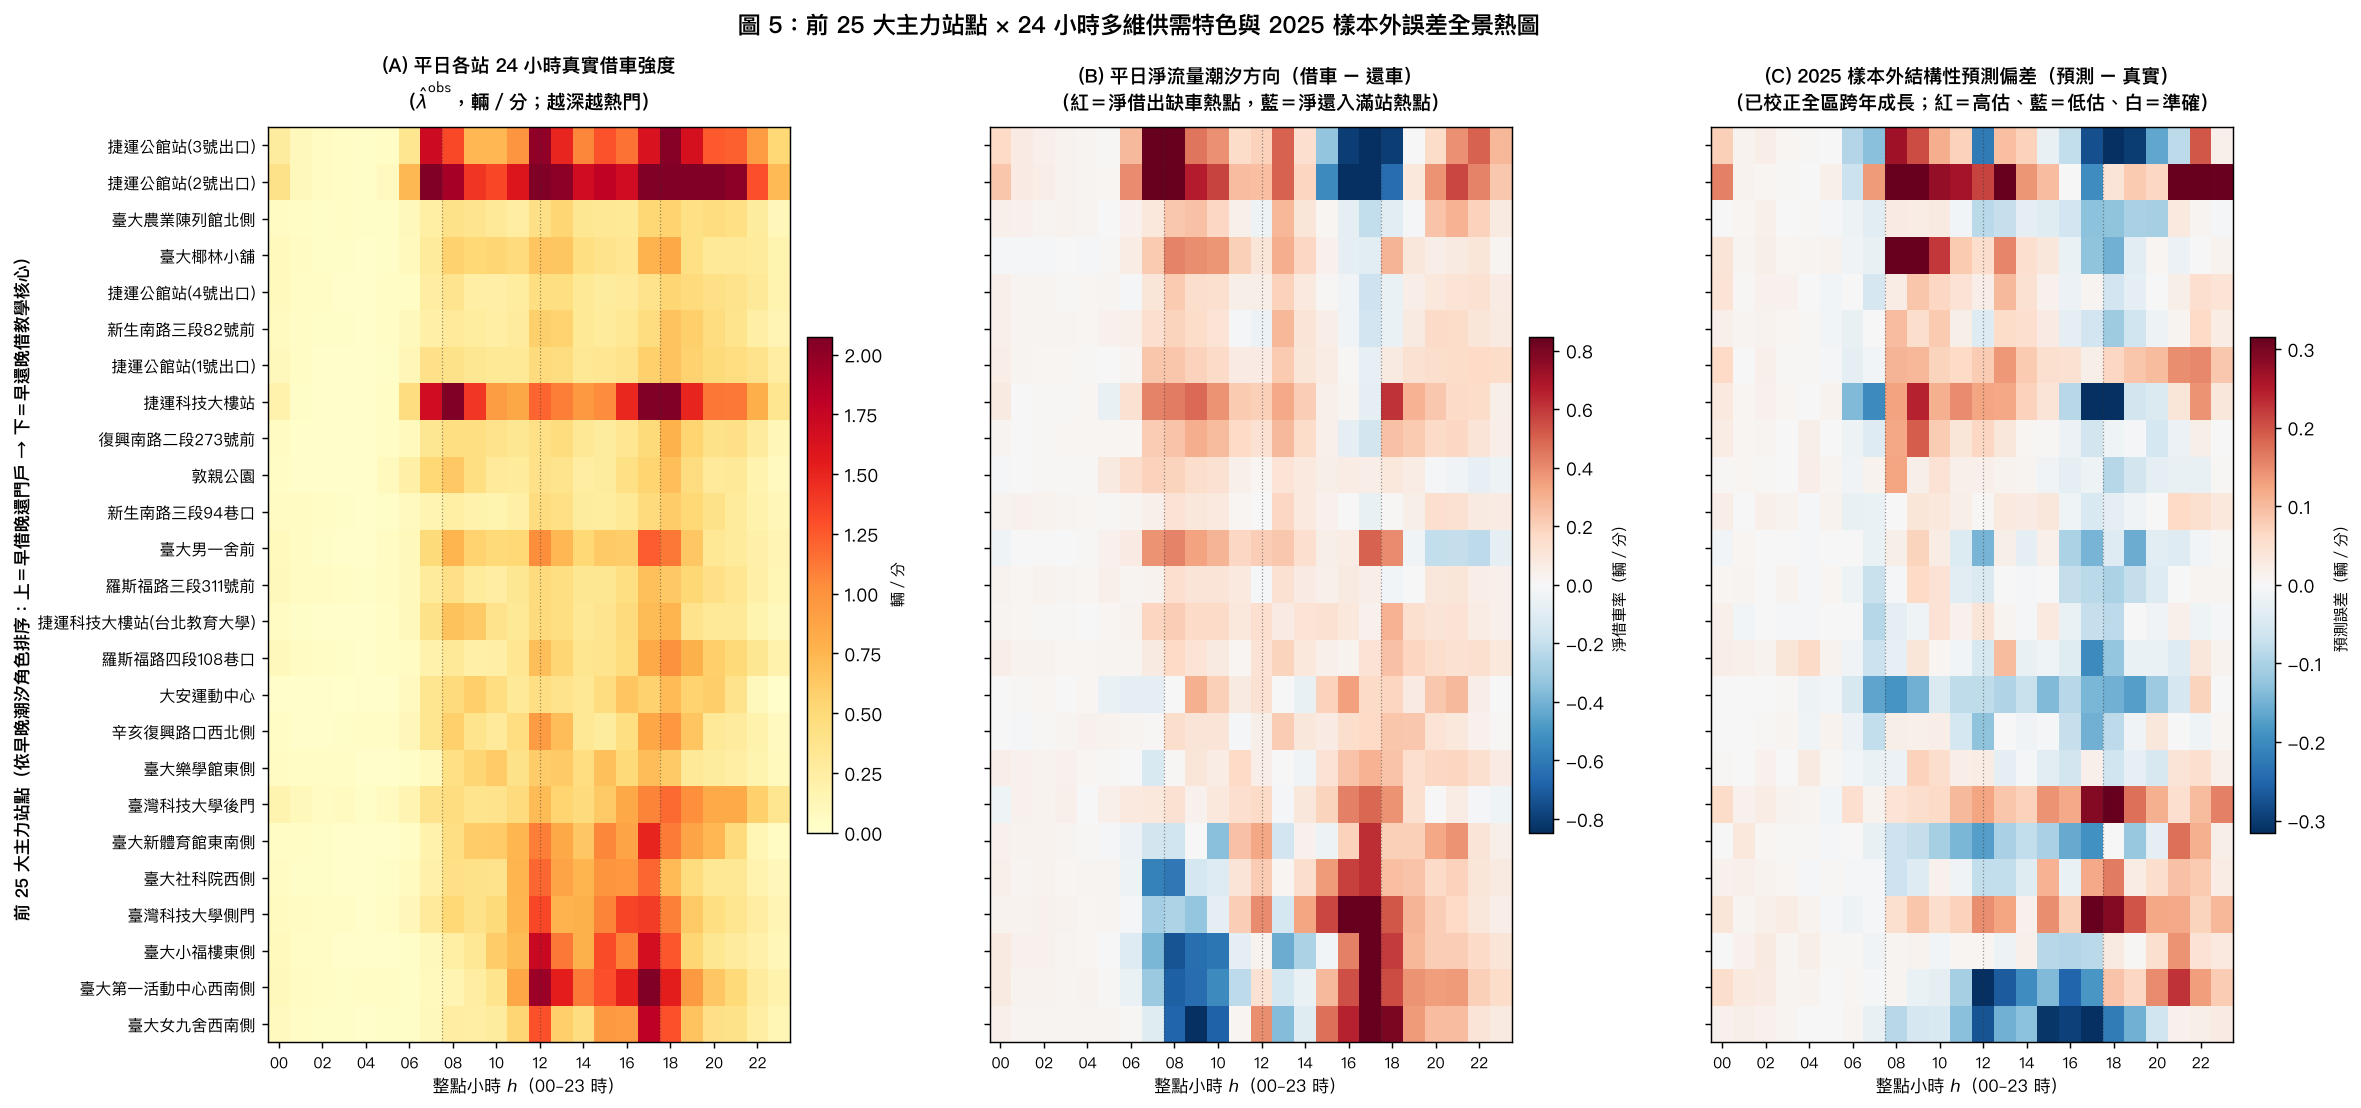

findfont: Failed to find font weight bold for PingFang TC, now using 600.


findfont: Failed to find font weight bold for PingFang TC, now using 600.


findfont: Failed to find font weight bold for PingFang TC, now using 600.


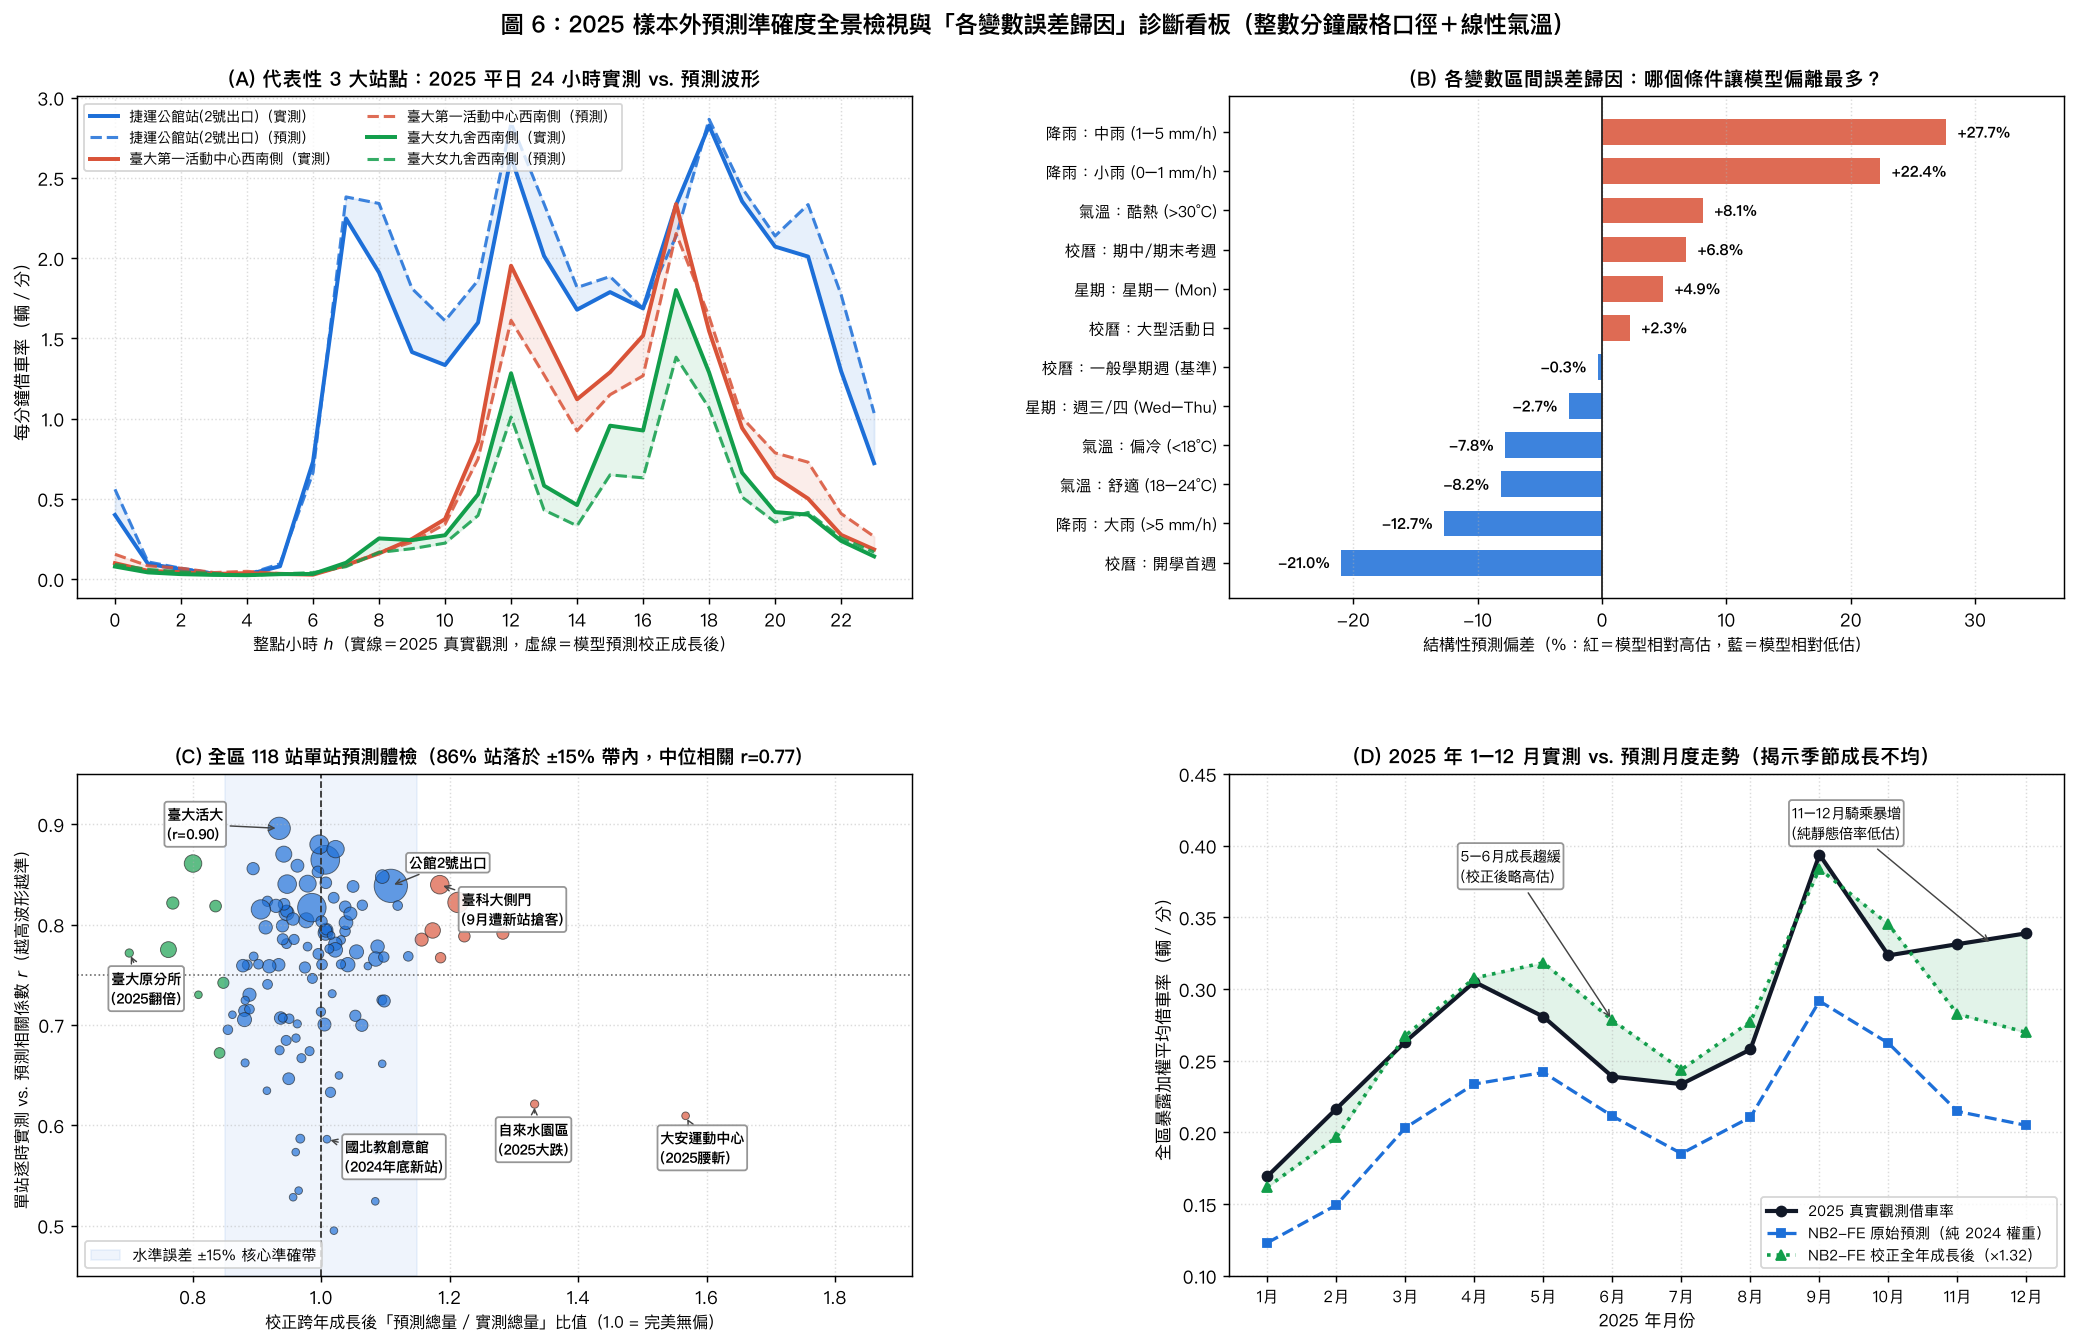

全部圖表與資料資產已同步更新並內嵌顯示（共 29 檔）。


In [14]:
from matplotlib.colors import TwoSlopeNorm

st_map_fig = stations_meta.set_index("station_id")["station_name_short"].to_dict()
oos_fig = oos_2025_df.copy()
oos_fig["station_id"] = oos_fig["station_id"].astype(str)
oos_fig["short_name"] = oos_fig["station_id"].map(st_map_fig).fillna(oos_fig["station_id"])
oos_fig["month"] = pd.to_datetime(oos_fig["date"]).dt.month
oos_fig["dow"] = pd.to_datetime(oos_fig["date"]).dt.dayofweek

rent_f = oos_fig[oos_fig["valid_rent"] & oos_fig["lambda_pred_nb_raw"].notna()].copy()
ret_f = oos_fig[oos_fig["valid_ret"] & oos_fig["mu_pred_nb_raw"].notna()].copy()

g_scale_rent = float(rent_f["y_rent"].sum() / np.sum(rent_f["lambda_pred_nb_raw"] * rent_f["exp_rent_eff"]))
rent_f["pred_aligned"] = rent_f["lambda_pred_nb_raw"] * g_scale_rent

# === 圖 5：前 25 大主力站點 × 24 小時多維供需特色與 2025 樣本外誤差全景熱圖 ===
top25_sids = rent_f.groupby("station_id")["y_rent"].sum().nlargest(25).index.tolist()
rent_wd = rent_f[(rent_f["weekday"] == 1) & (rent_f["station_id"].isin(top25_sids))]
ret_wd = ret_f[(ret_f["weekday"] == 1) & (ret_f["station_id"].isin(top25_sids))]

def agg_rate_f(df_in, y_c, e_c, p_c=None):
    return df_in.groupby(["station_id", "hour"]).apply(
        lambda x: pd.Series({
            "obs": x[y_c].sum() / x[e_c].sum(),
            "pred": (x[p_c] * x[e_c]).sum() / x[e_c].sum() if p_c else np.nan,
        }),
        include_groups=False,
    )

g_r = agg_rate_f(rent_wd, "y_rent", "exp_rent_eff", "pred_aligned")
g_m = agg_rate_f(ret_wd, "y_ret", "exp_ret_eff")

mat_obs = g_r["obs"].unstack("hour").reindex(columns=range(24)).fillna(0.0)
mat_pred = g_r["pred"].unstack("hour").reindex(columns=range(24)).fillna(0.0)
mat_ret = g_m["obs"].unstack("hour").reindex(columns=range(24)).fillna(0.0)
mat_net = mat_obs - mat_ret
mat_err = mat_pred - mat_obs

tidal_score = mat_net[[7, 8, 9]].mean(axis=1) - mat_net[[17, 18, 19]].mean(axis=1)
order_sids = tidal_score.sort_values(ascending=False).index.tolist()

mat_obs = mat_obs.loc[order_sids]
mat_net = mat_net.loc[order_sids]
mat_err = mat_err.loc[order_sids]
ylabels = [st_map_fig[s] for s in order_sids]

fig, axes = plt.subplots(1, 3, figsize=(18.6, 8.8), sharey=True, gridspec_kw={"wspace": 0.28})

im0 = axes[0].imshow(mat_obs.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=np.quantile(mat_obs.to_numpy(), 0.985))
axes[0].set_title("(A) 平日各站 24 小時真實借車強度\n（$\\hat{\\lambda}^{\\mathrm{obs}}$，輛／分；越深越熱門）", fontsize=10.5, fontweight="bold", pad=10)
cb0 = fig.colorbar(im0, ax=axes[0], fraction=0.044, pad=0.03)
cb0.set_label("輛／分", fontsize=8.5)

vmax_net = float(np.quantile(np.abs(mat_net.to_numpy()), 0.98))
im1 = axes[1].imshow(mat_net.to_numpy(), aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-vmax_net, vcenter=0.0, vmax=vmax_net))
axes[1].set_title("(B) 平日淨流量潮汐方向（借車 − 還車）\n（紅＝淨借出缺車熱點，藍＝淨還入滿站熱點）", fontsize=10.5, fontweight="bold", pad=10)
cb1 = fig.colorbar(im1, ax=axes[1], fraction=0.044, pad=0.03)
cb1.set_label("淨借車率（輛／分）", fontsize=8.5)

vmax_err = float(np.quantile(np.abs(mat_err.to_numpy()), 0.98))
im2 = axes[2].imshow(mat_err.to_numpy(), aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-vmax_err, vcenter=0.0, vmax=vmax_err))
axes[2].set_title("(C) 2025 樣本外結構性預測偏差（預測 − 真實）\n（已校正全區跨年成長；紅＝高估、藍＝低估、白＝準確）", fontsize=10.5, fontweight="bold", pad=10)
cb2 = fig.colorbar(im2, ax=axes[2], fraction=0.044, pad=0.03)
cb2.set_label("預測誤差（輛／分）", fontsize=8.5)

for ax in axes:
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)], fontsize=8.5)
    ax.set_xlabel("整點小時 $h$（00–23 時）", fontsize=9.5)
    ax.axvline(7.5, color="#333333", linestyle=":", linewidth=0.7, alpha=0.5)
    ax.axvline(12.0, color="#333333", linestyle=":", linewidth=0.7, alpha=0.5)
    ax.axvline(17.5, color="#333333", linestyle=":", linewidth=0.7, alpha=0.5)

axes[0].set_yticks(range(len(ylabels)))
axes[0].set_yticklabels(ylabels, fontsize=8.8)
axes[0].set_ylabel("前 25 大主力站點（依早晚潮汐角色排序：上＝早借晚還門戶 → 下＝早還晚借教學核心）", fontsize=9.5, fontweight="bold")

fig.suptitle("圖 5：前 25 大主力站點 × 24 小時多維供需特色與 2025 樣本外誤差全景熱圖", fontsize=13.0, fontweight="bold", y=0.98)
fig.subplots_adjust(top=0.88, left=0.14, right=0.97, bottom=0.08)
fig.savefig(FIG_DIR / "fig_station_hour_multidim_heatmap.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig_station_hour_multidim_heatmap.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

# === 圖 6：2025 樣本外預測準確度全景檢視與「各變數誤差歸因」四格診斷看板 ===
fig, axes = plt.subplots(2, 2, figsize=(16.8, 10.8))
fig.subplots_adjust(hspace=0.35, wspace=0.38, top=0.91, bottom=0.07, left=0.06, right=0.97)

ax = axes[0, 0]
rep_stations = [
    ("500101022", "捷運公館站(2號出口)", "#1D6FD8"),
    ("500119075", "臺大第一活動中心西南側", "#D95338"),
    ("500119049", "臺大女九舍西南側", "#129E4B"),
]
hrs = np.arange(24)
for sid, lbl, col in rep_stations:
    s = rent_f[(rent_f["station_id"] == sid) & (rent_f["weekday"] == 1)]
    g = s.groupby("hour").apply(
        lambda x: pd.Series({
            "obs": x["y_rent"].sum() / x["exp_rent_eff"].sum(),
            "pred_al": (x["pred_aligned"] * x["exp_rent_eff"]).sum() / x["exp_rent_eff"].sum(),
        }),
        include_groups=False,
    ).reindex(hrs)
    ax.plot(hrs, g["obs"], "-", color=col, linewidth=2.2, label=f"{lbl}（實測）")
    ax.plot(hrs, g["pred_al"], "--", color=col, linewidth=1.7, alpha=0.85, label=f"{lbl}（預測）")
    ax.fill_between(hrs, g["obs"], g["pred_al"], color=col, alpha=0.10)
ax.set_title("(A) 代表性 3 大站點：2025 平日 24 小時實測 vs. 預測波形", fontsize=10.8, fontweight="bold")
ax.set_xlabel("整點小時 $h$（實線＝2025 真實觀測，虛線＝模型預測校正成長後）", fontsize=9.0)
ax.set_ylabel("每分鐘借車率（輛／分）", fontsize=9.5)
ax.set_xticks(range(0, 24, 2))
ax.legend(fontsize=7.8, ncol=2, loc="upper left", frameon=True)
ax.grid(True, linestyle=":", alpha=0.45)

ax = axes[0, 1]
rent_f["rain_bin"] = pd.cut(rent_f["rain_1h_mm"], bins=[-0.1, 0.0, 1.0, 5.0, 100.0], labels=["無雨 (0mm)", "小雨 (0-1mm)", "中雨 (1-5mm)", "大雨 (>5mm)"])
rent_f["temp_bin"] = pd.cut(rent_f["Temp"], bins=[0, 18, 24, 30, 50], labels=["氣溫偏冷 (<18°C)", "氣溫舒適 (18-24°C)", "氣溫偏暖 (24-30°C)", "氣溫酷熱 (>30°C)"])
rent_f["cal_stage"] = np.select(
    [rent_f["semester"] == 0, rent_f["opening"] == 1, rent_f["exam"] == 1, rent_f["event"] == 1],
    ["寒暑假", "開學首週", "期中/期末考週", "大型活動日"],
    default="一般學期週",
)

attr_items = [
    ("降雨：中雨 (1–5 mm/h)", rent_f["rain_bin"] == "中雨 (1-5mm)"),
    ("降雨：小雨 (0–1 mm/h)", rent_f["rain_bin"] == "小雨 (0-1mm)"),
    ("氣溫：酷熱 (>30°C)", rent_f["temp_bin"] == "氣溫酷熱 (>30°C)"),
    ("校曆：期中/期末考週", rent_f["cal_stage"] == "期中/期末考週"),
    ("星期：星期一 (Mon)", rent_f["dow"] == 0),
    ("校曆：大型活動日", rent_f["cal_stage"] == "大型活動日"),
    ("校曆：一般學期週 (基準)", rent_f["cal_stage"] == "一般學期週"),
    ("星期：週三/四 (Wed–Thu)", rent_f["dow"].isin([2, 3])),
    ("氣溫：偏冷 (<18°C)", rent_f["temp_bin"] == "氣溫偏冷 (<18°C)"),
    ("氣溫：舒適 (18–24°C)", rent_f["temp_bin"] == "氣溫舒適 (18-24°C)"),
    ("降雨：大雨 (>5 mm/h)", rent_f["rain_bin"] == "大雨 (>5mm)"),
    ("校曆：開學首週", rent_f["cal_stage"] == "開學首週"),
]
labels_b, biases_b = [], []
for lbl, mask in attr_items:
    x = rent_f[mask]
    b_pct = ((x["pred_aligned"] * x["exp_rent_eff"]).sum() / x["y_rent"].sum() - 1.0) * 100.0
    labels_b.append(lbl)
    biases_b.append(b_pct)

order_b = np.argsort(biases_b)
labels_b = [labels_b[i] for i in order_b]
biases_b = [biases_b[i] for i in order_b]
colors_b = ["#D95338" if v > 0 else "#1D6FD8" for v in biases_b]
y_pos = np.arange(len(labels_b))
bars = ax.barh(y_pos, biases_b, color=colors_b, height=0.66, alpha=0.86)
ax.axvline(0.0, color="#222222", linewidth=1.0)
for bar, val in zip(bars, biases_b):
    offset = 0.9 if val >= 0 else -0.9
    ha = "left" if val >= 0 else "right"
    ax.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.1f}%", va="center", ha=ha, fontsize=8.4, fontweight="bold")
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_b, fontsize=8.6)
ax.set_xlim(min(biases_b) - 9.0, max(biases_b) + 9.5)
ax.set_xlabel("結構性預測偏差（%：紅＝模型相對高估，藍＝模型相對低估）", fontsize=9.0)
ax.set_title("(B) 各變數區間誤差歸因：哪個條件讓模型偏離最多？", fontsize=10.8, fontweight="bold")
ax.grid(True, axis="x", linestyle=":", alpha=0.45)

ax = axes[1, 0]
st_stats = rent_f.groupby(["station_id", "short_name"]).apply(
    lambda x: pd.Series({
        "sum_y": x["y_rent"].sum(),
        "ratio_al": (x["pred_aligned"] * x["exp_rent_eff"]).sum() / max(x["y_rent"].sum(), 1),
        "corr_y": np.corrcoef(x["y_rent"], x["pred_aligned"] * x["exp_rent_eff"])[0, 1] if x["y_rent"].std() > 0 else np.nan,
    }),
    include_groups=False,
).reset_index()

sizes = np.clip(st_stats["sum_y"] / 1400.0, 18, 340)
sc_col = np.where(np.abs(st_stats["ratio_al"] - 1.0) <= 0.15, "#1D6FD8", np.where(st_stats["ratio_al"] > 1.15, "#D95338", "#129E4B"))
ax.scatter(st_stats["ratio_al"], st_stats["corr_y"], s=sizes, c=sc_col, alpha=0.68, edgecolors="#222222", linewidth=0.5)
ax.axvline(1.0, color="#333333", linestyle="--", linewidth=1.0)
ax.axvspan(0.85, 1.15, color="#1D6FD8", alpha=0.07, label="水準誤差 ±15% 核心準確帶")
ax.axhline(0.75, color="#666666", linestyle=":", linewidth=0.9)

annot_specs = {
    "500101015": ("大安運動中心\n(2025腰斬)", (-14, -26)),
    "500106090": ("自來水園區\n(2025大跌)", (-20, -28)),
    "500101025": ("臺科大側門\n(9月遭新站搶客)", (12, -22)),
    "500119072": ("臺大原分所\n(2025翻倍)", (-10, -28)),
    "500101250": ("國北教創意館\n(2024年底新站)", (10, -18)),
    "500119075": ("臺大活大\n(r=0.90)", (-62, -6)),
    "500101022": ("公館2號出口", (10, 10)),
}
for sid, (txt, dxy) in annot_specs.items():
    row = st_stats[st_stats["station_id"] == sid]
    if len(row):
        r0 = row.iloc[0]
        ax.annotate(
            txt, xy=(r0["ratio_al"], r0["corr_y"]), xytext=dxy,
            textcoords="offset points", fontsize=7.8, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#888888", alpha=0.88),
            arrowprops=dict(arrowstyle="->", color="#444444", lw=0.8),
        )

pct_in_band = 100.0 * (np.abs(st_stats["ratio_al"] - 1.0) <= 0.15).mean()
med_r = st_stats["corr_y"].median()
ax.set_title(f"(C) 全區 118 站單站預測體檢（{pct_in_band:.0f}% 站落於 ±15% 帶內，中位相關 r={med_r:.2f}）", fontsize=10.5, fontweight="bold")
ax.set_xlabel("校正跨年成長後「預測總量 / 實測總量」比值（1.0 = 完美無偏）", fontsize=9.0)
ax.set_ylabel("單站逐時實測 vs. 預測相關係數 $r$（越高波形越準）", fontsize=9.0)
ax.set_xlim(0.62, 1.92)
ax.set_ylim(0.45, 0.95)
ax.legend(loc="lower left", fontsize=8.3, frameon=True)
ax.grid(True, linestyle=":", alpha=0.45)

ax = axes[1, 1]
mo = rent_f.groupby("month").apply(
    lambda x: pd.Series({
        "obs": x["y_rent"].sum() / x["exp_rent_eff"].sum(),
        "pred_raw": (x["lambda_pred_nb_raw"] * x["exp_rent_eff"]).sum() / x["exp_rent_eff"].sum(),
        "pred_al": (x["pred_aligned"] * x["exp_rent_eff"]).sum() / x["exp_rent_eff"].sum(),
    }),
    include_groups=False,
)
months = np.arange(1, 13)
ax.plot(months, mo["obs"], "o-", color="#111827", linewidth=2.3, markersize=5.5, label="2025 真實觀測借車率")
ax.plot(months, mo["pred_raw"], "s--", color="#1D6FD8", linewidth=1.8, markersize=4.8, label="NB2-FE 原始預測（純 2024 權重）")
ax.plot(months, mo["pred_al"], "^:", color="#129E4B", linewidth=2.0, markersize=5.2, label=f"NB2-FE 校正全年成長後（×{g_scale_rent:.2f}）")
ax.fill_between(months, mo["obs"], mo["pred_al"], color="#129E4B", alpha=0.12)
ax.annotate("5–6月成長趨緩\n(校正後略高估)", xy=(6, mo.loc[6, "pred_al"]), xytext=(3.8, 0.375),
            fontsize=8.0, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#888888", alpha=0.88),
            arrowprops=dict(arrowstyle="->", color="#444444", lw=0.8))
ax.annotate("11–12月騎乘暴增\n(純靜態倍率低估)", xy=(11.5, mo.loc[11, "obs"]), xytext=(8.6, 0.405),
            fontsize=8.0, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#888888", alpha=0.88),
            arrowprops=dict(arrowstyle="->", color="#444444", lw=0.8))
ax.set_title("(D) 2025 年 1–12 月實測 vs. 預測月度走勢（揭示季節成長不均）", fontsize=10.8, fontweight="bold")
ax.set_xlabel("2025 年月份", fontsize=9.5)
ax.set_ylabel("全區暴露加權平均借車率（輛／分）", fontsize=9.5)
ax.set_xticks(months)
ax.set_xticklabels([f"{m}月" for m in months], fontsize=8.8)
ax.set_ylim(0.10, 0.45)
ax.legend(loc="lower right", fontsize=8.2, frameon=True)
ax.grid(True, linestyle=":", alpha=0.45)

fig.suptitle("圖 6：2025 樣本外預測準確度全景檢視與「各變數誤差歸因」診斷看板（整數分鐘嚴格口徑＋線性氣溫）", fontsize=13.0, fontweight="bold", y=0.97)
fig.savefig(FIG_DIR / "fig_error_attribution_by_variable.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig_error_attribution_by_variable.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

# Refresh manifest.json to include all newly exported tables and Figures 5–7
manifest["output_files"] = sorted(str(p.relative_to(OUT_DIR)) for p in OUT_DIR.rglob("*") if p.is_file())
(OUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"全部圖表與資料資產已同步更新並內嵌顯示（共 {len(manifest['output_files'])} 檔）。")
